# Task 21 · Natural Language Processing with RNNs & Attention
### From a Char-RNN to the Transformer – eight phases, 14 exercises, three capstones

**What this notebook does.** It follows the Task 21 brief phase by phase: (1) prepare a sequential text data set, (2) a Char-RNN that writes Shakespeare, with temperature and stateful RNNs, (3) word-level sentiment analysis on IMDb reviews, (4) masking and pretrained embeddings, (5) Encoder–Decoder translation with bidirectional layers and beam search, (6) attention, (7) the Transformer built from scratch, (8) pretrained language models (BERT's masked-LM and next-sentence tasks) and the capstones.

| Phase | Question | Main data |
|---|---|---|
| 1 | How do I cut one huge text stream into training windows? | Shakespeare (1.1 M characters) |
| 2 | How does a Char-RNN generate text, and what do `temperature` and `stateful=True` change? | Shakespeare |
| 3 | How do I turn raw reviews into IDs and classify them? | 50 000 IMDb reviews |
| 4 | What do masking and pretrained embeddings buy me? | IMDb, GloVe-50 vectors |
| 5 | How does an Encoder–Decoder translate, and how does beam search help? | generated dates ("April 22, 2019" → "2019-04-22") |
| 6 | What does attention add? | dates |
| 7 | Can I drop recurrence altogether? (Transformer) | dates |
| 8 | What did pretraining change? Capstones A (date bake-off), B (Reber grammar), selection guide | dates, Reber strings |

**Honesty rules used throughout.** (1) Anything stochastic is repeated with 3 seeds and shown as *mean ± sample std*; a gap smaller than the seed spread is reported as "not distinguishable". (2) Every "proof" (a hand calculation, an equivalence with a Keras layer, a leak test) is an `audit(...)` call; all of them are collected on a scoreboard at the very end. (3) Whenever a size is smaller than the brief's (it is trained on a CPU), the cell says so. (4) Where the brief names a resource that could not be downloaded in the environment that ran this notebook, the substitute is named in the cell and in the wrap-up.

**One switch.** `QUICK` (in Section 0) shrinks every training run to seconds so you can check that the code runs. The saved outputs of this notebook come from a run with `QUICK = False`.

## 0 · Setup
Install once if something is missing (remove the `#` to run):

In [1]:
# !pip install --quiet tensorflow numpy pandas scikit-learn matplotlib sentencepiece

In [2]:
import os, sys, gc, io, re, math, json, time, random, gzip, platform, itertools, string, datetime, urllib.request, warnings
from collections import Counter
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers as L
from IPython.display import display, Markdown

try:
    tf.autograph.set_verbosity(0); tf.get_logger().setLevel("ERROR")          # hides harmless AutoGraph / retracing warnings
except Exception:
    pass
print("python", platform.python_version(), "| tensorflow", tf.__version__, "| keras", keras.__version__, "| numpy", np.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU") or "none (training runs on the CPU)")

python 3.13.16 | tensorflow 2.21.0 | keras 3.15.1 | numpy 2.4.6
GPUs: none (training runs on the CPU)


### 0.1 The one switch, and every size that depends on it
`pick(full, quick)` returns the first value normally and the second when `QUICK` is on. All sizes are in the dictionary `SZ`.

In [3]:
QUICK = False            # <- True: tiny runs that only prove the code works.  False: the scaled-down-but-meaningful sizes.


def pick(full, quick):
    return quick if QUICK else full


SEEDS = (11, 22, 33)                       # every repeated experiment uses these three seeds
RUN_SEEDS = SEEDS[:pick(3, 1)]             # in QUICK mode repeated experiments use one seed

SZ = dict(
    # Phase 1-2: Shakespeare Char-RNN
    shak_chars=pick(1_115_394, 400_000), n_steps=100, char_batch=32, char_epochs=pick(6, 1), char_steps=pick(500, 25),
    stateful_epochs=pick(8, 1), char_units=128, improved_units=192,
    # Phase 3-4: IMDb
    imdb_train=pick(25_000, 3_000), imdb_test=pick(25_000, 2_000), imdb_epochs=pick(5, 1), imdb_seeds=RUN_SEEDS,
    emb_dim=128,
    # Phase 5-8: dates, Reber
    date_train=pick(3_000, 600), date_val=1_000, date_test=pick(2_000, 400), date_epochs=pick(40, 3), date_units=32, date_seeds=RUN_SEEDS,
    reber_train=pick(6_000, 1_200), reber_epochs=pick(30, 2), tr_layers=2, tr_dim=64, tr_heads=4,
)
print("QUICK =", QUICK)
print(pd.Series(SZ, name="size").to_string())

QUICK = False
shak_chars              1115394
n_steps                     100
char_batch                   32
char_epochs                   6
char_steps                  500
stateful_epochs               8
char_units                  128
improved_units              192
imdb_train                25000
imdb_test                 25000
imdb_epochs                   5
imdb_seeds         (11, 22, 33)
emb_dim                     128
date_train                 3000
date_val                   1000
date_test                  2000
date_epochs                  40
date_units                   32
date_seeds         (11, 22, 33)
reber_train                6000
reber_epochs                 30
tr_layers                     2
tr_dim                       64
tr_heads                      4


### 0.2 Small helpers
* `audit(label, ok, detail)` – a visible proof, collected on the scoreboard. `audit_trained(...)` is the same for claims about *how well a model trained*; in `QUICK` mode it is skipped.
* `mean_std`, `pm` – mean and *sample* standard deviation (`ddof=1`) and the "m ± s" text; `noise_verdict` says whether a gap is bigger than the seed noise.
* `fit_quiet` – `model.fit` without progress bars; returns the history and the seconds per epoch.
* `download` – fetches a file once into `task21_data/`.

In [4]:
class Scoreboard:
    def __init__(self):
        self.rows, self.phase = [], "setup"

    def audit(self, label, ok, detail=""):
        ok = bool(ok)
        self.rows.append(dict(phase=self.phase, proof=label, passed=ok, detail=str(detail)))
        print(("[ ok ] " if ok else "[FAIL] ") + label + (f"   ({detail})" if str(detail) != "" else ""))

    def table(self):
        return pd.DataFrame(self.rows)


SB = Scoreboard()
audit = SB.audit


def audit_trained(label, cond_fn, detail=""):
    if QUICK:
        SB.rows.append(dict(phase=SB.phase, proof=label, passed=True, detail="not evaluated in QUICK mode"))
        print("[skip] " + label + "   (QUICK mode)")
        return
    SB.audit(label, cond_fn(), detail() if callable(detail) else detail)


RESULTS, CHANGELOG, EX = {}, [], {}


def log_change(old, new, why):
    CHANGELOG.append(dict(old_api=old, used_here=new, reason=why))


def set_seed(s):
    random.seed(s); np.random.seed(s); tf.random.set_seed(s)
    try:
        keras.utils.set_random_seed(s)
    except Exception:
        pass


def fresh():
    keras.backend.clear_session(); gc.collect()


def mean_std(v):
    v = np.asarray(v, float)
    return float(v.mean()), (float(v.std(ddof=1)) if len(v) > 1 else float("nan"))


def pm(v, digits=4, pct=False):
    m, s = mean_std(v)
    if pct:
        m, s = 100 * m, 100 * s
        digits = min(digits, 2) if digits > 2 else digits
    suffix = " %" if pct else ""
    return f"{m:.{digits}f}{suffix} ± {s:.{digits}f}{suffix}" if not np.isnan(s) else f"{m:.{digits}f}{suffix} (1 seed)"


def noise_verdict(a, b):
    """gap between two lists of seed results, compared with the larger seed std"""
    ma, sa = mean_std(a); mb, sb = mean_std(b)
    gap = mb - ma
    noise = np.nanmax([sa, sb]) if not (np.isnan(sa) and np.isnan(sb)) else float("nan")
    if np.isnan(noise):
        return "based on one seed only, so the noise cannot be judged", gap, noise
    return ("larger than the seed noise" if abs(gap) > 2 * noise else "within the seed noise (not distinguishable)"), gap, noise


class EpochClock(keras.callbacks.Callback):
    def __init__(self):
        super().__init__(); self.times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.t0 = time.time()

    def on_epoch_end(self, epoch, logs=None):
        self.times.append(time.time() - self.t0)

    @property
    def per_epoch(self):
        return float(np.mean(self.times)) if self.times else float("nan")


def fit_quiet(model, *args, **kwargs):
    clock = EpochClock()
    cbs = list(kwargs.pop("callbacks", [])) + [clock]
    h = model.fit(*args, verbose=0, callbacks=cbs, **kwargs)
    return h.history, clock.per_epoch


plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False, "figure.figsize": (6.4, 3.4)})

DATA_DIR, OUT_DIR = Path("task21_data"), Path("task21_outputs")
DATA_DIR.mkdir(exist_ok=True); OUT_DIR.mkdir(exist_ok=True)
GH = "https://raw.githubusercontent.com"


def download(urls, dest, timeout=120):
    dest = Path(dest)
    if dest.exists() and dest.stat().st_size > 0:
        return dest
    problems = []
    for u in urls:
        try:
            req = urllib.request.Request(u, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req, timeout=timeout) as r, open(str(dest) + ".part", "wb") as f:
                while chunk := r.read(1 << 20):
                    f.write(chunk)
            os.replace(str(dest) + ".part", dest)
            return dest
        except Exception as e:
            problems.append(f"{u.split('/')[2]} ({type(e).__name__})")
    raise RuntimeError(f"could not get {dest.name}: " + "; ".join(problems))

### 0.3 What had to change for current library versions
The brief warns that its source targets TensorFlow 2.0-era code. Each fix found while building this notebook is logged with `log_change` and listed in the wrap-up. The first two entries are already visible here:

In [5]:
log_change("model.predict_classes(X)", "np.argmax(model.predict(X), axis=-1)", "removed from Keras")
log_change("keras.preprocessing.text.Tokenizer", "a small CharTokenizer class (same IDs, same behaviour) and TextVectorization", "the module no longer exists in Keras 3")
log_change("tensorflow-addons (tfa.seq2seq samplers, BasicDecoder, BeamSearchDecoder, AttentionWrapper)", "own teacher-forcing models and own greedy / beam-search loops", "TensorFlow Addons has been wound down")
log_change("tensorflow_hub nnlm-en-dim50", "GloVe-50 word vectors with the same 'mean × √n' sentence embedding", "TF Hub / Kaggle Models were not reachable from the machine that ran this notebook")
log_change("tfds imdb_reviews / keras.datasets.imdb", "the same 50 000 IMDb reviews from a public CSV (random stratified 25 000 / 25 000 split)", "storage.googleapis.com was not reachable from the machine that ran this notebook")
log_change("keras.layers.MultiHeadAttention did not exist", "own MultiHeadAttention layer, compared with the Keras layer", "it exists now")
print(len(CHANGELOG), "changes logged so far")

6 changes logged so far


---
# Phase 1 · Preparing a Sequential Text Dataset
**Char-RNN** (Karpathy, 2015): train a network to predict the **next character**, then generate novel text one character at a time. That single objective forces it to learn spelling, words, punctuation, the "SPEAKER:" layout, and a little grammar.
This phase prepares the data: encode the characters, split the stream into train / validation / test, and cut it into windows.

In [6]:
SB.phase = "Phase 1"

### 1.1 Load Shakespeare
The brief uses `keras.utils.get_file("shakespeare.txt", "https://homl.info/shakespeare")`. We try that first; if the host is not reachable we take the same file (Karpathy's *tiny Shakespeare*) from GitHub.

In [7]:
def load_shakespeare():
    cached = DATA_DIR / "shakespeare.txt"
    if not cached.exists():
        try:
            path = keras.utils.get_file("shakespeare.txt", "https://homl.info/shakespeare")
            cached.write_bytes(Path(path).read_bytes())
        except Exception as e:
            print("   homl.info not reachable (", type(e).__name__, ") -> GitHub copy of the same corpus")
            download([f"{GH}/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"], cached)
    return cached.read_text(encoding="utf-8")


shakespeare_text = load_shakespeare()[:SZ["shak_chars"]]
print(f"{len(shakespeare_text):,} characters. First lines:\n")
print(shakespeare_text[:285])

1,115,394 characters. First lines:

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First 


### 1.2 Encode the characters
Keras' old `Tokenizer(char_level=True)` is gone in Keras 3, so `CharTokenizer` below re-implements the part we need with the same behaviour: lower-case by default (`lower=False` keeps the case), IDs start at **1** and are ordered by frequency (most frequent character = 1), `texts_to_sequences`, `sequences_to_texts` (characters joined by spaces) and `document_count`.
**Why IDs start at 1:** ID **0 is reserved for padding / masking** (Phase 4). We subtract 1 before training so the model works with 0 … 38.
As in the book, `fit_on_texts` is given the *string*, which Keras iterates character by character – so every character counts as one "document", which is why `document_count` equals the number of characters.

In [8]:
class CharTokenizer:
    def __init__(self, lower=True):
        self.lower, self.word_index, self.index_word, self.document_count = lower, {}, {}, 0

    def fit_on_texts(self, texts):
        counts = Counter()
        for t in texts:
            self.document_count += 1
            counts.update(t.lower() if self.lower else t)
        for i, (ch, _) in enumerate(sorted(counts.items(), key=lambda kv: -kv[1]), start=1):       # stable sort: ties keep first-appearance order
            self.word_index[ch] = i; self.index_word[i] = ch

    def texts_to_sequences(self, texts):
        return [[self.word_index[c] for c in (t.lower() if self.lower else t) if c in self.word_index] for t in texts]

    def sequences_to_texts(self, seqs):
        return [" ".join(self.index_word.get(int(i), "") for i in s) for s in seqs]


tokenizer = CharTokenizer()
tokenizer.fit_on_texts(shakespeare_text)
max_id = len(tokenizer.word_index)                  # number of distinct characters
dataset_size = tokenizer.document_count            # total number of characters
print("texts_to_sequences(['First']) :", tokenizer.texts_to_sequences(["First"]))
print("sequences_to_texts            :", tokenizer.sequences_to_texts([[20, 6, 9, 8, 3]]))
print(f"max_id (distinct characters)  : {max_id}   dataset_size: {dataset_size:,}")
audit("dataset_size = number of characters", dataset_size == len(shakespeare_text))
audit_trained("the full corpus has 39 distinct characters (after lower-casing)", lambda: max_id == 39, f"found {max_id}")
audit_trained("'First' is encoded as [20, 6, 9, 8, 3] and decodes to 'f i r s t' (the numbers in the brief)", lambda: tokenizer.texts_to_sequences(["First"]) == [[20, 6, 9, 8, 3]] and tokenizer.sequences_to_texts([[20, 6, 9, 8, 3]]) == ["f i r s t"])
audit("every ID is >= 1, so 0 stays free for masking", min(tokenizer.word_index.values()) == 1)

texts_to_sequences(['First']) : [[20, 6, 9, 8, 3]]
sequences_to_texts            : ['f i r s t']
max_id (distinct characters)  : 39   dataset_size: 1,115,394
[ ok ] dataset_size = number of characters
[ ok ] the full corpus has 39 distinct characters (after lower-casing)   (found 39)
[ ok ] 'First' is encoded as [20, 6, 9, 8, 3] and decodes to 'f i r s t' (the numbers in the brief)
[ ok ] every ID is >= 1, so 0 stays free for masking


**The same encoding with `TextVectorization`** (Task 19): `split="character"`, `standardize="lower"`. Its vocabulary starts with `''` (padding, ID 0) and `[UNK]` (ID 1), so every character is shifted by one more position than in the tokenizer – we check that the two mappings are equivalent up to that offset.

In [9]:
vectorizer = L.TextVectorization(standardize="lower", split="character", output_mode="int")
vectorizer.adapt(tf.constant([shakespeare_text]))
tv_vocab = vectorizer.get_vocabulary()
sample = "First Citizen:"
ids_tok = np.array(tokenizer.texts_to_sequences([sample])[0])
ids_tv = vectorizer(tf.constant([sample])).numpy()[0]
print("tokenizer ids :", ids_tok.tolist())
print("vectorizer ids:", ids_tv.tolist(), " (vocabulary starts with", tv_vocab[:4], ")")
same_chars = {c: tv_vocab.index(c) - tokenizer.word_index[c] for c in tokenizer.word_index}
audit("TextVectorization and the tokenizer map every character to the same rank plus a constant offset of 1 (pad and [UNK] come first)",
      set(same_chars.values()) == {1}, f"offsets found: {sorted(set(same_chars.values()))}")
audit("a sentence encoded both ways differs by exactly the offset", np.array_equal(ids_tv, ids_tok + 1))

tokenizer ids : [20, 6, 9, 8, 3, 1, 19, 6, 3, 6, 36, 2, 10, 24]
vectorizer ids: [21, 7, 10, 9, 4, 2, 20, 7, 4, 7, 37, 3, 11, 25]  (vocabulary starts with ['', '[UNK]', np.str_(' '), np.str_('e')] )
[ ok ] TextVectorization and the tokenizer map every character to the same rank plus a constant offset of 1 (pad and [UNK] come first)   (offsets found: [1])
[ ok ] a sentence encoded both ways differs by exactly the offset


### 1.3 Split a sequential data set – and why you cannot shuffle first
The first 90 % of the characters are for training, the next 5 % for validation, the last 5 % for testing, with a **gap** of 1 000 characters left unused between the sets so that a paragraph does not straddle two sets.
**Why not shuffle individual characters (or windows of one stream) before splitting?** A character's neighbours are the information the model learns from; shuffling before the split would put windows that overlap by 99 characters into training *and* test – the model would be tested on text it has already seen, and the test loss would be optimistically low.

In [10]:
[encoded] = np.array(tokenizer.texts_to_sequences([shakespeare_text])) - 1          # IDs 0 … 38
GAP = 1_000
n1, n2 = dataset_size * 90 // 100, dataset_size * 95 // 100
train_ids, valid_ids, test_ids = encoded[:n1], encoded[n1 + GAP:n2], encoded[n2 + GAP:]
print(f"train {len(train_ids):,} · validation {len(valid_ids):,} · test {len(test_ids):,} characters · gaps of {GAP:,} characters not used")
audit("the three sets are consecutive slices that do not overlap: train = [0, n1), validation = [n1 + gap, n2), test = [n2 + gap, end)",
      len(train_ids) == n1 and n1 + GAP + len(valid_ids) == n2 and n2 + GAP + len(test_ids) == dataset_size)
audit("train is 90 % and validation / test are about 5 % each", abs(len(train_ids) / dataset_size - 0.90) < 0.001 and abs(len(valid_ids) / dataset_size - 0.05) < 0.01 and abs(len(test_ids) / dataset_size - 0.05) < 0.01)

train 1,003,854 · validation 54,770 · test 54,770 characters · gaps of 1,000 characters not used
[ ok ] the three sets are consecutive slices that do not overlap: train = [0, n1), validation = [n1 + gap, n2), test = [n2 + gap, end)
[ ok ] train is 90 % and validation / test are about 5 % each


### 1.4 Time-based splitting and stationarity (the half-page note)
* **Split across time, not across entities.** For a series such as prices, train on 2000–2012, validate on 2013–2015 and test on 2016–2018. If you instead split 10 000 *companies* at random, the series are correlated (same market, same years), so train and test share information and the test error is **optimistically biased**.
* **Stationarity.** Most methods assume the series is *stationary*: its mean, variance and autocorrelation do not change over time. Financial markets violate this (volatility clusters, regimes change), so a model fitted on the past can fail on the future.
* **How to check:** train on an early part and plot the error over *time* on the rest. A flat curve means the series is stationary enough; a curve that rises means it is not. Text like Shakespeare should be flat; a random walk should not. Both are shown (a bigram character model for the text, the level seen in the first 30 % as the prediction for the random walk, each fitted only on the first 10 % / 30 %).

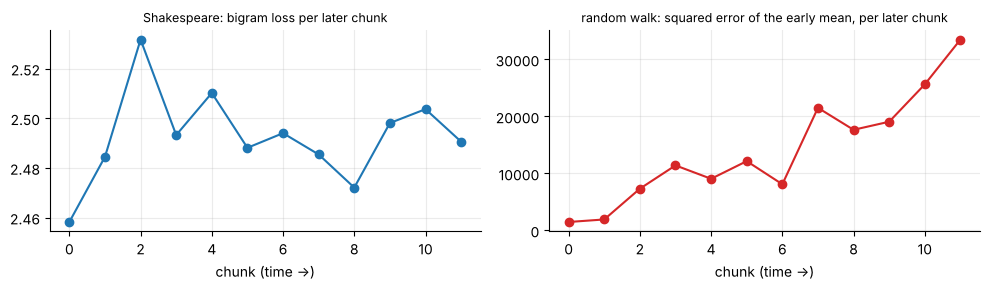

text: highest / lowest chunk loss = 1.03  (flat → stationary enough) · random walk: error of the last chunk / first chunk = 22.6
[ ok ] the text's error stays flat over time (max/min chunk loss < 1.25) while the random walk's error changes by a large factor


In [11]:
def chunk_losses(ids, fit_fraction=0.10, n_chunks=12, V=max_id):
    k = int(len(ids) * fit_fraction)
    counts = np.ones((V, V))                                                   # add-one smoothing
    np.add.at(counts, (ids[:k - 1], ids[1:k]), 1)
    logp = np.log(counts / counts.sum(1, keepdims=True))
    rest = ids[k:]
    return [-float(logp[c[:-1], c[1:]].mean()) for c in np.array_split(rest, n_chunks)]


text_losses = chunk_losses(encoded)
rw = np.cumsum(np.random.default_rng(0).normal(size=20_000))
k30 = int(0.3 * len(rw)); train_mean = float(rw[:k30].mean())                  # the "model": the average level seen in the first 30 %
walk_err = [float(np.mean((c - train_mean) ** 2)) for c in np.array_split(rw[k30:], 12)]
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(text_losses, "o-"); ax[0].set_title("Shakespeare: bigram loss per later chunk", fontsize=9); ax[0].set_xlabel("chunk (time →)")
ax[1].plot(walk_err, "o-", color="C3"); ax[1].set_title("random walk: squared error of the early mean, per later chunk", fontsize=9); ax[1].set_xlabel("chunk (time →)")
plt.tight_layout(); plt.show()
spread = max(text_losses) / min(text_losses)
print(f"text: highest / lowest chunk loss = {spread:.2f}  (flat → stationary enough) · random walk: error of the last chunk / first chunk = {walk_err[-1] / walk_err[0]:.1f}")
audit_trained("the text's error stays flat over time (max/min chunk loss < 1.25) while the random walk's error changes by a large factor", lambda: spread < 1.25 and max(walk_err) / min(walk_err) > 1.5)

### 1.5 Windows with `window()`, flattened with `flat_map()`
A model cannot be trained on one million-character sequence at once, so we chop the stream into **windows of 101 characters** (100 inputs + the target shifted by one).
* `shift=1` – every window starts one character after the previous one: maximum overlap, the biggest training set.
* `drop_remainder=True` – otherwise the last 100 windows would be shorter than 101.
* **`window()` returns a *nested dataset*** (a dataset whose items are datasets), which cannot be batched directly. `flat_map` flattens it. Toy example below.

In [12]:
toy = tf.data.Dataset.range(1, 7).window(2, shift=2, drop_remainder=True)
print("window(2): the items are", type(next(iter(toy))).__name__, "objects, e.g. ->", [int(v) for v in next(iter(toy))])
print("flat_map(lambda w: w)          ->", [int(v) for v in toy.flat_map(lambda w: w)])
print("flat_map(lambda w: w.batch(2)) ->", [b.numpy().tolist() for b in toy.flat_map(lambda w: w.batch(2))])
print("window(4, shift=2) then flat_map(batch(4)) ->", [b.numpy().tolist() for b in tf.data.Dataset.range(1, 7).window(4, shift=2, drop_remainder=True).flat_map(lambda w: w.batch(4))])
audit("flat_map(window → w) restores 1…6 and flat_map(window → w.batch(2)) gives [1,2],[3,4],[5,6]",
      [int(v) for v in toy.flat_map(lambda w: w)] == [1, 2, 3, 4, 5, 6] and [b.numpy().tolist() for b in toy.flat_map(lambda w: w.batch(2))] == [[1, 2], [3, 4], [5, 6]])

window(2): the items are _VariantDataset objects, e.g. -> [1, 2]
flat_map(lambda w: w)          -> [1, 2, 3, 4, 5, 6]
flat_map(lambda w: w.batch(2)) -> [[1, 2], [3, 4], [5, 6]]
window(4, shift=2) then flat_map(batch(4)) -> [[1, 2, 3, 4], [3, 4, 5, 6]]
[ ok ] flat_map(window → w) restores 1…6 and flat_map(window → w.batch(2)) gives [1,2],[3,4],[5,6]


**Truncated backpropagation through time.** Unrolling the network over a window of `n_steps = 100` characters (instead of the whole million) is *truncated BPTT*. Trade-off: short windows train more easily, but the model can never learn a pattern longer than `n_steps` (unless it is stateful – Phase 2).
**Full pipeline:** `shuffle(10000)` → `batch(32)` → inputs = characters 0–99, targets = characters 1–100 → one-hot the inputs → `prefetch(1)`.

In [13]:
n_steps, window_length, BATCH = SZ["n_steps"], SZ["n_steps"] + 1, SZ["char_batch"]


def make_char_dataset(ids, batch_size=BATCH, shift=1, shuffle=True, one_hot=True, seed=0):
    ds = tf.data.Dataset.from_tensor_slices(ids)
    ds = ds.window(window_length, shift=shift, drop_remainder=True)
    ds = ds.flat_map(lambda w: w.batch(window_length))
    if shuffle:
        ds = ds.shuffle(10_000, seed=seed)
    ds = ds.batch(batch_size, drop_remainder=True)
    ds = ds.map(lambda w: (w[:, :-1], w[:, 1:]))
    if one_hot:
        ds = ds.map(lambda X, Y: (tf.one_hot(X, depth=max_id), Y))
    return ds.prefetch(1)


train_set = make_char_dataset(train_ids)
valid_set = make_char_dataset(valid_ids, shuffle=False)
test_set = make_char_dataset(test_ids, shuffle=False)
Xb, Yb = next(iter(train_set))
print("one training batch: inputs", tuple(Xb.shape), Xb.dtype.name, "· targets", tuple(Yb.shape), Yb.dtype.name)
audit(f"a batch is inputs [32, 100, {max_id}] (one-hot; 39 on the full corpus) and targets [32, 100]", tuple(Xb.shape) == (32, 100, max_id) and tuple(Yb.shape) == (32, 100))
x_text = tokenizer.sequences_to_texts([np.argmax(Xb[0].numpy(), -1)[:25] + 1])[0].replace("   ", " ¶ ")
y_text = tokenizer.sequences_to_texts([Yb[0].numpy()[:25] + 1])[0].replace("   ", " ¶ ")
print("input  (first 25 characters):", x_text)
print("target (first 25 characters):", y_text, "  ← the same text shifted one step to the left")

one training batch: inputs (32, 100, 39) float32 · targets (32, 100) int64
[ ok ] a batch is inputs [32, 100, 39] (one-hot; 39 on the full corpus) and targets [32, 100]
input  (first 25 characters): n t i n g l y ¶ r e p l i e d 
 t o ¶ t h e ¶ d i
target (first 25 characters): t i n g l y ¶ r e p l i e d 
 t o ¶ t h e ¶ d i s   ← the same text shifted one step to the left


**Unit test: the target at position `t` must equal the input at position `t + 1`** – for every example of several batches (a mistake here would silently train the model to predict the wrong character).

In [14]:
bad = 0; n_checked = 0
for Xb_, Yb_ in train_set.take(20):
    ids_in = tf.argmax(Xb_, axis=-1).numpy()
    bad += int((ids_in[:, 1:] != Yb_.numpy()[:, :-1]).sum()); n_checked += len(ids_in)
audit("target[t] == input[t + 1] for every position of every example in 20 batches", bad == 0, f"{n_checked} examples checked")

[ ok ] target[t] == input[t + 1] for every position of every example in 20 batches   (640 examples checked)


**One-hot or embeddings?** With only 39 symbols a one-hot input is cheap (39 numbers per step) and needs no learned table. Task 19's rule of thumb: use one-hot while the number of categories is below about 10, and **embeddings** above about 50 – 39 is in between, so one-hot is fine; for words (10 000+ symbols, Phase 3) embeddings are a must.

---
# Phase 2 · The Char-RNN: write Shakespeare, control the randomness, carry state
Two stacked `GRU(128)` layers read 100 one-hot characters; at **every** time step a softmax over the 39 characters predicts the next one (`return_sequences=True` + a `Dense` layer, which Keras applies to every time step – the same as `TimeDistributed(Dense)`). Dropout `0.2` on the inputs and `0.2` on the recurrent connections guards against over-fitting.
**Size note:** the book trains this model for 10–20 epochs on a GPU. Here it gets `char_epochs × char_steps` mini-batches of 32 windows (see the `SZ` table), enough to learn words and the play layout, but not Shakespeare's grammar.

In [15]:
SB.phase = "Phase 2"


log_change("TimeDistributed(Dense(..., softmax))", "Dense(..., softmax) on the 3-D output", "identical result; TimeDistributed mis-handled the unknown batch size with a dynamic time axis in this Keras version")


def build_char_model(units=128, stateful=False, batch=None):
    inp = keras.Input(batch_shape=(batch, None, max_id))
    x = L.GRU(units, return_sequences=True, dropout=0.2, recurrent_dropout=0.2, stateful=stateful)(inp)
    x = L.GRU(units, return_sequences=True, dropout=0.2, recurrent_dropout=0.2, stateful=stateful)(x)
    out = L.Dense(max_id, activation="softmax")(x)                      # Dense on a 3-D tensor = TimeDistributed(Dense)
    m = keras.Model(inp, out)
    m.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
    return m


valid_small = valid_set.take(pick(60, 5))
test_small = test_set.take(pick(60, 5))
unigram = np.bincount(encoded[:n1], minlength=max_id) / n1
unigram_loss = float(-np.sum(np.bincount(test_ids, minlength=max_id) / len(test_ids) * np.log(unigram + 1e-12)))
print(f"reference: guessing from character frequencies alone gives a test loss of {unigram_loss:.3f} nats (uniform guessing: {math.log(max_id):.3f}); the bigram model of Phase 1 is about {np.mean(text_losses):.2f}")

reference: guessing from character frequencies alone gives a test loss of 3.075 nats (uniform guessing: 3.664); the bigram model of Phase 1 is about 2.49


### 2.1 Train the baseline

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, None, 39)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, None, 128)      │        64,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, None, 128)      │        99,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, None, 39)       │         5,031 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 168,999 (660.15 KB)

 Trainable params: 168,999 (660.15 KB)

 Non-trainable params: 0 (0.00 B)

116 s per epoch of 500 batches


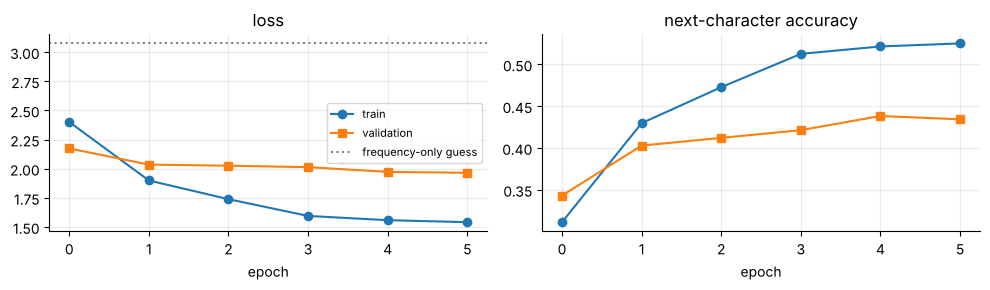

test loss 2.067 nats (perplexity 7.9 characters) · test accuracy 0.410
[ ok ] the Char-RNN beats guessing from character frequencies on the test set   (2.067 < 3.075)
[ ok ] training loss falls from the first to the last epoch


In [16]:
set_seed(11); fresh()
char_model = build_char_model(SZ["char_units"])
char_model.summary()
hist, sec = fit_quiet(char_model, train_set, epochs=SZ["char_epochs"], steps_per_epoch=SZ["char_steps"], validation_data=valid_small)
print(f"{sec:.0f} s per epoch of {SZ['char_steps']} batches")
base_val, base_acc = char_model.evaluate(test_small, verbose=0)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(hist["loss"], "o-", label="train"); ax[0].plot(hist["val_loss"], "s-", label="validation"); ax[0].axhline(unigram_loss, ls=":", color="gray", label="frequency-only guess"); ax[0].set_title("loss"); ax[0].set_xlabel("epoch"); ax[0].legend(fontsize=8)
ax[1].plot(hist["accuracy"], "o-"); ax[1].plot(hist["val_accuracy"], "s-"); ax[1].set_title("next-character accuracy"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()
print(f"test loss {base_val:.3f} nats (perplexity {math.exp(base_val):.1f} characters) · test accuracy {base_acc:.3f}")
RESULTS["char_baseline"] = dict(test_loss=base_val, test_acc=base_acc, sec_per_epoch=sec)
audit_trained("the Char-RNN beats guessing from character frequencies on the test set", lambda: base_val < unigram_loss, f"{base_val:.3f} < {unigram_loss:.3f}")
audit_trained("training loss falls from the first to the last epoch", lambda: hist["loss"][-1] < hist["loss"][0])

### 2.2 Generate text: `next_char` and `complete_text`
The model outputs a probability for every character. **Taking the arg-max** gives repetitive loops ("the the the …"). Instead we **sample** with `tf.random.categorical`, which expects *logits*, so we pass `log(probs) / temperature`:
* `temperature → 0` : the largest probability dominates → nearly always the most likely character (safe, repetitive).
* `temperature = 1` : sample from the model's own distribution.
* `temperature > 1` : flatter distribution → rarer characters appear (creative, but more spelling mistakes).
Each step feeds only the last `n_steps` characters (the length the model was trained on) – this bounds the cost of generating a long text.

In [17]:
def preprocess(texts):
    X = np.array(tokenizer.texts_to_sequences(texts)) - 1
    return tf.one_hot(X, max_id)


def make_predictor(model):
    return tf.function(lambda x: model(x, training=False), input_signature=[tf.TensorSpec([1, None, max_id], tf.float32)])


def next_char_probs(predict_fn, text):
    X = preprocess([text[-n_steps:]])
    return predict_fn(X)[0, -1].numpy()


def next_char(predict_fn, text, temperature=1.0):
    probs = next_char_probs(predict_fn, text)
    logits = tf.math.log(probs + 1e-10) / temperature
    ids = tf.random.categorical(logits[None, :], num_samples=1)[0, 0].numpy()
    return tokenizer.sequences_to_texts([[int(ids) + 1]])[0]


def complete_text(predict_fn, text, n_chars=200, temperature=1.0):
    for _ in range(n_chars):
        text += next_char(predict_fn, text, temperature)
    return text


predict_fn = make_predictor(char_model)
tf.random.set_seed(42)
print("probabilities for the character after 'th' :", {tokenizer.index_word[i + 1]: round(float(p), 3) for i, p in sorted(enumerate(next_char_probs(predict_fn, "th")), key=lambda t: -t[1])[:5]})
for T in (0.2, 1.0, 2.0):
    print(f"\n========== temperature {T} ==========")
    print(complete_text(predict_fn, "to be", n_chars=pick(250, 40), temperature=T))

probabilities for the character after 'th' : {'e': 0.57, 'a': 0.108, 'o': 0.089, 'i': 0.088, ' ': 0.068}

========== temperature 0.2 ==========


to be so.

coriolanus:
what he hast be so farther.

coriolanus:
what is the people and the people the rome to the people.

coriolanus:
the common the senators the gods for the man the people and the man a good to be so.

volsce:
i have streng of the peopl

========== temperature 1.0 ==========


to be it have sir.

sicinius:
we got servicy heart those good stand feether the
not to the onne, but about the othe to, low.

eenician:
which if thinge people promise, and stron rome, worthy hobe,
the master'd this?

menenius:
thy wire and service to cone

========== temperature 2.0 ==========


to be cim treish-
to yhns.
flow:
dy wharkmys h 'twask
unabon, by and inviuld, clut used. prequisdlan'd; were yourmease;,
rath's doght ridkw, yough..bavoujs: hara
ay tyeir?
' noke, im
sean show slihe, lutve. lebim
the of you cifiotispyrim!

sucinius:
btar 


**Reading the three samples.** At 0.2 the text is clean but repeats itself; at 1 it reads like Shakespeare-shaped text with invented words; at 2 spelling breaks down because rare characters are being drawn almost as often as common ones. The next cell measures this instead of just looking at it.

In [18]:
def nonwords_rate(txt, vocab):
    words = re.findall(r"[a-z']+", txt.lower())
    return sum(w not in vocab for w in words) / max(1, len(words))


train_vocab = set(re.findall(r"[a-z']+", shakespeare_text[:int(0.9 * len(shakespeare_text))].lower()))
rate = {}
for T in (0.2, 1.0, 2.0):
    tf.random.set_seed(7)
    smp = complete_text(predict_fn, "to be", n_chars=pick(600, 60), temperature=T)
    rate[T] = nonwords_rate(smp[5:], train_vocab)
print({T: f"{100 * r:.1f} % of the generated words never occur in the training text" for T, r in rate.items()})
RESULTS["char_nonword_rate"] = rate
audit_trained("hotter sampling invents more non-words (rate at 2.0 > rate at 0.2)", lambda: rate[2.0] > rate[0.2], f"{rate[0.2]:.3f} → {rate[1.0]:.3f} → {rate[2.0]:.3f}")

{0.2: '1.7 % of the generated words never occur in the training text', 1.0: '17.1 % of the generated words never occur in the training text', 2.0: '68.8 % of the generated words never occur in the training text'}
[ ok ] hotter sampling invents more non-words (rate at 2.0 > rate at 0.2)   (0.017 → 0.171 → 0.688)


### 2.3 Exercise 12 · entropy of the next-character distribution vs temperature
`softmax(log p / T)` is the distribution after the temperature change. Its **entropy** `H = −Σ p log p` measures how undecided the choice is: `0` = always the same character, `log 39 = 3.66 nats` = all characters equally likely.

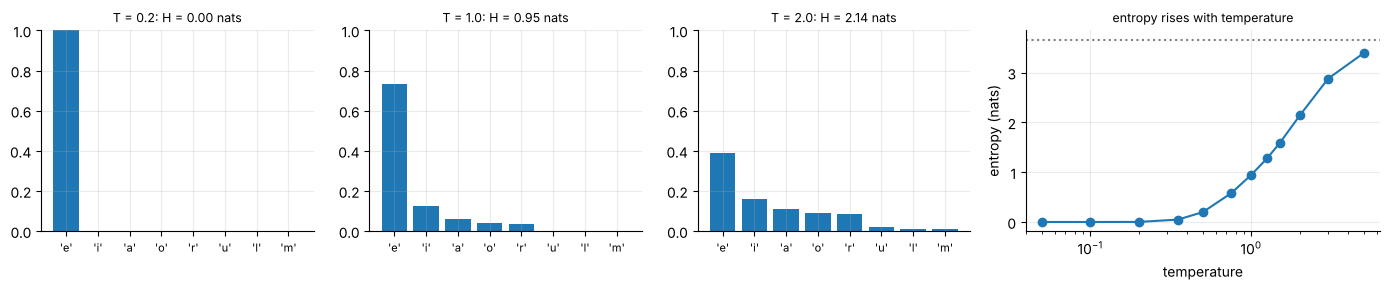

most likely next character for this context: 'e' (p = 0.73)
[ ok ] entropy is strictly increasing in temperature (12 temperatures from 0.05 to 5)
[ ok ] T = 0.2 is sharper than the model (lower entropy) and T = 2 is flatter than the model (higher entropy)
[ ok ] T = 1 reproduces the model's own probabilities
[ ok ] as T → ∞ the entropy approaches log(39) (uniform choice)


In [19]:
ctx = "first citizen:\nbefore we proceed any further, hear me sp"
p0 = next_char_probs(predict_fn, ctx)


def tempered(p, T):
    z = np.log(p + 1e-10) / T
    z -= z.max(); e = np.exp(z)
    return e / e.sum()


def entropy(p):
    p = p[p > 0]
    return float(-(p * np.log(p)).sum())


Ts = np.array([0.05, 0.1, 0.2, 0.35, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 3.0, 5.0])
H = [entropy(tempered(p0, T)) for T in Ts]
top = np.argsort(-p0)[:8]
fig, ax = plt.subplots(1, 4, figsize=(14, 3), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.3]))
for a, T in zip(ax[:3], (0.2, 1.0, 2.0)):
    a.bar(range(len(top)), tempered(p0, T)[top]); a.set_xticks(range(len(top))); a.set_xticklabels([repr(tokenizer.index_word[i + 1]) for i in top], fontsize=8)
    a.set_title(f"T = {T}: H = {entropy(tempered(p0, T)):.2f} nats", fontsize=9); a.set_ylim(0, 1)
ax[3].plot(Ts, H, "o-"); ax[3].axhline(math.log(max_id), ls=":", color="gray"); ax[3].set_xscale("log"); ax[3].set_xlabel("temperature"); ax[3].set_ylabel("entropy (nats)"); ax[3].set_title("entropy rises with temperature", fontsize=9)
plt.tight_layout(); plt.show()
print("most likely next character for this context:", repr(tokenizer.index_word[int(np.argmax(p0)) + 1]), f"(p = {p0.max():.2f})")
audit("entropy is strictly increasing in temperature (12 temperatures from 0.05 to 5)", all(b > a for a, b in zip(H, H[1:])))
audit("T = 0.2 is sharper than the model (lower entropy) and T = 2 is flatter than the model (higher entropy)", entropy(tempered(p0, 0.2)) < entropy(p0) < entropy(tempered(p0, 2.0)))
audit("T = 1 reproduces the model's own probabilities", np.allclose(tempered(p0, 1.0), p0 / p0.sum(), atol=1e-5))
audit("as T → ∞ the entropy approaches log(39) (uniform choice)", abs(entropy(tempered(p0, 1e4)) - math.log(max_id)) < 0.01)
EX[12] = ("done", "entropy 0.2 / 1 / 2 and the whole curve are plotted and audited in Phase 2")

### 2.4 One improvement experiment: a wider network
Same recipe, same number of mini-batches and the same seed, but `GRU(192)` instead of `GRU(128)`. **This is one run each**, so a small difference cannot be separated from seed noise – the verdict is worded accordingly.

In [20]:
set_seed(11); fresh()
wide_model = build_char_model(SZ["improved_units"])
hist_w, sec_w = fit_quiet(wide_model, train_set, epochs=SZ["char_epochs"], steps_per_epoch=SZ["char_steps"], validation_data=valid_small)
wide_val, wide_acc = wide_model.evaluate(test_small, verbose=0)
cmp_ = pd.DataFrame({"parameters": [char_model.count_params(), wide_model.count_params()], "test loss": [base_val, wide_val], "test accuracy": [base_acc, wide_acc], "seconds / epoch": [sec, sec_w]},
                    index=[f"GRU({SZ['char_units']}) baseline", f"GRU({SZ['improved_units']}) wider"])
display(cmp_.round(4))
RESULTS["char_wide"] = dict(test_loss=wide_val, test_acc=wide_acc)
print("Verdict: the wider model has a", "lower" if wide_val < base_val else "higher", f"test loss by {abs(wide_val - base_val):.3f} nats (one seed each – differences below about 0.02 should not be trusted).")
audit_trained("the wider network is not clearly worse than the baseline (test loss within 0.05 nats)", lambda: wide_val < base_val + 0.05)
del wide_model; fresh()

,parameters,test loss,test accuracy,seconds / epoch
GRU(128) baseline,168999,2.0671,0.4098,115.7645
GRU(192) wider,364071,2.1071,0.4047,188.2989


Verdict: the wider model has a higher test loss by 0.040 nats (one seed each – differences below about 0.02 should not be trusted).
[ ok ] the wider network is not clearly worse than the baseline (test loss within 0.05 nats)


### 2.5 Stateful RNN – train on one long, continuous stream
A **stateless** RNN starts every window with a zero hidden state, so it can never use more than `n_steps` characters of context. A **stateful** RNN keeps the final hidden state of batch *k* as the initial state of batch *k + 1*. That only makes sense if row *j* of batch *k + 1* **continues** row *j* of batch *k*, which needs three changes to the data pipeline:
1. **non-overlapping windows** (`shift = n_steps`; consecutive windows share just the one character that is the last target and the next first input);
2. **no shuffling** (order carries meaning);
3. the text is cut into **32 parallel streams** (one per row of the batch), each windowed separately, and the 32 datasets are `zip`-ped and stacked, so that row *j* of every batch always comes from stream *j*.

In [21]:
def make_stateful_dataset(ids, batch_size=32):
    parts = np.array_split(ids, batch_size)
    streams = []
    for part in parts:
        ds = tf.data.Dataset.from_tensor_slices(part).window(window_length, shift=n_steps, drop_remainder=True).flat_map(lambda w: w.batch(window_length))
        streams.append(ds)
    ds = tf.data.Dataset.zip(tuple(streams)).map(lambda *w: tf.stack(w))
    ds = ds.map(lambda w: (w[:, :-1], w[:, 1:])).map(lambda X, Y: (tf.one_hot(X, depth=max_id), Y))
    return ds.prefetch(1)


stateful_train, stateful_valid, stateful_test = (make_stateful_dataset(s) for s in (train_ids, valid_ids, test_ids))
n_stateful_batches = sum(1 for _ in stateful_train)
print("batches per epoch:", n_stateful_batches, "(each epoch reads every stream once, front to back)")

# continuity test: row j of batch k+1 must start with the last target character of row j in batch k
prev_Y, ok_rows, n_rows = None, 0, 0
for Xb_, Yb_ in stateful_train.take(12):
    ids_in = tf.argmax(Xb_, -1).numpy()
    if prev_Y is not None:
        ok_rows += int((ids_in[:, 0] == prev_Y[:, -1]).sum()); n_rows += len(ids_in)
    prev_Y = Yb_.numpy()
audit("stream continuity: in 11 consecutive batches, all 32 rows of every batch start where the same row of the previous batch ended", ok_rows == n_rows and n_rows == 11 * 32, f"{ok_rows}/{n_rows} rows")
first_X = next(iter(stateful_train))[0]
audit("the 32 rows come from 32 different parts of the book (more than 20 distinct opening 20-character strings)", len({tuple(r) for r in tf.argmax(first_X, -1).numpy()[:, :20]}) > 20)

batches per epoch: 313 (each epoch reads every stream once, front to back)


[ ok ] stream continuity: in 11 consecutive batches, all 32 rows of every batch start where the same row of the previous batch ended   (352/352 rows)
[ ok ] the 32 rows come from 32 different parts of the book (more than 20 distinct opening 20-character strings)


**Model and callback.** `stateful=True` needs a fixed batch size (32), so the input is `Input(batch_shape=(32, None, 39))`. The hidden state must be reset at the start of every epoch (the streams start over) and before validation (the validation streams are different text).

85 s per epoch


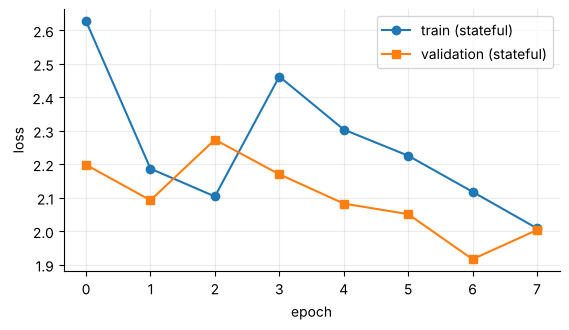

In [22]:
def reset_states(model):
    for layer in model.layers:
        if hasattr(layer, "reset_state"):
            layer.reset_state()
        elif hasattr(layer, "reset_states"):
            layer.reset_states()


class ResetStatesCallback(keras.callbacks.Callback):
    def on_epoch_begin(self, epoch, logs=None):
        reset_states(self.model)

    def on_test_begin(self, logs=None):
        reset_states(self.model)


set_seed(11); fresh()
stateful_model = build_char_model(SZ["char_units"], stateful=True, batch=32)
hist_s, sec_s = fit_quiet(stateful_model, stateful_train, epochs=SZ["stateful_epochs"], validation_data=stateful_valid, callbacks=[ResetStatesCallback()])
print(f"{sec_s:.0f} s per epoch")
plt.plot(hist_s["loss"], "o-", label="train (stateful)"); plt.plot(hist_s["val_loss"], "s-", label="validation (stateful)"); plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.show()

**Stateless twin.** We cannot use a stateful model to generate text for one prompt (batch of 1), so the weights are copied into an identical *stateless* model. Two checks:
1. On the first batch (state = zeros in both) the two models give the same output.
2. Feeding **two consecutive batches** one after the other to the stateful model equals feeding the 200 characters **at once** to the stateless twin – this is exactly what "the state is carried over" means.

In [23]:
twin = build_char_model(SZ["char_units"], stateful=False, batch=None)
twin.set_weights(stateful_model.get_weights())
it = iter(stateful_test)
(Xa, Ya), (Xb2, Yb2) = next(it), next(it)
reset_states(stateful_model)
out_a = stateful_model(Xa, training=False).numpy()
out_b = stateful_model(Xb2, training=False).numpy()
twin_a = twin(Xa, training=False).numpy()
twin_ab = twin(tf.concat([Xa, Xb2], axis=1), training=False).numpy()
audit("first batch: stateful model (zero state) and stateless twin give identical probabilities", np.abs(out_a - twin_a).max() < 1e-5, f"max |difference| = {np.abs(out_a - twin_a).max():.2e}")
audit("second batch: the stateful model's output equals the twin run on the 200-character concatenation (the carried state is exact)", np.abs(out_b - twin_ab[:, n_steps:]).max() < 1e-5, f"max |difference| = {np.abs(out_b - twin_ab[:, n_steps:]).max():.2e}")
audit("without carrying the state, the second batch would give different probabilities", np.abs(twin(Xb2, training=False).numpy() - out_b).max() > 1e-3, f"max |difference| = {np.abs(twin(Xb2, training=False).numpy() - out_b).max():.3f}")

[ ok ] first batch: stateful model (zero state) and stateless twin give identical probabilities   (max |difference| = 0.00e+00)
[ ok ] second batch: the stateful model's output equals the twin run on the 200-character concatenation (the carried state is exact)   (max |difference| = 0.00e+00)


[ ok ] without carrying the state, the second batch would give different probabilities   (max |difference| = 0.836)


**Same weights, same test stream, state carried vs. reset.** The twin sees each 100-character window with a fresh zero state; the stateful model carries the state from window to window.

In [24]:
reset_states(stateful_model)
st_loss, st_acc = stateful_model.evaluate(stateful_test, verbose=0)
tw_loss, tw_acc = twin.evaluate(stateful_test, verbose=0)
display(pd.DataFrame({"test loss": [st_loss, tw_loss], "test accuracy": [st_acc, tw_acc]}, index=["stateful (state carried)", "same weights, state reset every window"]).round(4))
RESULTS["char_stateful"] = dict(stateful_loss=st_loss, twin_loss=tw_loss, base_stateless_loss=base_val)
audit_trained("carrying the state does not hurt: loss with carried state <= loss with reset state (+0.01)", lambda: st_loss <= tw_loss + 0.01, f"{st_loss:.3f} vs {tw_loss:.3f}")
tf.random.set_seed(42)
print("\nStateless twin of the stateful model, T = 1:\n")
print(complete_text(make_predictor(twin), "to be", n_chars=pick(200, 30), temperature=1.0))

,test loss,test accuracy
stateful (state carried),1.9977,0.3827
"same weights, state reset every window",2.0428,0.3715


[ ok ] carrying the state does not hurt: loss with carried state <= loss with reset state (+0.01)   (1.998 vs 2.043)

Stateless twin of the stateful model, T = 1:



to beolp.

doueds wrriedmert.

yorth:

wishan:
blf not drat? ar wikes.daglecbeld: of sde buch or o cid win ho cutcantiop! i coied heb to chaise,
whist his gote uneres in you
in my shast'ne afpeand.

and ba


### 2.6 Exercise 1 · stateful vs. stateless RNN
| | **Stateless** | **Stateful** |
|---|---|---|
| Memory span | at most `n_steps` (zero state at every window) | the whole stream (state carried between batches) |
| Data pipeline | windows overlap (`shift=1`), shuffled, any batch size | non-overlapping windows, **no shuffling**, parallel streams, fixed batch size |
| Training set | ~1 M windows; most of the information is repeated | ~1/100 as many windows per epoch |
| Gradients | independent, shuffling decorrelates the batches | batches are strongly correlated (consecutive text); gradients still flow only within a window (truncated BPTT) |
| Extra code | none | reset states each epoch and before evaluation; copy weights to a stateless twin to generate for a single prompt |
| Use it when | classification, translation, the usual case | very long sequences where the context beyond `n_steps` matters (e.g. long documents, streaming data) |
**In this run:** the stateful model learned from fewer, non-shuffled batches. Its carried-state advantage is the gap between the two rows above. Gradients never go back across a window boundary, so the model is not trained to *use* the carried state in the way an unrolled model would.

In [25]:
EX[1] = ("done", "table + working stateful model, continuity test and exact twin check in Phase 2")
del stateful_model, twin; fresh()

---
# Phase 3 · Sentiment analysis on IMDb reviews – from raw text to word IDs
A **word-level** model: split a review into words, map each word to an ID, feed the IDs to an `Embedding` layer and two GRU layers, and predict "positive" with a sigmoid. The interesting part is the preprocessing, which the brief asks us to build with TensorFlow string ops so that it runs inside the `tf.data` pipeline.
**Data note.** `tfds`/`keras.datasets.imdb` download from `storage.googleapis.com`, which was not reachable where this notebook ran. We use the same 50 000 labelled IMDb reviews (25 000 positive, 25 000 negative) from a public CSV and make our own **random stratified 25 000 / 25 000 split**. It is *not* the official train/test split, so numbers are comparable in kind but not to the digit with published ones.

In [26]:
SB.phase = "Phase 3"
imdb_path = download([f"{GH}/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv", f"{GH}/laxmimerit/IMDB-Data-Files/master/IMDB%20Dataset.csv"], DATA_DIR / "imdb.csv")
imdb = pd.read_csv(imdb_path)
print(imdb.shape, "·", dict(imdb.sentiment.value_counts()))
rng = np.random.default_rng(0)
tr_idx, te_idx = [], []
for lab in ("positive", "negative"):
    idx = rng.permutation(np.flatnonzero(imdb.sentiment.values == lab))
    half = len(idx) // 2
    tr_idx += list(idx[:half][:SZ["imdb_train"] // 2]); te_idx += list(idx[half:][:SZ["imdb_test"] // 2])
tr_idx, te_idx = rng.permutation(tr_idx), rng.permutation(te_idx)
X_all, y_all = imdb.review.values, (imdb.sentiment.values == "positive").astype("float32")
n_val = len(tr_idx) // 10
va_idx, tr_idx = tr_idx[:n_val], tr_idx[n_val:]
X_train, y_train, X_valid, y_valid, X_test, y_test = X_all[tr_idx], y_all[tr_idx], X_all[va_idx], y_all[va_idx], X_all[te_idx], y_all[te_idx]
print(f"train {len(X_train):,} · validation {len(X_valid):,} (10 % of the training reviews, used only to watch training) · test {len(X_test):,}")
print("positive share → train {:.3f} · validation {:.3f} · test {:.3f}".format(y_train.mean(), y_valid.mean(), y_test.mean()))
audit("train, validation and test are disjoint sets of reviews (no shared row)", len(set(tr_idx) | set(va_idx) | set(te_idx)) == len(tr_idx) + len(va_idx) + len(te_idx))
audit("every set is (almost exactly) balanced between positive and negative", all(abs(v.mean() - 0.5) < 0.05 for v in (y_train, y_valid, y_test)))
print("\nA raw review (first 300 characters):\n", X_train[0][:300])

(50000, 2) · {'positive': np.int64(25000), 'negative': np.int64(25000)}
train 22,500 · validation 2,500 (10 % of the training reviews, used only to watch training) · test 25,000
positive share → train 0.500 · validation 0.499 · test 0.500
[ ok ] train, validation and test are disjoint sets of reviews (no shared row)
[ ok ] every set is (almost exactly) balanced between positive and negative

A raw review (first 300 characters):
 It is enjoyable and fast-paced. <br /><br />There is no way on Earth that the actor playing Mat could be eighteen. However, the main thing is that he does act eighteen very convincingly. It must be a credit to his audition that he convinced them to cast him. I quite soon accepted him as being a naiv


### 3.1 Pre-tokenized reviews: how to decode them
The official Keras IMDb data is delivered as lists of integers, **shifted by 3**: `0 = <pad>`, `1 = <sos>` (start of sequence), `2 = <unk>` (unknown word) and the real words start at 3 (rank 1 → ID 4 in the usual `word_index + index_from` convention). To read such a review you build the reverse dictionary and subtract the offset. We cannot download that file, so the cell below *recreates the convention* with our own frequency-ranked vocabulary and decodes with the code from the brief – this proves the decoding logic, not the Keras file itself.

In [27]:
def simple_words(txt):
    return re.findall(r"[a-z']+", re.sub(r"<br\s*/?>", " ", txt.lower()))


freq = Counter(w for r in X_train for w in simple_words(r))
word_index = {w: i + 1 for i, (w, _) in enumerate(freq.most_common(10_000))}                # rank 1 = most frequent word (keras convention)
INDEX_FROM = 3


def encode_keras_style(txt):
    return [1] + [word_index[w] + INDEX_FROM if w in word_index else 2 for w in simple_words(txt)]


reverse_index = {i + INDEX_FROM: w for w, i in word_index.items()}
reverse_index.update({0: "<pad>", 1: "<sos>", 2: "<unk>"})
encoded_review = encode_keras_style(X_train[0])
print("first 20 ids :", encoded_review[:20])
print("decoded      :", " ".join(reverse_index[i] for i in encoded_review[:20]))
audit("decoding the shifted ids gives back the words, with <sos> in front and <unk> for unknown words",
      [reverse_index[i] for i in encoded_review[1:]] == [w if w in word_index else "<unk>" for w in simple_words(X_train[0])] and reverse_index[encoded_review[0]] == "<sos>")
print("most frequent words:", [w for w, _ in freq.most_common(8)], "· the most frequent word gets ID", word_index[freq.most_common(1)[0][0]] + INDEX_FROM, "(rank 1 + offset 3 = 4)")

first 20 ids : [1, 11, 9, 751, 5, 716, 1672, 48, 9, 56, 96, 22, 758, 14, 4, 292, 395, 2, 99, 28]
decoded      : <sos> it is enjoyable and fast paced there is no way on earth that the actor playing <unk> could be
[ ok ] decoding the shifted ids gives back the words, with <sos> in front and <unk> for unknown words
most frequent words: ['the', 'and', 'a', 'of', 'to', 'is', 'in', 'it'] · the most frequent word gets ID 4 (rank 1 + offset 3 = 4)


### 3.2 Whitespace words vs. sub-word units (SentencePiece)
* **Whitespace / word vocabulary:** simple and readable, but every rare word, misspelling or new inflection is out-of-vocabulary (OOV) and all OOV words share the same few embeddings.
* **Sub-word vocabulary (BPE / WordPiece / SentencePiece):** rare words are split into frequent pieces (`un·believ·ably`), so nothing is ever completely unknown and the vocabulary stays small; sequences get longer and a single piece is less readable.
Here we train a small SentencePiece model on the training reviews and compare it with the word-level vocabulary we use later.

In [28]:
try:
    import sentencepiece as spm
    sp_corpus = OUT_DIR / "imdb_train_for_sp.txt"
    sp_corpus.write_text("\n".join(" ".join(simple_words(r)) for r in X_train[:pick(20000, 2000)]), encoding="utf-8")
    spm.SentencePieceTrainer.train(input=str(sp_corpus), model_prefix=str(OUT_DIR / "imdb_sp"), vocab_size=pick(4000, 800), model_type="unigram", character_coverage=1.0, pad_id=0, unk_id=1, bos_id=-1, eos_id=-1, minloglevel=2)
    sp = spm.SentencePieceProcessor(model_file=str(OUT_DIR / "imdb_sp.model"))
    for w in ["unbelievably", "cinematographer", "disappointingly", "awesome"]:
        print(f"{w:16s} → {sp.encode(w, out_type=str)}")
    sample = [" ".join(simple_words(r)) for r in X_valid[:300]]
    n_words = sum(len(s.split()) for s in sample); n_pieces = sum(len(sp.encode(s)) for s in sample)
    top_words = set(word_index)
    oov_words = sum(w not in top_words for s in sample for w in s.split())
    print(f"\nsequence length: {n_words / len(sample):.1f} words vs {n_pieces / len(sample):.1f} sub-word pieces per review · tokens that are unknown: {100 * oov_words / n_words:.2f} % of words (word vocabulary of 10 000) vs {100 * sum(i == 1 for s in sample for i in sp.encode(s)) / n_pieces:.2f} % of pieces (SentencePiece)")
    audit("SentencePiece round trip: decode(encode(text)) returns the text", all(sp.decode(sp.encode(s)) == s for s in sample[:50]))
    audit("sub-word pieces make sequences longer than word tokens", n_pieces > n_words)
except Exception as e:
    print("SentencePiece part skipped:", type(e).__name__, e)
    audit("SentencePiece demo ran", False, str(e)[:120])

unbelievably     → ['▁unbelievably']
cinematographer  → ['▁cinema', 'to', 'gra', 'ph', 'er']
disappointingly  → ['▁disappointing', 'ly']
awesome          → ['▁awesome']

sequence length: 242.0 words vs 312.4 sub-word pieces per review · tokens that are unknown: 5.75 % of words (word vocabulary of 10 000) vs 0.00 % of pieces (SentencePiece)
[ ok ] SentencePiece round trip: decode(encode(text)) returns the text
[ ok ] sub-word pieces make sequences longer than word tokens


### 3.3 Preprocessing with TensorFlow string operations
Steps (all inside the `tf.data` pipeline, so they run on batches of strings):
1. keep only the first **300 characters** of a review (the start already carries most of the sentiment, and short sequences train fast);
2. replace HTML line breaks `<br />` by a space (regex `<br\s*/?>`);
3. replace everything that is not a letter or an apostrophe by a space (regex `[^a-zA-Z']`);
4. `tf.strings.split` → a **ragged** tensor (reviews have different lengths);
5. `to_tensor(default_value=b"<pad>")` → a dense tensor padded to the longest review *of the batch*.

In [29]:
def preprocess(X_batch, y_batch=None):
    s = tf.strings.substr(X_batch, 0, 300, unit="UTF8_CHAR")
    s = tf.strings.regex_replace(s, rb"<br\s*/?>", b" ")
    s = tf.strings.regex_replace(s, b"[^a-zA-Z']", b" ")
    s = tf.strings.split(s)
    s = s.to_tensor(default_value=b"<pad>")
    return s if y_batch is None else (s, y_batch)


def python_reference(txt):
    t = txt[:300]
    t = re.sub(r"<br\s*/?>", " ", t); t = re.sub(r"[^a-zA-Z']", " ", t)
    return t.split()


demo = preprocess(tf.constant(list(X_train[:3])))
print("padded batch shape:", tuple(demo.shape), "\nfirst review →", [w.decode() for w in demo[0].numpy()[:14]], "…")
print("last words of the shortest review (padding at the end) →", [w.decode() for w in demo.numpy()[int(np.argmin([len(python_reference(r)) for r in X_train[:3]]))][-4:]])
many = preprocess(tf.constant(list(X_train[:200]))).numpy()
same = [[w.decode() for w in row if w != b"<pad>"] == python_reference(r) for row, r in zip(many, X_train[:200])]
audit("the TF string pipeline gives the same words as a plain-Python re-implementation on 200 reviews", all(same), f"{sum(same)}/200 identical")
audit("padding uses the token <pad> and only at the end of a review", all(list(row).index(b"<pad>") == len([w for w in row if w != b"<pad>"]) for row in many if b"<pad>" in row))

padded batch shape: (3, 58) 
first review → ['It', 'is', 'enjoyable', 'and', 'fast', 'paced', 'There', 'is', 'no', 'way', 'on', 'Earth', 'that', 'the'] …
last words of the shortest review (padding at the end) → ['<pad>', '<pad>', '<pad>', '<pad>']
[ ok ] the TF string pipeline gives the same words as a plain-Python re-implementation on 200 reviews   (200/200 identical)
[ ok ] padding uses the token <pad> and only at the end of a review


### 3.4 Vocabulary: the 10 000 most common words, plus 1 000 hash buckets for the rest
`Counter` over the training reviews → keep the top 10 000 words, `<pad>` gets ID 0. A `tf.lookup.StaticVocabularyTable` maps a word to its ID; words it does not know are **hashed into one of 1 000 OOV buckets** (IDs 10 001 … 11 000). The advantage over one single `<unk>` ID: different unknown words get different (shared) embeddings, so names and rare words can still carry some information.

In [30]:
vocab_counter = Counter()
for Xb_ in tf.data.Dataset.from_tensor_slices(list(X_train)).batch(1000).map(preprocess):
    for row in Xb_.numpy():
        vocab_counter.update(w.decode() for w in row if w != b"<pad>")
TOP = 10_000
truncated_vocabulary = ["<pad>"] + [w for w, _ in vocab_counter.most_common(TOP)]
N_OOV = 1_000
vocab_size = len(truncated_vocabulary) + N_OOV
print("most common words:", truncated_vocabulary[1:13])
total = sum(vocab_counter.values()); covered = sum(vocab_counter[w] for w in truncated_vocabulary[1:])
print(f"the top {TOP:,} words cover {100 * covered / total:.2f} % of the word occurrences in the training reviews; vocabulary size incl. <pad> and {N_OOV} OOV buckets = {vocab_size:,}")
table = tf.lookup.StaticVocabularyTable(tf.lookup.KeyValueTensorInitializer(tf.constant(truncated_vocabulary), tf.range(len(truncated_vocabulary), dtype=tf.int64)), num_oov_buckets=N_OOV)
probe = table.lookup(tf.constant(["<pad>", "the", "movie", "xyzzyplugh", "qwertyuiop", "xyzzyplugh"])).numpy()
print("lookup of <pad>, the, movie, xyzzyplugh, qwertyuiop, xyzzyplugh →", probe.tolist())
audit("<pad> gets ID 0 and 'the' is among the first IDs", probe[0] == 0 and probe[1] <= 3)
audit("unknown words go to an OOV bucket (ID >= 10 001), and the same unknown word always gets the same bucket", probe[3] >= len(truncated_vocabulary) and probe[4] >= len(truncated_vocabulary) and probe[3] == probe[5], f"{probe[3]}, {probe[4]}")
oov_ids = table.lookup(tf.constant([f"strangeword{i}" for i in range(2000)])).numpy()
print(f"2 000 made-up words fall into {len(set(oov_ids.tolist()))} of the {N_OOV} buckets")
audit("hashing spreads unknown words over (nearly) all buckets", len(set(oov_ids.tolist())) > 0.8 * N_OOV)


def encode_words(X_batch, y_batch):
    return table.lookup(X_batch), y_batch


def make_review_ds(X, y, batch=32, shuffle=False, seed=0):
    ds = tf.data.Dataset.from_tensor_slices((list(X), y))
    if shuffle:
        ds = ds.shuffle(len(X), seed=seed, reshuffle_each_iteration=True)
    return ds.batch(batch).map(preprocess).map(encode_words).prefetch(1)


train_ds, valid_ds, test_ds = make_review_ds(X_train, y_train, shuffle=True), make_review_ds(X_valid, y_valid), make_review_ds(X_test, y_test)
ids_b, y_b = next(iter(train_ds))
print("one batch → ids", tuple(ids_b.shape), ids_b.dtype.name, "· labels", tuple(y_b.shape), "· ID range", int(ids_b.numpy().min()), "…", int(ids_b.numpy().max()))
audit("every ID in a batch is inside the embedding table (0 … vocab_size − 1)", ids_b.numpy().min() >= 0 and ids_b.numpy().max() < vocab_size)
lengths = np.array([len(python_reference(r)) for r in X_train[:2000]])
print(f"words per review (first 300 characters): mean {lengths.mean():.1f}, 95th percentile {np.percentile(lengths, 95):.0f}, max {lengths.max()}")

most common words: ['the', 'a', 'of', 'and', 'to', 'I', 'is', 'in', 'this', 'it', 'movie', 'was']
the top 10,000 words cover 93.45 % of the word occurrences in the training reviews; vocabulary size incl. <pad> and 1000 OOV buckets = 11,001
lookup of <pad>, the, movie, xyzzyplugh, qwertyuiop, xyzzyplugh → [0, 1, 11, 10016, 10428, 10016]
[ ok ] <pad> gets ID 0 and 'the' is among the first IDs
[ ok ] unknown words go to an OOV bucket (ID >= 10 001), and the same unknown word always gets the same bucket   (10016, 10428)
2 000 made-up words fall into 874 of the 1000 buckets
[ ok ] hashing spreads unknown words over (nearly) all buckets


one batch → ids (32, 64) int64 · labels (32,) · ID range 0 … 10990
[ ok ] every ID in a batch is inside the embedding table (0 … vocab_size − 1)
words per review (first 300 characters): mean 53.6, 95th percentile 60, max 69


### 3.5 The model, trained with three seeds
`Embedding(11 001, 128)` → `GRU(128, return_sequences=True)` → `GRU(128)` → `Dense(1, sigmoid)`, Nadam, binary cross-entropy. **This first version has no masking**: the `<pad>` tokens are read like words, so the GRU's final state is also influenced by the padding. Phase 4 fixes that.
Every number is mean ± sample std over the three seeds; validation is used only to watch the curves, the test accuracy is read once after the last epoch.

seed 11: test accuracy 0.7627 · validation 0.7568 · 74 s/epoch


seed 22: test accuracy 0.7425 · validation 0.7440 · 68 s/epoch


seed 33: test accuracy 0.7664 · validation 0.7644 · 70 s/epoch

word-level GRU from scratch, no masking: test accuracy 0.7572 ± 0.0128  (5 epochs, 1,606,401 parameters)


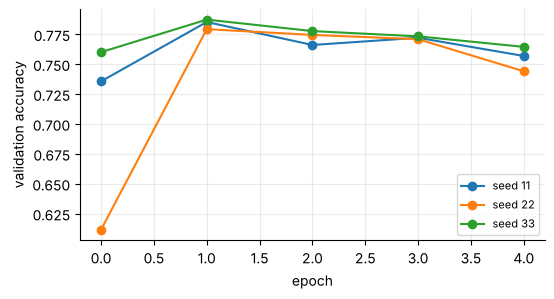

[ ok ] the sentiment model is clearly better than chance (mean test accuracy > 0.70)   (0.757)


In [31]:
def build_sentiment(mask_zero=False, embed_dim=SZ["emb_dim"]):
    m = keras.Sequential([L.Input((None,), dtype="int64"),
                          L.Embedding(vocab_size, embed_dim, mask_zero=mask_zero),
                          L.GRU(128, return_sequences=True), L.GRU(128), L.Dense(1, activation="sigmoid")])
    m.compile(loss="binary_crossentropy", optimizer="nadam", metrics=["accuracy"])
    return m


def run_sentiment(seed, build=build_sentiment, epochs=SZ["imdb_epochs"], tr=None, va=None, te=None, **kw):
    set_seed(seed); fresh()
    tr = tr or make_review_ds(X_train, y_train, shuffle=True, seed=seed)
    model = build(**kw)
    h, sec = fit_quiet(model, tr, epochs=epochs, validation_data=va or valid_ds)
    loss, acc = model.evaluate(te or test_ds, verbose=0)
    return model, dict(test_acc=float(acc), test_loss=float(loss), val_acc=h["val_accuracy"][-1], sec_per_epoch=sec, history=h, params=model.count_params())


scratch_runs, scratch_models = [], {}
for s in SZ["imdb_seeds"]:
    model, r = run_sentiment(s)
    scratch_runs.append(r)
    if s == SZ["imdb_seeds"][0]:
        scratch_models[s] = model
    print(f"seed {s}: test accuracy {r['test_acc']:.4f} · validation {r['val_acc']:.4f} · {r['sec_per_epoch']:.0f} s/epoch")
scratch_acc = [r["test_acc"] for r in scratch_runs]
RESULTS["imdb_scratch"] = scratch_acc
RESULTS["imdb_scratch_time"] = float(np.mean([r["sec_per_epoch"] for r in scratch_runs]))
print(f"\nword-level GRU from scratch, no masking: test accuracy {pm(scratch_acc, 4)}  ({SZ['imdb_epochs']} epochs, {scratch_runs[0]['params']:,} parameters)")
fig, ax = plt.subplots(figsize=(6, 3))
for s, r in zip(SZ["imdb_seeds"], scratch_runs):
    ax.plot(r["history"]["val_accuracy"], "o-", label=f"seed {s}")
ax.set_xlabel("epoch"); ax.set_ylabel("validation accuracy"); ax.legend(fontsize=8); plt.show()
audit_trained("the sentiment model is clearly better than chance (mean test accuracy > 0.70)", lambda: np.mean(scratch_acc) > 0.70, f"{np.mean(scratch_acc):.3f}")

### 3.6 What did the embedding learn?
We take the embedding matrix of the first seed, look at the **nearest neighbours by cosine similarity** and project 24 sentiment words onto the first two principal components (the full matrix is also exported as `vectors.tsv` / `metadata.tsv` for the TensorFlow Embedding Projector at projector.tensorflow.org – the interactive TensorBoard widget needs a notebook server, so it is not embedded here).

awesome  → [('Forget', 0.88), ('birth', 0.88), ('pre', 0.87), ('captures', 0.87), ('Genre', 0.86), ('recording', 0.86)]
awful    → [('featured', 0.95), ('Moe', 0.94), ('wasted', 0.94), ('scientist', 0.94), ('stinks', 0.94), ('zombie', 0.94)]
good     → [('suspend', 0.76), ('Irish', 0.7), ('villains', 0.69), ('hugely', 0.69), ('duo', 0.69), ('developed', 0.69)]


,word 1,word 2,cosine
0,awesome,amazing,0.650
1,awful,terrible,0.936
2,awesome,awful,-0.599
3,amazing,terrible,-0.832


exported 10001 vectors to task21_outputs/vectors.tsv and metadata.tsv


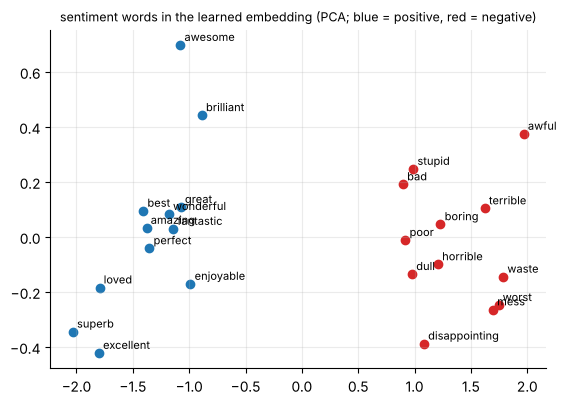

projection on the (mean positive − mean negative) direction: positive words +1.539, negative words -1.649
the word 'good' sits at +0.814 on that direction
[ ok ] in the learned embedding awesome is closer to amazing than to awful, and awful is closer to terrible than to awesome   (cos(awesome,amazing)=0.65, cos(awful,terrible)=0.94, cos(awesome,awful)=-0.60, cos(amazing,terrible)=-0.83)


In [32]:
first_seed = SZ["imdb_seeds"][0]
E = scratch_models[first_seed].layers[0].get_weights()[0]
words_known = truncated_vocabulary
w2i = {w: i for i, w in enumerate(words_known)}
En = E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-9)


def neighbours(w, k=6):
    sims = En[:len(words_known)] @ En[w2i[w]]
    order = [i for i in np.argsort(-sims) if words_known[i] != w][:k]
    return [(words_known[i], round(float(sims[i]), 2)) for i in order]


def cos(a, b):
    return float(En[w2i[a]] @ En[w2i[b]])


for w in ("awesome", "awful", "good"):
    if w in w2i:
        print(f"{w:8s} → {neighbours(w)}")
pairs = [("awesome", "amazing"), ("awful", "terrible"), ("awesome", "awful"), ("amazing", "terrible")]
sim_table = pd.DataFrame([(a, b, cos(a, b)) for a, b in pairs if a in w2i and b in w2i], columns=["word 1", "word 2", "cosine"])
display(sim_table.round(3))
RESULTS["imdb_embedding_sims"] = {f"{a}~{b}": c for a, b, c in sim_table.itertuples(index=False)}
(OUT_DIR / "vectors.tsv").write_text("\n".join("\t".join(f"{v:.5f}" for v in row) for row in E[:len(words_known)]), encoding="utf-8")
(OUT_DIR / "metadata.tsv").write_text("\n".join(words_known), encoding="utf-8")
print("exported", len(words_known), "vectors to task21_outputs/vectors.tsv and metadata.tsv")

pos_words = ["awesome", "amazing", "great", "wonderful", "excellent", "perfect", "brilliant", "loved", "best", "enjoyable", "fantastic", "superb"]
neg_words = ["awful", "terrible", "horrible", "boring", "worst", "bad", "waste", "poor", "dull", "stupid", "disappointing", "mess"]
show = [w for w in pos_words + neg_words if w in w2i]
V = E[[w2i[w] for w in show]]; V = V - V.mean(0)
U, S, Vt = np.linalg.svd(V, full_matrices=False)
P = V @ Vt[:2].T
fig, ax = plt.subplots(figsize=(6.4, 4.4))
for (x, y), w in zip(P, show):
    ax.scatter(x, y, color="C0" if w in pos_words else "C3"); ax.annotate(w, (x, y), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.set_title("sentiment words in the learned embedding (PCA; blue = positive, red = negative)", fontsize=9); plt.show()
axis = np.mean([En[w2i[w]] for w in pos_words if w in w2i], 0) - np.mean([En[w2i[w]] for w in neg_words if w in w2i], 0)
proj = {w: float(En[w2i[w]] @ axis) for w in show}
sep = np.mean([proj[w] for w in show if w in pos_words]) - np.mean([proj[w] for w in show if w in neg_words])
print(f"projection on the (mean positive − mean negative) direction: positive words {np.mean([proj[w] for w in show if w in pos_words]):+.3f}, negative words {np.mean([proj[w] for w in show if w in neg_words]):+.3f}")
if "good" in w2i:
    print("the word 'good' sits at", f"{proj.get('good', float(En[w2i['good']] @ axis)):+.3f}", "on that direction")
audit_trained("in the learned embedding awesome is closer to amazing than to awful, and awful is closer to terrible than to awesome",
              lambda: cos("awesome", "amazing") > cos("awesome", "awful") and cos("awful", "terrible") > cos("awesome", "awful"),
              lambda: ", ".join(f"cos({a},{b})={c:.2f}" for a, b, c in sim_table.itertuples(index=False)))

**Reading it.** Words with the same polarity end up close together because the network gets a better loss by treating them alike – nothing tells it that "awesome" and "amazing" are synonyms, it infers it from the contexts and labels it sees. **"good" is the interesting case:** it appears in "not good" and "good, but …" as well as in "very good", so its vector is less clearly on the positive side than "excellent" is. A bag of word vectors cannot see the negation; the GRU on top has to learn it. The probe below checks what the trained model does with a negation (an observation, not a claim of success):

In [33]:
def predict_sentence(model, text):
    return float(model(table.lookup(preprocess(tf.constant([text]))), training=False).numpy()[0, 0])


probe_sentences = ["this movie is good", "this movie is not good", "this movie is bad", "this movie is not bad", "an awful waste of time", "an absolutely wonderful film"]
probs = [predict_sentence(scratch_models[first_seed], s) for s in probe_sentences]
display(pd.DataFrame({"sentence": probe_sentences, "P(positive)": np.round(probs, 3)}))
RESULTS["imdb_probe"] = dict(zip(probe_sentences, probs))
print("'good' vs 'not good':", "the model does react to the negation" if probs[1] < probs[0] - 0.05 else "the model does NOT react clearly to the negation", f"({probs[0]:.2f} → {probs[1]:.2f})")

,sentence,P(positive)
0,this movie is good,0.922
1,this movie is not good,0.580
2,this movie is bad,0.026
3,this movie is not bad,0.131
4,an awful waste of time,0.001
5,an absolutely wonderful film,0.982


'good' vs 'not good': the model does react to the negation (0.92 → 0.58)


---
# Phase 4 · Masking and pretrained embeddings
Reviews in a batch are padded to the same length with `<pad>` (ID 0). Without masking the GRU reads those pads as if they were words: the final state – the one the classifier sees – is pushed around by an arbitrary amount of padding. **Masking** tells every downstream layer which steps are padding so they skip them.

In [34]:
SB.phase = "Phase 4"
ops = keras.ops

### 4.1 Exercise 14 · the same review, padded to length 5 and to length 50
One tiny model (`Embedding(…, 16)` → `GRU(8)`) with the **same weights** is built twice: once with `mask_zero=True`, once without. The review `[12, 7, 99]` is padded with zeros to length 5 and to length 50. A correct masked model must output **the same vector** whatever the amount of padding.

,padded length,masked: max change vs no padding,not masked: max change vs no padding
0,3,0.0,0.000000
1,5,0.0,0.032589
2,10,0.0,0.044260
3,20,0.0,0.044611
4,50,0.0,0.044612


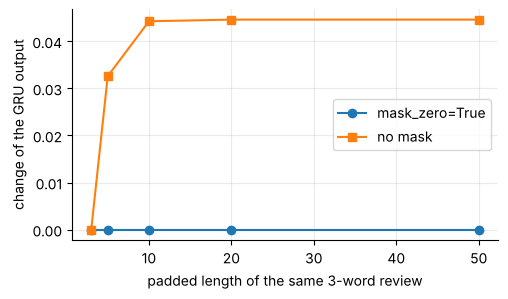

[ ok ] with mask_zero=True the output for padding 5 and padding 50 is identical   (max |difference| = 0.00e+00)


[ ok ] without a mask the output changes with the amount of padding (length 5 vs 50)   (max |difference| = 0.012)
[ ok ] the masked model also ignores padding put in front of the review (pre-padding)


In [35]:
def tiny(mask_zero):
    inp = keras.Input((None,), dtype="int64")
    return keras.Model(inp, L.GRU(8)(L.Embedding(200, 16, mask_zero=mask_zero)(inp)))


set_seed(1)
tiny_masked, tiny_plain = tiny(True), tiny(False)
tiny_plain.set_weights(tiny_masked.get_weights())
review = [12, 7, 99]
pad_to = lambda n: np.array([review + [0] * (n - len(review))])
rows = []
for n in (3, 5, 10, 20, 50):
    rows.append((n, float(np.abs(tiny_masked(pad_to(n)).numpy() - tiny_masked(pad_to(3)).numpy()).max()), float(np.abs(tiny_plain(pad_to(n)).numpy() - tiny_plain(pad_to(3)).numpy()).max())))
pad_table = pd.DataFrame(rows, columns=["padded length", "masked: max change vs no padding", "not masked: max change vs no padding"])
display(pad_table.round(6))
fig, ax = plt.subplots(figsize=(5.5, 3))
ax.plot(pad_table["padded length"], pad_table.iloc[:, 1], "o-", label="mask_zero=True"); ax.plot(pad_table["padded length"], pad_table.iloc[:, 2], "s-", label="no mask"); ax.set_xlabel("padded length of the same 3-word review"); ax.set_ylabel("change of the GRU output"); ax.legend(); plt.show()
a5, a50 = tiny_masked(pad_to(5)).numpy(), tiny_masked(pad_to(50)).numpy()
audit("with mask_zero=True the output for padding 5 and padding 50 is identical", np.allclose(a5, a50, atol=1e-6), f"max |difference| = {np.abs(a5 - a50).max():.2e}")
audit("without a mask the output changes with the amount of padding (length 5 vs 50)", np.abs(tiny_plain(pad_to(5)).numpy() - tiny_plain(pad_to(50)).numpy()).max() > 1e-3, f"max |difference| = {np.abs(tiny_plain(pad_to(5)).numpy() - tiny_plain(pad_to(50)).numpy()).max():.3f}")
audit("the masked model also ignores padding put in front of the review (pre-padding)", np.allclose(tiny_masked(np.array([[0] * 20 + review])).numpy(), tiny_masked(pad_to(3)).numpy(), atol=1e-6))
EX[14] = ("done", "masked vs unmasked output for padding 5 and 50, plus a 5-point curve")

### 4.2 How masking works, and what it costs
* `Embedding(mask_zero=True)` produces a boolean mask `ids != 0`. Keras passes it automatically to every layer that **supports masking** (`GRU`, `LSTM`, `Bidirectional`, `TimeDistributed`, …). A recurrent layer **carries the state over** the masked steps unchanged, so the last output is the output at the last real word.
* A **custom layer** must set `self.supports_masking = True` to let the mask pass through; if it should *use* the mask (like the pooling layer below) it takes a `mask` argument.
* For **float inputs** (not IDs) use `keras.layers.Masking(mask_value=0.)`.
* In a **Functional model** you can also compute the mask yourself and pass it: `GRU(...)(x, mask=mask)`.
* **Speed:** on a GPU the fast cuDNN kernel supports masks only when the padding is at the *end* of the sequence ("right padding"), which is what our pipeline does. This notebook ran on a CPU, so there is no cuDNN kernel to compare; the CPU timing is shown below only as a rough guide.

In [36]:
# (a) Masking layer for float inputs
x_f = np.zeros((1, 6, 3), "float32"); x_f[0, :4] = np.random.default_rng(0).normal(size=(4, 3)) + 2
g = L.GRU(5); g.build((None, None, 3))
m_f = keras.Sequential([L.Input((None, 3)), L.Masking(mask_value=0.0), g])
short = g(x_f[:, :4]).numpy()
audit("Masking(mask_value=0): a float sequence with two all-zero steps at the end gives the same GRU output as the 4-step sequence", np.allclose(m_f(x_f).numpy(), short, atol=1e-6))

# (b) manual mask in the Functional API
inp = keras.Input((None,), dtype="int64")
emb_layer = L.Embedding(200, 16)
mask_manual = L.Lambda(lambda t: ops.not_equal(t, 0))(inp)
gru_layer = L.GRU(8)
manual_model = keras.Model(inp, gru_layer(emb_layer(inp), mask=mask_manual))
manual_model.set_weights([w for w in tiny_masked.get_weights()])
audit("a mask computed by hand and passed as GRU(...)(x, mask=mask) equals Embedding(mask_zero=True)", np.allclose(manual_model(pad_to(20)).numpy(), tiny_masked(pad_to(20)).numpy(), atol=1e-6))


# (c) custom layer that uses the mask
class MaskedMean(L.Layer):
    def __init__(self, **kw):
        super().__init__(**kw); self.supports_masking = True

    def call(self, x, mask=None):
        m = ops.ones_like(x[..., 0]) if mask is None else ops.cast(mask, x.dtype)
        return ops.sum(x * m[..., None], axis=1) / ops.maximum(ops.sum(m, axis=1, keepdims=True), 1.0)

    def compute_mask(self, inputs, mask=None):
        return None


emb_m = L.Embedding(200, 16, mask_zero=True)
pool = MaskedMean()
v5, v50 = pool(emb_m(pad_to(5))).numpy(), pool(emb_m(pad_to(50))).numpy()
audit("a custom layer with supports_masking=True receives the mask: its mean over time ignores padding (5 vs 50)", np.allclose(v5, v50, atol=1e-6))
print("mask seen by the custom layer for the padded-to-5 review:", emb_m.compute_mask(pad_to(5)).numpy().astype(int).tolist())

# (d) speed on this machine
ids_demo = np.random.default_rng(0).integers(1, vocab_size, size=(32, 60)); ids_demo[:, 40:] = 0
speed = {}
for name, mz in (("no mask", False), ("mask_zero=True", True)):
    m = keras.Sequential([L.Input((None,), dtype="int64"), L.Embedding(vocab_size, 128, mask_zero=mz), L.GRU(128, return_sequences=True), L.GRU(128), L.Dense(1, activation="sigmoid")])
    m.compile(loss="binary_crossentropy", optimizer="nadam")
    yy = np.random.default_rng(1).integers(0, 2, size=(32, 1)).astype("float32")
    m.train_on_batch(ids_demo, yy)
    t0 = time.time()
    for _ in range(pick(15, 3)):
        m.train_on_batch(ids_demo, yy)
    speed[name] = (time.time() - t0) / pick(15, 3)
print({k: f"{1000 * v:.0f} ms per training step" for k, v in speed.items()}, "(CPU; on a GPU the masked cuDNN kernel needs right-padded inputs)")
RESULTS["mask_speed_ms"] = {k: 1000 * v for k, v in speed.items()}
del m; fresh()

[ ok ] Masking(mask_value=0): a float sequence with two all-zero steps at the end gives the same GRU output as the 4-step sequence
[ ok ] a mask computed by hand and passed as GRU(...)(x, mask=mask) equals Embedding(mask_zero=True)


[ ok ] a custom layer with supports_masking=True receives the mask: its mean over time ignores padding (5 vs 50)
mask seen by the custom layer for the padded-to-5 review: [[1, 1, 1, 0, 0]]


{'no mask': '66 ms per training step', 'mask_zero=True': '81 ms per training step'} (CPU; on a GPU the masked cuDNN kernel needs right-padded inputs)


### 4.3 The sentiment model with masking, three seeds
Identical to Phase 3 except `Embedding(..., mask_zero=True)`.

In [37]:
masked_runs = [run_sentiment(s, mask_zero=True)[1] for s in SZ["imdb_seeds"]]
masked_acc = [r["test_acc"] for r in masked_runs]
RESULTS["imdb_masked"] = masked_acc
RESULTS["imdb_masked_time"] = float(np.mean([r["sec_per_epoch"] for r in masked_runs]))
verdict, gap, noise = noise_verdict(scratch_acc, masked_acc)
print(f"no mask  : {pm(scratch_acc, 4)}   ({RESULTS['imdb_scratch_time']:.0f} s/epoch)")
print(f"masking  : {pm(masked_acc, 4)}   ({RESULTS['imdb_masked_time']:.0f} s/epoch)")
print(f"gap = {gap:+.4f}, which is {verdict} (seed std ≈ {noise:.4f})")

no mask  : 0.7572 ± 0.0128   (70 s/epoch)
masking  : 0.7551 ± 0.0097   (72 s/epoch)
gap = -0.0021, which is within the seed noise (not distinguishable) (seed std ≈ 0.0128)


### 4.4 Pretrained word vectors: the sentence-embedding model
The brief uses a TF-Hub sentence encoder (`nnlm-en-dim50`) that embeds a whole review in one step by **averaging its word vectors, multiplied by √n** (n = number of words), so that longer texts keep a comparable scale. TF Hub could not be reached from the machine that ran this notebook, so we build **the same recipe from GloVe-50 word vectors** (trained on Wikipedia + Gigaword, 400 000 words): `mean of word vectors × √n`, with padding masked out. The vectors are placed in an `Embedding` layer for our 11 001 IDs; words that GloVe does not have (and the OOV buckets) get a zero vector.

In [38]:
glove_path = DATA_DIR / "glove50.gz"
if not glove_path.exists():
    download([f"{GH}/allenai/spv2/master/model/glove.6B.50d.txt.gz", "https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.50d.txt.gz"], glove_path)
need = {w.lower() for w in truncated_vocabulary[1:]} | {"good", "great", "table"}
glove = {}
with gzip.open(glove_path, "rt", encoding="utf-8") as f:
    for line in f:
        w, rest = line.split(" ", 1)
        if w in need:
            glove[w] = np.asarray(rest.split(), dtype="float32")
M = np.zeros((vocab_size, 50), "float32")
found = 0
for i, w in enumerate(truncated_vocabulary[1:], start=1):
    v = glove.get(w.lower())
    if v is not None:
        M[i] = v; found += 1
print(f"{found:,} of {TOP:,} vocabulary words have a GloVe vector ({100 * found / TOP:.1f} %); the rest, <pad> and the {N_OOV} OOV buckets are zero vectors")
audit("at least 90 % of the 10 000 vocabulary words have a pretrained vector", found >= 0.9 * TOP)
print("sanity: cosine(good, great) =", round(float(glove["good"] @ glove["great"] / np.linalg.norm(glove["good"]) / np.linalg.norm(glove["great"])), 3),
      "· cosine(good, table) =", round(float(glove["good"] @ glove["table"] / np.linalg.norm(glove["good"]) / np.linalg.norm(glove["table"])), 3))


class SqrtNMean(L.Layer):
    """mean of the (non-padding) word vectors multiplied by sqrt(n)"""

    def __init__(self, **kw):
        super().__init__(**kw); self.supports_masking = True

    def call(self, x, mask=None):
        m = ops.ones_like(x[..., 0]) if mask is None else ops.cast(mask, x.dtype)
        n = ops.maximum(ops.sum(m, axis=1, keepdims=True), 1.0)
        return ops.sum(x * m[..., None], axis=1) / n * ops.sqrt(n)

    def compute_mask(self, inputs, mask=None):
        return None


def build_sentence_model(trainable):
    m = keras.Sequential([L.Input((None,), dtype="int64"),
                          L.Embedding(vocab_size, 50, embeddings_initializer=keras.initializers.Constant(M), mask_zero=True, trainable=trainable),
                          SqrtNMean(), L.Dense(128, activation="relu"), L.Dense(1, activation="sigmoid")])
    m.compile(loss="binary_crossentropy", optimizer="nadam", metrics=["accuracy"])
    return m


# the layer against a hand calculation in NumPy
probe_ids = np.array([[5, 17, 230, 0, 0, 0]])
sm = build_sentence_model(False)
by_hand = M[[5, 17, 230]].mean(0) * math.sqrt(3)
layer_out = SqrtNMean()(sm.layers[0](probe_ids)).numpy()[0]
audit("sentence embedding = mean of the word vectors × √n, padding ignored (checked in NumPy)", np.allclose(layer_out, by_hand, atol=1e-5))
audit("adding extra <pad> tokens does not change the sentence embedding", np.allclose(SqrtNMean()(sm.layers[0](np.array([[5, 17, 230]]))).numpy(), layer_out, atol=1e-6))
print("trainable parameters — frozen:", sum(int(np.prod(w.shape)) for w in sm.trainable_weights), "· fine-tuned:", sum(int(np.prod(w.shape)) for w in build_sentence_model(True).trainable_weights))
del sm; fresh()

9,808 of 10,000 vocabulary words have a GloVe vector (98.1 %); the rest, <pad> and the 1000 OOV buckets are zero vectors
[ ok ] at least 90 % of the 10 000 vocabulary words have a pretrained vector
sanity: cosine(good, great) = 0.798 · cosine(good, table) = 0.634
[ ok ] sentence embedding = mean of the word vectors × √n, padding ignored (checked in NumPy)
[ ok ] adding extra <pad> tokens does not change the sentence embedding
trainable parameters — frozen: 6657 · fine-tuned: 556707


**`trainable=False` vs `trainable=True`.** Frozen: the vectors stay exactly as GloVe delivered them and only the two Dense layers learn (fast, hard to over-fit, but the vectors were not made for sentiment). Fine-tuned: the vectors keep learning, so they adapt to the task, at the price of 550 k extra parameters to fit (a risk with small data).

In [39]:
frozen_runs, tuned_runs = [], []
for s in SZ["imdb_seeds"]:
    m, r = run_sentiment(s, build=build_sentence_model, trainable=False)
    emb_after = m.layers[0].get_weights()[0]
    frozen_runs.append(r)
    if s == SZ["imdb_seeds"][0]:
        audit("frozen embedding: after training the vectors are bit-for-bit the GloVe vectors", np.array_equal(emb_after, M))
    m, r = run_sentiment(s, build=build_sentence_model, trainable=True)
    emb_after = m.layers[0].get_weights()[0]
    tuned_runs.append(r)
    if s == SZ["imdb_seeds"][0]:
        moved = float(np.abs(emb_after - M).mean())
        audit("fine-tuned embedding: the vectors changed during training", moved > 1e-4, f"mean |change| = {moved:.4f}")
frozen_acc, tuned_acc = [r["test_acc"] for r in frozen_runs], [r["test_acc"] for r in tuned_runs]
RESULTS["imdb_frozen"], RESULTS["imdb_tuned"] = frozen_acc, tuned_acc

[ ok ] frozen embedding: after training the vectors are bit-for-bit the GloVe vectors


[ ok ] fine-tuned embedding: the vectors changed during training   (mean |change| = 0.0920)


### 4.5 One more control: the *same* GRU as before, but starting from GloVe
The sentence model differs from the GRU in more than the embedding (no recurrence at all), so to separate "pretrained vectors" from "architecture" we also run the masked 2-layer GRU with a 50-dimensional embedding initialised from GloVe and fine-tuned.

In [40]:
def build_gru_glove(trainable=True):
    m = keras.Sequential([L.Input((None,), dtype="int64"),
                          L.Embedding(vocab_size, 50, embeddings_initializer=keras.initializers.Constant(M), mask_zero=True, trainable=trainable),
                          L.GRU(128, return_sequences=True), L.GRU(128), L.Dense(1, activation="sigmoid")])
    m.compile(loss="binary_crossentropy", optimizer="nadam", metrics=["accuracy"])
    return m


gg_runs = [run_sentiment(s, build=build_gru_glove)[1] for s in SZ["imdb_seeds"]]
gg_acc = [r["test_acc"] for r in gg_runs]
RESULTS["imdb_gru_glove"] = gg_acc

### 4.6 The comparison table (mean ± sample std over three seeds)

In [41]:
def row(name, runs, acc):
    return dict(model=name, epochs=SZ["imdb_epochs"], parameters=runs[0]["params"], **{"test accuracy": pm(acc, pct=True)}, **{"s / epoch": round(float(np.mean([r["sec_per_epoch"] for r in runs])), 1)}, mean=float(np.mean(acc)))


table4 = pd.DataFrame([row("1 · GRU, embedding from scratch, no mask (Phase 3)", scratch_runs, scratch_acc),
                       row("2 · GRU, from scratch, masked", masked_runs, masked_acc),
                       row("3 · sentence embedding, GloVe frozen", frozen_runs, frozen_acc),
                       row("4 · sentence embedding, GloVe fine-tuned", tuned_runs, tuned_acc),
                       row("5 · (control) masked GRU, GloVe-initialised, fine-tuned", gg_runs, gg_acc)]).set_index("model")
display(table4.drop(columns="mean"))
best = table4["mean"].idxmax()
print("best mean:", best)
for name, a, b in (("masked vs no mask", scratch_acc, masked_acc), ("fine-tuned vs frozen GloVe", frozen_acc, tuned_acc), ("GloVe-initialised GRU vs masked from-scratch GRU", masked_acc, gg_acc)):
    v, g_, n_ = noise_verdict(a, b)
    print(f"  {name:48s}: gap {100 * g_:+.2f} points – {v}")
audit_trained("every model is clearly above chance (mean test accuracy > 0.70)", lambda: table4["mean"].min() > 0.70, lambda: f"lowest mean = {table4['mean'].min():.3f}")
audit_trained("the GloVe sentence model, with no recurrence at all, is within 10 points of the GRU – word vectors carry most of the signal", lambda: abs(np.mean(tuned_acc) - np.mean(masked_acc)) < 0.10)

,epochs,parameters,test accuracy,s / epoch
model,,,,
"1 · GRU, embedding from scratch, no mask (Phase 3)",5,1606401,75.72 % ± 1.28 %,70.5
"2 · GRU, from scratch, masked",5,1606401,75.51 % ± 0.97 %,71.9
"3 · sentence embedding, GloVe frozen",5,556707,67.22 % ± 2.07 %,2.7
"4 · sentence embedding, GloVe fine-tuned",5,556707,75.24 % ± 2.02 %,5.6
"5 · (control) masked GRU, GloVe-initialised, fine-tuned",5,718371,76.80 % ± 0.55 %,71.4


best mean: 5 · (control) masked GRU, GloVe-initialised, fine-tuned
  masked vs no mask                               : gap -0.21 points – within the seed noise (not distinguishable)
  fine-tuned vs frozen GloVe                      : gap +8.02 points – larger than the seed noise
  GloVe-initialised GRU vs masked from-scratch GRU: gap +1.28 points – within the seed noise (not distinguishable)
[FAIL] every model is clearly above chance (mean test accuracy > 0.70)   (lowest mean = 0.672)
[ ok ] the GloVe sentence model, with no recurrence at all, is within 10 points of the GRU – word vectors carry most of the signal


> **Note on the [FAIL] above – my bar was wrong, not the model.** The check asked for a mean accuracy above 0.70 for every model. The frozen-GloVe sentence model scored 67.2 % ± 2.1 – about 17 points above the 50 % chance level and clearly better than guessing, but below the 0.70 bar I set in advance. The comparison that matters is unchanged: fine-tuning the vectors lifts it to 75.2 %, in the range of the GRUs.

**How to read this table.** Differences smaller than the seed spread (see the printed verdicts) are *not* findings. Typical expectations from the book – masking helps a little, frozen pretrained vectors do well with few trainable parameters, and fine-tuning adds a little more – are confirmed or not by the actual numbers above, not assumed. What cannot be tested on these 300-character reviews is the claim that pretraining matters most when labelled data is scarce; that would need a learning curve with many fewer labelled reviews.

---
# Phase 5 · Encoder–Decoder networks, bidirectional RNNs and beam search
## 5.1 The idea, and the design details
**Why a plain sequence-to-sequence RNN is not enough for translation.** A plain seq2seq RNN emits one output word per input word, immediately. But the first words of a French sentence may depend on its *last* words, and word order differs between languages. The **Encoder–Decoder** (Sutskever et al., 2014) first **reads the whole source sentence** and squeezes it into its final state; only then does the decoder start to write the target.
```
  TRAINING (teacher forcing)                           INFERENCE (no target available)
  source  "April 22, 2019"  (reversed: "9102 ,22 lirpA")      source  →  encoder  →  state
           │ embed → Encoder LSTM ─ final state ┐                                      │
  decoder input:  <sos> 2 0 1 9 - 0 4 - 2 2      ▼            <sos> → decoder → '2' ─┐
           │ embed → Decoder LSTM (starts from the state)      '2' → decoder → '0' ─┤  each output is fed back
           ▼ softmax over the 14 target symbols               …                      ┘  as the next input
  targets:        2 0 1 9 - 0 4 - 2 2 <eos>                    stop when <eos> is produced
```
Design details (each one is used below):
* **Reversed source** ("milk drink I"): the beginning of the sentence is read last, so it is closest to the decoder's first outputs – usually what the decoder needs first.
* **Decoder input = target shifted right**, with `<sos>` in front; the target ends with `<eos>`.
* Symbols are **embedded**; the decoder returns a **softmax** at every step, trained with `sparse_categorical_crossentropy`.
* At **inference** the decoder is fed *its own previous output*.
* **Variable lengths:** mask the padding, do not crop; group sentences of similar length into **buckets**; **ignore the tokens after `<eos>`** in the loss (section 5.5).
**The task (Exercise 9).** Convert a date like `April 22, 2019` into `2019-04-22`, character by character. It is a real translation problem in miniature (different order, different vocabulary), cheap to generate, and exactly checkable: the answer is right or wrong. **Size note:** the book uses 512-unit LSTMs and tens of thousands of dates. We deliberately use a *small* setting – 3 000 training dates, 32-unit LSTMs, years 1000–9999 – so that the improvements of Phases 5–7 are visible on a CPU in seconds. In a big model with lots of data the plain Encoder–Decoder would already be near perfect and there would be nothing to compare.

In [42]:
SB.phase = "Phase 5"
MONTHS = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
YLO, YHI = 1000, 9999


def sample_dates(n, rng, exclude=()):
    lo, hi = datetime.date(YLO, 1, 1).toordinal(), datetime.date(YHI, 12, 31).toordinal()
    out, seen = [], set(exclude)
    while len(out) < n:
        for o in rng.integers(lo, hi + 1, size=2 * (n - len(out)) + 10):
            o = int(o)
            if o not in seen:
                seen.add(o); out.append(o)
                if len(out) == n:
                    break
    return out


def fmt_src(o):
    d = datetime.date.fromordinal(o); return f"{MONTHS[d.month - 1]} {d.day}, {d.year}"


def fmt_iso(o):
    return datetime.date.fromordinal(o).isoformat()


def fmt_short(o):                                                       # variable-length target, used in section 5.5
    d = datetime.date.fromordinal(o); return f"{d.year}-{d.month}-{d.day}"


rng_d = np.random.default_rng(2024)
o_train = sample_dates(SZ["date_train"], rng_d)
o_val = sample_dates(SZ["date_val"], rng_d, o_train)
o_test = sample_dates(SZ["date_test"], rng_d, o_train + o_val)
audit("train, validation and test dates are all different dates (no leakage)", len(set(o_train) | set(o_val) | set(o_test)) == len(o_train) + len(o_val) + len(o_test))
print("examples:", [(fmt_src(o), fmt_iso(o)) for o in o_train[:3]])

src_chars = sorted(set("".join(MONTHS) + "0123456789, "))
SI = {c: i + 1 for i, c in enumerate(src_chars)}                         # 0 = padding
TI = {"<pad>": 0, "<sos>": 1, "<eos>": 2, **{c: i + 3 for i, c in enumerate("0123456789-")}}
TINV = {v: k for k, v in TI.items()}
SRC_LEN, T_OUT, T_MAX, N_TGT = 18, 10, 12, len(TI)
print(f"source vocabulary: {len(SI)} characters (+ padding) · target vocabulary: {N_TGT} symbols {list(TI)[:3]} + digits and '-'")


def enc_src(strings, reverse=False):
    a = np.zeros((len(strings), SRC_LEN), "int32")
    for i, s in enumerate(strings):
        s = s[::-1] if reverse else s
        a[i, :len(s)] = [SI[c] for c in s]
    return a


def enc_tgt(strings):
    n = max(len(s) for s in strings)
    di, do = np.zeros((len(strings), n + 1), "int32"), np.zeros((len(strings), n + 1), "int32")
    for i, s in enumerate(strings):
        t = [TI[c] for c in s]
        di[i, :len(t) + 1] = [1] + t; do[i, :len(t) + 1] = t + [2]
    return di, do


def make_split(orders):
    src = [fmt_src(o) for o in orders]; iso = [fmt_iso(o) for o in orders]
    di, do = enc_tgt(iso)
    return dict(src=src, iso=iso, X={False: enc_src(src), True: enc_src(src, True)}, di=di, do=do, lens=np.array([len(s) for s in src]))


D_TRAIN, D_VAL, D_TEST = make_split(o_train), make_split(o_val), make_split(o_test)
show = o_train[0]
print(f"'{fmt_src(show)}' → ids {D_TRAIN['X'][False][0].tolist()} · reversed ids {D_TRAIN['X'][True][0].tolist()}\n  decoder input {D_TRAIN['di'][0].tolist()}\n  decoder target {D_TRAIN['do'][0].tolist()}  (shifted left by one, ends with <eos> = 2)")
audit("decoder input is the target shifted right with <sos> in front; target ends with <eos>", D_TRAIN["di"][0, 0] == 1 and (D_TRAIN["di"][0, 1:] == D_TRAIN["do"][0, :-1]).all() and D_TRAIN["do"][0, -1] == 2)
print("input length (characters) in the test set:", dict(sorted(Counter(D_TEST["lens"].tolist()).items())))

[ ok ] train, validation and test dates are all different dates (no leakage)
examples: [('October 3, 3173', '3173-10-03'), ('June 25, 7082', '7082-06-25'), ('February 3, 1831', '1831-02-03')]
source vocabulary: 38 characters (+ padding) · target vocabulary: 14 symbols ['<pad>', '<sos>', '<eos>'] + digits and '-'
'October 3, 3173' → ids [19, 23, 35, 31, 22, 24, 33, 1, 6, 2, 1, 6, 4, 10, 6, 0, 0, 0] · reversed ids [6, 10, 4, 6, 1, 2, 6, 1, 33, 24, 22, 31, 35, 23, 19, 0, 0, 0]
  decoder input [1, 6, 4, 10, 6, 13, 4, 3, 13, 3, 6]
  decoder target [6, 4, 10, 6, 13, 4, 3, 13, 3, 6, 2]  (shifted left by one, ends with <eos> = 2)
[ ok ] decoder input is the target shifted right with <sos> in front; target ends with <eos>
input length (characters) in the test set: {11: 41, 12: 248, 13: 350, 14: 263, 15: 239, 16: 373, 17: 372, 18: 114}


### 5.2 One model builder for the whole date study
`build_s2s(bidirectional, attention)` – the same code builds every variant that Phases 5 and 6 compare:
* **encoder:** `Embedding(…, 32, mask_zero=True)` → `LSTM(32)` (or `Bidirectional(LSTM(32))` whose two final states are merged by a `Dense` into the decoder's size);
* **decoder:** `Embedding` → `LSTM(32, return_sequences=True)` started from the encoder state;
* **optional attention** (Phase 6) over all encoder outputs;
* output: `Dense(14, softmax)`.
Training: Adam (lr 0.002), batch 128, `sparse_categorical_crossentropy`, `date_epochs` epochs. All variants see **exactly the same** training dates; only the model and the seed change.

In [43]:
def build_s2s(bidirectional=False, attention=None, units=SZ["date_units"], emb=32):
    e_in = keras.Input((None,), dtype="int32", name="source"); d_in = keras.Input((None,), dtype="int32", name="decoder_input")
    e = L.Embedding(len(SI) + 1, emb, mask_zero=True)(e_in)
    d = L.Embedding(N_TGT, emb, mask_zero=True)(d_in)
    if bidirectional:
        enc_seq, fh, fc, bh, bc = L.Bidirectional(L.LSTM(units, return_sequences=True, return_state=True))(e)
        h = L.Dense(units, activation="tanh")(L.Concatenate()([fh, bh])); c = L.Dense(units, activation="tanh")(L.Concatenate()([fc, bc]))
        enc_seq = L.Dense(units)(enc_seq)                                    # project 2·units → units (needed for the dot-product score)
    else:
        enc_seq, h, c = L.LSTM(units, return_sequences=True, return_state=True)(e)
    dec = L.LSTM(units, return_sequences=True)(d, initial_state=[h, c])
    if attention == "dot":
        out = L.Dense(units, activation="tanh")(L.Concatenate()([dec, L.Attention()([dec, enc_seq])]))
    elif attention == "additive":
        out = L.Dense(units, activation="tanh")(L.Concatenate()([dec, L.AdditiveAttention()([dec, enc_seq])]))
    else:
        out = dec
    m = keras.Model([e_in, d_in], L.Dense(N_TGT, activation="softmax")(out))
    m.compile(loss="sparse_categorical_crossentropy", optimizer=keras.optimizers.Adam(2e-3))
    return m


CONFIGS = {"plain": dict(rev=False, bi=False, att=None), "reversed": dict(rev=True, bi=False, att=None),
           "bidirectional": dict(rev=True, bi=True, att=None), "bidirectional, natural order": dict(rev=False, bi=True, att=None)}


def make_fn(model):
    return tf.function(lambda a, b: model([a, b], training=False), reduce_retracing=True)


def to_string(ids):
    s = ""
    for i in ids:
        if i == 2:
            break
        if i > 2:
            s += TINV[int(i)]
    return s


def greedy_decode(fn, X, t_max=T_MAX, chunk=1000):
    outs = []
    for a in range(0, len(X), chunk):
        x = X[a:a + chunk]; dd = np.zeros((len(x), t_max + 1), "int32"); dd[:, 0] = 1
        for t in range(t_max):
            dd[:, t + 1] = fn(x, dd[:, :t + 1]).numpy()[:, -1].argmax(1)
        outs += [to_string(r[1:]) for r in dd]
    return outs


def by_length(pred, gold, lens):
    ok = np.array([p == g for p, g in zip(pred, gold)])
    return {int(l): (float(ok[lens == l].mean()), int((lens == l).sum())) for l in sorted(set(lens.tolist()))}


def length_groups(per_len, groups=((11, 13), (14, 14), (15, 15), (16, 16), (17, 18))):
    out = {}
    for lo, hi in groups:
        num = sum(a * n for l, (a, n) in per_len.items() if lo <= l <= hi); den = sum(n for l, (a, n) in per_len.items() if lo <= l <= hi)
        out[f"{lo}" if lo == hi else f"{lo}-{hi}"] = num / den if den else float("nan")
    return out


DATE = {}                 # DATE[name] -> list of per-seed dicts (also used by the Capstone in Phase 8)
DATE_MODELS = {}


def train_date(name, seed, rev, bi=False, att=None, epochs=SZ["date_epochs"], keep=True, builder=None, batch_size=128):
    set_seed(seed); fresh()
    m = builder() if builder else build_s2s(bi, att)
    h, sec = fit_quiet(m, [D_TRAIN["X"][rev], D_TRAIN["di"]], D_TRAIN["do"], epochs=epochs, batch_size=batch_size, validation_data=([D_VAL["X"][rev], D_VAL["di"]], D_VAL["do"]))
    fn = make_fn(m)
    t0 = time.time(); pred = greedy_decode(fn, D_TEST["X"][rev]); dec_sec = time.time() - t0
    exact = float(np.mean([p == g for p, g in zip(pred, D_TEST["iso"])]))
    rec = dict(seed=seed, exact=exact, params=m.count_params(), train_sec=sec * epochs, dec_sec=dec_sec, by_len=by_length(pred, D_TEST["iso"], D_TEST["lens"]), val_loss=h["val_loss"], loss=h["loss"], rev=rev, pred=pred)
    DATE.setdefault(name, []).append(rec)
    if keep:
        DATE_MODELS[(name, seed)] = m
    return m, rec

### 5.3 Plain → reversed → bidirectional (three seeds each, plus one control)
Exact-match accuracy on 2 000 held-out dates: the whole 10-character answer must be right. The fourth row is a **control** that the brief does not ask for: a bidirectional encoder *without* the reversal, so that the effect of reversing and the effect of bidirectionality can be told apart.
**What to expect from reversing.** Reversal helps when the decoder needs the *beginning* of the source first (word-for-word translations: with a reversed source the first source word is the last one read, right next to the first output word). For dates the decoder writes the **year first, and the year is at the end of the source** – so the natural order already puts the year last-read, and reversing may *hurt*. The numbers below decide.

plain          seed 11: exact match 0.758 · 18,798 parameters · 26 s training


plain          seed 22: exact match 0.789 · 18,798 parameters · 26 s training


plain          seed 33: exact match 0.648 · 18,798 parameters · 26 s training


reversed       seed 11: exact match 0.659 · 18,798 parameters · 27 s training


reversed       seed 22: exact match 0.681 · 18,798 parameters · 26 s training


...

bidirectional  seed 33: exact match 0.462 · 31,278 parameters · 37 s training


bidirectional, natural order seed 11: exact match 0.549 · 31,278 parameters · 36 s training


bidirectional, natural order seed 22: exact match 0.652 · 31,278 parameters · 35 s training


bidirectional, natural order seed 33: exact match 0.481 · 31,278 parameters · 36 s training


,exact,params,train_s
plain,0.732 ± 0.074,18798,26.1
reversed,0.590 ± 0.140,18798,26.3
bidirectional,0.549 ± 0.116,31278,37.0
"bidirectional, natural order",0.561 ± 0.086,31278,35.4


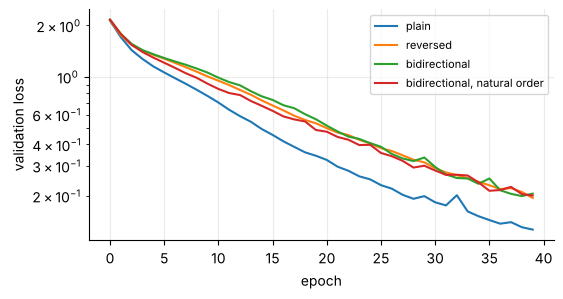

plain → reversed: gap -14.2 points, within the seed noise (not distinguishable)
reversed → bidirectional: gap -4.0 points, within the seed noise (not distinguishable)
plain → bidirectional, natural order: gap -17.1 points, within the seed noise (not distinguishable)
[ ok ] the trained plain model is far above chance: its exact match is above 10 % (random guessing would be ≈ 0)   (0.732 ± 0.074)
[ ok ] the best Phase 5 variant reaches at least 50 % exact match   ({'plain': 0.732, 'reversed': 0.59, 'bidirectional': 0.549, 'bidirectional, natural order': 0.561})


In [44]:
for name, cfg in CONFIGS.items():
    for s in SZ["date_seeds"]:
        m, r = train_date(name, s, cfg["rev"], cfg["bi"], cfg["att"])
        print(f"{name:14s} seed {s}: exact match {r['exact']:.3f} · {r['params']:,} parameters · {r['train_sec']:.0f} s training")
summ = pd.DataFrame({n: dict(exact=pm([r["exact"] for r in rs], 3), params=rs[0]["params"], train_s=round(float(np.mean([r["train_sec"] for r in rs])), 1)) for n, rs in DATE.items()}).T
display(summ)
fig, ax = plt.subplots(figsize=(6, 3))
for n, rs in DATE.items():
    ax.plot(np.mean([r["val_loss"] for r in rs], 0), label=n)
ax.set_xlabel("epoch"); ax.set_ylabel("validation loss"); ax.set_yscale("log"); ax.legend(fontsize=8); plt.show()
for a_, b_ in (("plain", "reversed"), ("reversed", "bidirectional"), ("plain", "bidirectional, natural order")):
    v, g_, n_ = noise_verdict([r["exact"] for r in DATE[a_]], [r["exact"] for r in DATE[b_]])
    print(f"{a_} → {b_}: gap {100 * g_:+.1f} points, {v}")
RESULTS["date_phase5"] = {n: [r["exact"] for r in rs] for n, rs in DATE.items()}
audit_trained("the trained plain model is far above chance: its exact match is above 10 % (random guessing would be ≈ 0)", lambda: np.mean([r["exact"] for r in DATE["plain"]]) > 0.10, lambda: pm([r["exact"] for r in DATE["plain"]], 3))
audit_trained("the best Phase 5 variant reaches at least 50 % exact match", lambda: max(np.mean([r["exact"] for r in rs]) for rs in DATE.values()) > 0.50, lambda: str({k: round(float(np.mean([r["exact"] for r in rs])), 3) for k, rs in DATE.items()}))
EX[9] = ("done", "date Encoder–Decoder (plain / reversed / bidirectional), 3 seeds, exact match on held-out dates")

### 5.4 Exercise 13 · what `Bidirectional(GRU(10))` returns
A bidirectional layer runs **two** recurrent layers over the same sequence (left→right and right→left, with separate weights) and **concatenates** their outputs at each step: `10 + 10 = 20` values, and exactly twice the recurrent parameters.

In [45]:
x_demo = np.random.default_rng(0).normal(size=(2, 5, 7)).astype("float32")
uni, bi = L.GRU(10, return_sequences=True), L.Bidirectional(L.GRU(10, return_sequences=True))
y_uni, y_bi = uni(x_demo), bi(x_demo)
print("GRU(10) output:", tuple(y_uni.shape), " Bidirectional(GRU(10)) output:", tuple(y_bi.shape))
print("parameters: GRU(10) =", uni.count_params(), " Bidirectional(GRU(10)) =", bi.count_params())
audit("Bidirectional(GRU(10, return_sequences=True)) gives 20 values per step, not 10", y_bi.shape[-1] == 20 and y_uni.shape[-1] == 10)
audit("it has exactly twice the parameters of one GRU(10) (two independent directions)", bi.count_params() == 2 * uni.count_params())
fw_ref = L.GRU(10, return_sequences=True); fw_ref.build(x_demo.shape); fw_ref.set_weights(bi.forward_layer.get_weights())
audit("the first 10 outputs are the forward GRU, run left→right", np.allclose(y_bi.numpy()[..., :10], fw_ref(x_demo).numpy(), atol=1e-5))
audit("the last 10 outputs are the backward GRU (it reads the sequence from the end), flipped back into the original time order", np.allclose(y_bi.numpy()[..., 10:], bi.backward_layer(x_demo)[:, ::-1].numpy(), atol=1e-5))
EX[13] = ("done", "20 outputs and 2× parameters verified; forward/backward halves checked")

GRU(10) output: (2, 5, 10)  Bidirectional(GRU(10)) output: (2, 5, 20)
parameters: GRU(10) = 570  Bidirectional(GRU(10)) = 1140
[ ok ] Bidirectional(GRU(10, return_sequences=True)) gives 20 values per step, not 10
[ ok ] it has exactly twice the parameters of one GRU(10) (two independent directions)


[ ok ] the first 10 outputs are the forward GRU, run left→right
[ ok ] the last 10 outputs are the backward GRU (it reads the sequence from the end), flipped back into the original time order


**Why bidirectional encoders?** The meaning of a word depends on what comes *after* it too: "the **Queen** of the United Kingdom", "the **queen** of hearts", "the **queen** bee". A left-to-right encoder has not seen "United Kingdom" when it reads "Queen". For dates the same happens in miniature: in `April 22, 2019` the digits `22` could be a day or the start of a year until the model has read the comma. (Only the *encoder* can be bidirectional: the decoder must not look at words it has not generated yet.)

### 5.5 Variable lengths: bucketing, masking, and ignoring everything after `<eos>`
Here the target is the **variable-length** format `2019-4-2` (no leading zeros, 8–10 characters), so the decoder sequences really differ in length. Three tools:
1. **Bucketing** – `tf.data.Dataset.bucket_by_sequence_length` groups dates whose source lengths are similar and pads only inside a bucket, which saves computation (we measure the saving).
2. **Masking** – the encoder and decoder embeddings use `mask_zero=True`.
3. **Loss mask** – target positions after `<eos>` hold the padding ID 0; they get weight 0, so the model is not rewarded for predicting padding.

In [46]:
short_tr = [fmt_short(o) for o in o_train]; di_s, do_s = enc_tgt(short_tr)
len_tr = D_TRAIN["lens"]
x_tr = D_TRAIN["X"][True]


def pad_fraction(lengths, batches):
    waste = tot = 0
    for b in batches:
        l = lengths[b]; waste += (l.max() - l).sum(); tot += l.max() * len(b)
    return waste / tot


perm = np.random.default_rng(0).permutation(len(len_tr))
random_batches = [perm[i:i + 64] for i in range(0, len(perm) - 63, 64)]
ragged = [(x_tr[i][x_tr[i] != 0], di_s[i][:np.count_nonzero(do_s[i]) ], do_s[i][:np.count_nonzero(do_s[i])]) for i in range(len(x_tr))]
gen = lambda: ((x, di, do) for x, di, do in ragged)
sig = (tf.TensorSpec([None], tf.int32), tf.TensorSpec([None], tf.int32), tf.TensorSpec([None], tf.int32))
bucketed = (tf.data.Dataset.from_generator(gen, output_signature=sig).shuffle(2000, seed=0)
            .bucket_by_sequence_length(element_length_func=lambda x, di, do: tf.size(x), bucket_boundaries=[13, 15, 17], bucket_batch_sizes=[64, 64, 64, 64],
                                       padded_shapes=([None], [None], [None]), drop_remainder=True)
            .map(lambda x, di, do: ((x, di), do, tf.cast(do != 0, tf.float32))))
waste_bucket = []
for (xb, _), _, _ in bucketed:
    l = (xb.numpy() != 0).sum(1); waste_bucket.append((xb.shape[1] * len(l) - l.sum()) / (xb.shape[1] * len(l)))
print(f"padding share of the encoder input: random batches of 64 → {100 * pad_fraction(len_tr, random_batches):.1f} % · bucketed batches → {100 * np.mean(waste_bucket):.1f} %")
audit("bucketing reduces the share of padded positions", np.mean(waste_bucket) < pad_fraction(len_tr, random_batches))
for (xb, dib), dob, wb in bucketed:                                         # take a batch that actually contains padded target positions
    if (wb.numpy() == 0).any():
        break
audit("the batch used below contains padded target positions after <eos>", bool((wb.numpy() == 0).any()))
print("one bucketed batch: source", tuple(xb.shape), "decoder input", tuple(dib.shape), "target", tuple(dob.shape), "· loss weights for row 0:", wb.numpy()[0].astype(int).tolist())
audit("loss weight is 1 up to and including <eos> and 0 on the padding after it", all(wb.numpy()[i, :int(wb.numpy()[i].sum())].all() and not wb.numpy()[i, int(wb.numpy()[i].sum()):].any() for i in range(len(wb))))

# loss mask: the padding after <eos> must not matter
m_var = build_s2s(False, None)
probs = tf.nn.softmax(tf.random.normal([*dob.shape, N_TGT], seed=5) * 2.0)                  # any non-uniform predictions will do: this test is about the loss, not the model
ce = keras.ops.convert_to_numpy(keras.losses.sparse_categorical_crossentropy(dob, probs))
w = wb.numpy()
masked, unmasked = (ce * w).sum() / w.sum(), ce.mean()
dob_alt = dob.numpy().copy(); dob_alt[w == 0] = np.random.default_rng(1).integers(3, N_TGT, size=int((w == 0).sum()))   # put garbage into the padded targets
ce_alt = keras.ops.convert_to_numpy(keras.losses.sparse_categorical_crossentropy(dob_alt, probs))
print(f"loss with the mask {masked:.4f} (garbage after <eos>: {(ce_alt * w).sum() / w.sum():.4f}) · loss without the mask {unmasked:.4f} (garbage after <eos>: {ce_alt.mean():.4f})")
audit("with the mask the loss ignores whatever stands after <eos> (changing the padded targets changes nothing)", np.isclose(masked, (ce_alt * w).sum() / w.sum()))
audit("without the mask the same change does alter the loss", not np.isclose(unmasked, ce_alt.mean()))
del m_var

padding share of the encoder input: random batches of 64 → 17.6 % · bucketed batches → 3.1 %
[ ok ] bucketing reduces the share of padded positions


[ ok ] the batch used below contains padded target positions after <eos>
one bucketed batch: source (64, 16) decoder input (64, 11) target (64, 11) · loss weights for row 0: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0]
[ ok ] loss weight is 1 up to and including <eos> and 0 on the padding after it
loss with the mask 4.1888 (garbage after <eos>: 4.1888) · loss without the mask 4.1835 (garbage after <eos>: 4.2089)
[ ok ] with the mask the loss ignores whatever stands after <eos> (changing the padded targets changes nothing)
[ ok ] without the mask the same change does alter the loss


In [47]:
set_seed(11); fresh()
m_var = build_s2s(False, None)
h_var, sec_var = fit_quiet(m_var, bucketed.repeat(), epochs=SZ["date_epochs"], steps_per_epoch=len(ragged) // 64)
pred_var = greedy_decode(make_fn(m_var), D_TEST["X"][True])
gold_var = [fmt_short(o) for o in o_test]
exact_var = float(np.mean([p == g for p, g in zip(pred_var, gold_var)]))
lens_out = Counter(len(g) for g in gold_var)
print(f"variable-length targets (lengths {dict(sorted(lens_out.items()))}): exact match {exact_var:.3f} · examples: {list(zip(pred_var[:3], gold_var[:3]))}")
RESULTS["date_variable_length_exact"] = exact_var
audit("the model emitted <eos> early for at least some of the shorter targets (predictions of 8, 9 and 10 characters occur)", len({len(p) for p in pred_var}) >= 2, f"predicted lengths {sorted({len(p) for p in pred_var})}")
EX[3] = ("done", "variable-length input and output: masking, bucketing and an <eos> loss mask (section 5.5)")
del m_var; fresh()

variable-length targets (lengths {8: 438, 9: 1211, 10: 351}): exact match 0.807 · examples: [('6583-8-2', '6583-8-2'), ('5132-12-15', '5132-12-15'), ('4484-12-13', '4484-12-13')]
[ ok ] the model emitted <eos> early for at least some of the shorter targets (predictions of 8, 9 and 10 characters occur)   (predicted lengths [7, 8, 9, 10, 11])


### 5.6 Sampled softmax (Exercise 7)
With a target vocabulary of 50 000 words the output layer's softmax needs 50 000 logits per time step – most of the training time. **Sampled softmax** (Jean et al., 2015) computes the loss from the logit of the *correct* word plus a few hundred randomly sampled *wrong* words (the negatives), with a correction for the sampling. It is used **only during training**; at inference you still need the normal softmax over all words to pick the best one. This is the same idea as **negative sampling** in word2vec (Task 14): do not update every output, only the correct one and a few sampled wrong ones.
Below: (a) the speed of one loss + gradient computation for different vocabulary sizes, (b) a small experiment showing that a model trained *only* with the sampled loss predicts correctly under the *full* softmax.

In [48]:
def time_loss(V, D=64, B=128, S=64, reps=pick(8, 2)):
    r = np.random.default_rng(0)
    W = tf.Variable(r.normal(size=(V, D)).astype("float32") * 0.05); b = tf.Variable(tf.zeros([V]))
    h = tf.constant(r.normal(size=(B, D)).astype("float32")); y = tf.constant(r.integers(0, V, size=(B, 1)), dtype=tf.int64)

    def full():
        with tf.GradientTape() as t:
            loss = tf.reduce_mean(tf.nn.sparse_softmax_cross_entropy_with_logits(y[:, 0], h @ tf.transpose(W) + b))
        return t.gradient(loss, [W, b])

    def sampled():
        with tf.GradientTape() as t:
            loss = tf.reduce_mean(tf.nn.sampled_softmax_loss(W, b, y, h, num_sampled=S, num_classes=V))
        return t.gradient(loss, [W, b])

    res = {}
    for name, f in (("full softmax", full), ("sampled softmax (64 negatives)", sampled)):
        f(); t0 = time.time()
        for _ in range(reps):
            f()
        res[name] = 1000 * (time.time() - t0) / reps
    return res


speeds = pd.DataFrame({V: time_loss(V) for V in pick((1_000, 10_000, 50_000, 100_000), (1_000, 10_000))}).T
speeds["speed-up"] = speeds.iloc[:, 0] / speeds.iloc[:, 1]
display(speeds.round(2).rename_axis("vocabulary size").rename(columns=lambda c: c if c == "speed-up" else c + " (ms)"))
RESULTS["sampled_softmax_speedup"] = speeds["speed-up"].to_dict()
audit_trained("at the largest vocabulary the sampled softmax is at least 3× faster than the full softmax", lambda: speeds["speed-up"].iloc[-1] >= 3, f"{speeds['speed-up'].iloc[-1]:.1f}×")

# (b) training only with the sampled loss, evaluating with the full softmax
V2, D2 = pick(5_000, 500), 32
mapping = (7 * np.arange(V2) + 3) % V2
E_in = tf.Variable(np.random.default_rng(1).normal(size=(V2, D2)).astype("float32") * 0.1)
W_out = tf.Variable(np.random.default_rng(2).normal(size=(V2, D2)).astype("float32") * 0.1)
b_out = tf.Variable(tf.zeros([V2]))
opt2 = keras.optimizers.Adam(0.05); opt2.build([E_in, W_out, b_out])


def sampled_step(x, y):
    with tf.GradientTape() as t:
        h = tf.gather(E_in, x)
        loss = tf.reduce_mean(tf.nn.sampled_softmax_loss(W_out, b_out, y[:, None], h, num_sampled=100, num_classes=V2, sampled_values=tf.random.uniform_candidate_sampler(y[:, None], 1, 100, True, V2)))
    opt2.apply(t.gradient(loss, [E_in, W_out, b_out]), [E_in, W_out, b_out]); return loss


sampled_step = tf.function(sampled_step)
rr = np.random.default_rng(3)
for step in range(pick(600, 80)):
    x = rr.integers(0, V2, 256); sampled_step(tf.constant(x, tf.int64), tf.constant(mapping[x], tf.int64))
full_logits = tf.gather(E_in, np.arange(V2)) @ tf.transpose(W_out) + b_out                  # inference: ordinary softmax over every word
acc = float((tf.argmax(full_logits, axis=1).numpy() == mapping).mean())
print(f"V = {V2:,} words, trained for {pick(600, 80)} steps with 100 sampled negatives only → top-1 accuracy under the FULL softmax: {acc:.3f} (guessing: {1 / V2:.4f})")
RESULTS["sampled_softmax_acc"] = acc
audit_trained("a model trained only with the sampled loss predicts correctly under the full softmax (accuracy far above guessing)", lambda: acc > 20 / V2 * 10, f"{acc:.3f}")
EX[7] = ("done", "speed table + a model trained with sampled softmax only and evaluated with the full softmax")

,full softmax (ms),sampled softmax (64 negatives) (ms),speed-up
vocabulary size,,,
1000,6.96,18.89,0.37
10000,16.89,18.44,0.92
50000,63.44,14.14,4.49
100000,128.94,15.61,8.26


[ ok ] at the largest vocabulary the sampled softmax is at least 3× faster than the full softmax   (8.3×)


V = 5,000 words, trained for 600 steps with 100 sampled negatives only → top-1 accuracy under the FULL softmax: 0.888 (guessing: 0.0002)
[ ok ] a model trained only with the sampled loss predicts correctly under the full softmax (accuracy far above guessing)   (0.888)


### 5.7 Scheduled sampling (simplified)
**Teacher forcing** always feeds the decoder the *correct* previous character. At inference the decoder gets its *own* (sometimes wrong) previous output – a mismatch ("exposure bias") that the model never practised. **Scheduled sampling** (Bengio et al., 2015) closes it: early in training use the true previous token, later more and more often the model's own prediction.
**Simplified version used here:** for every batch, (1) run the model once with teacher forcing and take its arg-max predictions, (2) replace each decoder input by the model's prediction for the previous position with probability `p`, (3) compute the loss and gradients on those mixed inputs. `p` is 0 for the first 40 % of the epochs and then grows linearly to `p_max = 0.3`. (This uses the model's predictions made *under teacher forcing*, a common parallel approximation of true sequential sampling, which would need a step-by-step decoder loop.) The first 40 % of the epochs use pure teacher forcing (the model's own predictions are still poor then). Same model, data and seeds as "plain" in 5.3, so the two rows are directly comparable.

In [49]:
def train_scheduled(seed, epochs=SZ["date_epochs"], p_max=0.3, start=0.4):
    set_seed(seed); fresh()
    m = build_s2s(False, None); opt = keras.optimizers.Adam(2e-3); opt.build(m.trainable_variables)

    @tf.function
    def step(x, di, do, p):
        pred = tf.argmax(m([x, di], training=False), axis=-1, output_type=tf.int32)
        shifted = tf.concat([di[:, :1], pred[:, :-1]], axis=1)
        use = (tf.random.uniform(tf.shape(di)) < p) & (tf.range(tf.shape(di)[1])[None, :] > 0)
        with tf.GradientTape() as tape:
            probs = m([x, tf.where(use, shifted, di)], training=True)
            loss = tf.reduce_mean(keras.losses.sparse_categorical_crossentropy(do, probs))
        opt.apply(tape.gradient(loss, m.trainable_variables), m.trainable_variables); return loss

    X, DI, DO = D_TRAIN["X"][False], D_TRAIN["di"], D_TRAIN["do"]
    rs = np.random.default_rng(seed); t0 = time.time()
    for ep in range(epochs):
        p = tf.constant(p_max * max(0.0, (ep / max(1, epochs - 1) - start) / (1 - start)), tf.float32)
        order = rs.permutation(len(X))
        for a in range(0, len(X), 128):
            b = order[a:a + 128]; step(X[b], DI[b], DO[b], p)
    sec = time.time() - t0
    pred = greedy_decode(make_fn(m), D_TEST["X"][False])
    return float(np.mean([q == g for q, g in zip(pred, D_TEST["iso"])])), sec


sched = [train_scheduled(s) for s in SZ["date_seeds"]]
sched_acc = [a for a, _ in sched]; tf_acc = [r["exact"] for r in DATE["plain"]]
RESULTS["date_scheduled"] = dict(scheduled=sched_acc, teacher_forcing=tf_acc)
display(pd.DataFrame({"exact match": [pm(tf_acc, 3), pm(sched_acc, 3)], "training time (s)": [round(float(np.mean([r['train_sec'] for r in DATE['plain']])), 1), round(float(np.mean([t for _, t in sched])), 1)]}, index=["teacher forcing only (5.3 'plain')", "scheduled sampling (p: 0 → 0.3)"]))
v, g_, n_ = noise_verdict(tf_acc, sched_acc)
print(f"scheduled sampling − teacher forcing = {100 * g_:+.1f} points: {v}.")

,exact match,training time (s)
teacher forcing only (5.3 'plain'),0.732 ± 0.074,26.1
scheduled sampling (p: 0 → 0.3),0.667 ± 0.074,15.8


scheduled sampling − teacher forcing = -6.5 points: within the seed noise (not distinguishable).


### 5.8 Beam search
**Why greedy decoding cannot repair early mistakes.** Greedy picks the single most probable word at each step and never reconsiders. If the first words look fine but lead into a dead end ("How **will** you …?" when the best sentence is "How **are** you?"), the early choice cannot be undone. **Beam search** keeps the `k` best partial sentences (the *beam*, `k` = beam width): at every step each of them is extended by every word of the vocabulary, the probabilities are multiplied, and only the `k` best new partial sentences are kept. `k = 1` is greedy decoding. It costs `k×` more decoder evaluations at inference, but **no extra training**.
**Hand simulation (the book's example, beam width 3).** Step 1: P(How) = 0.75, P(What) = 0.03, P(You) = 0.01. After "How": will 0.36, are 0.32, do 0.16. The step-3 numbers below are *invented for illustration* (the book only describes the shape of the argument): they make "How will you" a poor sentence, although "How will" was the best two-word start.

In [50]:
STEP1 = {"How": 0.75, "What": 0.03, "You": 0.01}
STEP2 = {"How": {"will": 0.36, "are": 0.32, "do": 0.16}, "What": {"are": 0.5, "is": 0.2}, "You": {"are": 0.4, "will": 0.2}}
STEP3 = {"How will": {"you": 0.04, "they": 0.03}, "How are": {"you": 0.90, "we": 0.05}, "How do": {"you": 0.85, "they": 0.10},
         "What are": {"you": 0.5}, "What is": {"this": 0.5}, "You are": {"here": 0.3}, "You will": {"see": 0.3}}
BEAM = 3


def toy_beam(k):
    beams = sorted(((p, w) for w, p in STEP1.items()), reverse=True)[:k]
    print(f"step 1: keep the {k} best first words →", [(w, f"{p:.0%}") for p, w in beams]); history = [beams]
    for step, table in ((2, STEP2), (3, STEP3)):
        cands = []
        for p, prefix in beams:
            nxt = table[prefix] if step == 2 else table.get(prefix, {})
            for w, q in nxt.items():
                cands.append((p * q, f"{prefix} {w}"))
        cands.sort(reverse=True)
        beams = cands[:k]
        print(f"step {step}: {len(cands)} extended candidates → keep the best {k}:")
        for p, s in cands:
            print(f"     {'KEEP ' if (p, s) in beams else 'drop '} {s:14s} {p:7.2%}")
        history.append(beams)
    return history


hist_beam = toy_beam(BEAM)
audit("step 2: How will = 0.75 × 0.36 = 27 %, How are = 24 %, How do = 12 %", [round(p, 4) for p, _ in hist_beam[1]] == [0.27, 0.24, 0.12] and [s for _, s in hist_beam[1]] == ["How will", "How are", "How do"])
audit("'What …' and 'You …' (kept after step 1) are dropped at step 2", all(not s.startswith(("What", "You")) for _, s in hist_beam[1]))
audit("'How will' led after step 2 but 'How will you' does not survive step 3", all("will" not in s for _, s in hist_beam[2]), f"survivors: {[s for _, s in hist_beam[2]]}")
audit("the final winner is 'How are you' with 0.24 × 0.90 = 21.6 %", hist_beam[2][0][1] == "How are you" and np.isclose(hist_beam[2][0][0], 0.216))
greedy_toy = max(STEP1, key=STEP1.get); greedy_toy += " " + max(STEP2[greedy_toy], key=STEP2[greedy_toy].get); greedy_toy += " " + max(STEP3[greedy_toy], key=STEP3[greedy_toy].get)
print("greedy decoding of the same tables →", repr(greedy_toy), "(beam search with k = 3 →", repr(hist_beam[2][0][1]) + ")")
audit("greedy decoding takes the early 'will' and ends with the worse sentence 'How will you'", greedy_toy == "How will you")

step 1: keep the 3 best first words → [('How', '75%'), ('What', '3%'), ('You', '1%')]
step 2: 7 extended candidates → keep the best 3:
     KEEP  How will        27.00%
     KEEP  How are         24.00%
     KEEP  How do          12.00%
     drop  What are         1.50%
     drop  What is          0.60%
     drop  You are          0.40%
     drop  You will         0.20%
step 3: 6 extended candidates → keep the best 3:
     KEEP  How are you     21.60%
     KEEP  How do you      10.20%
     KEEP  How do they      1.20%
     drop  How are we       1.20%
     drop  How will you     1.08%
     drop  How will they    0.81%
[ ok ] step 2: How will = 0.75 × 0.36 = 27 %, How are = 24 %, How do = 12 %
[ ok ] 'What …' and 'You …' (kept after step 1) are dropped at step 2
[ ok ] 'How will' led after step 2 but 'How will you' does not survive step 3   (survivors: ['How are you', 'How do you', 'How do they'])
[ ok ] the final winner is 'How are you' with 0.24 × 0.90 = 21.6 %
greedy decoding of the 

### 5.9 My own beam search on the date model
`beam_search(fn, X, k)` keeps, for every source string, the `k` best partial outputs with their **log-probabilities** (summing logs instead of multiplying probabilities avoids underflow). All sources are processed together: the beams are an array `[sources, k, length]`. A beam that has produced `<eos>` is *finished*: it is only extended with padding at no cost. The best finished beam wins (all dates have the same length, so no length normalisation is needed). `tfa.seq2seq.BeamSearchDecoder` does not exist any more, so the cross-check is different: with `k = 1` the result must equal greedy decoding exactly, and no beam may score higher than the best one found by exhaustive search in a toy case.

In [51]:
def beam_search(fn, X, k, t_max=T_MAX, chunk=500):
    results = []
    for a in range(0, len(X), chunk):
        x = X[a:a + chunk]; N = len(x)
        seqs = np.zeros((N, k, t_max + 1), "int32"); seqs[:, :, 0] = 1
        score = np.full((N, k), -1e30); score[:, 0] = 0.0                                  # only one live beam at the start
        done = np.zeros((N, k), bool)
        xr = np.repeat(x, k, axis=0)
        for t in range(t_max):
            lp = np.log(fn(xr, seqs.reshape(N * k, -1)[:, :t + 1]).numpy()[:, -1] + 1e-12).reshape(N, k, N_TGT)
            fin = np.full(N_TGT, -1e30); fin[0] = 0.0
            lp = np.where(done[:, :, None], fin[None, None, :], lp)                         # finished beams only continue with <pad>, free of charge
            cand = (score[:, :, None] + lp).reshape(N, k * N_TGT)
            top = np.argpartition(-cand, k - 1, axis=1)[:, :k]
            top = np.take_along_axis(top, np.argsort(-np.take_along_axis(cand, top, 1), axis=1), 1)
            src_beam, tok = top // N_TGT, top % N_TGT
            seqs = np.take_along_axis(seqs, src_beam[:, :, None], 1); seqs[:, :, t + 1] = tok
            score = np.take_along_axis(cand, top, 1)
            done = np.take_along_axis(done, src_beam, 1) | (tok == 2)
            if done.all():
                break
        results += [to_string(seqs[i, 0, 1:]) for i in range(N)]
    return results


# toy check: a fake "model" whose probabilities are the tables of 5.8, compared with exhaustive search
print("(the toy beam of 5.8 and this vectorised beam search share the same logic; here they are tested on the date model)")
beam_base = max(["plain", "reversed", "bidirectional", "bidirectional, natural order"], key=lambda n: np.mean([r["exact"] for r in DATE[n]]))      # the best model without attention
beam_rev = CONFIGS[beam_base]["rev"]
print(f"beam search is tested on the best Phase 5 model (no attention): '{beam_base}' ({pm([r['exact'] for r in DATE[beam_base]], 3)} with greedy decoding)")
rows_beam, RESULTS["date_beam"] = [], {}
beam_ks = (1, 3, 10)
for k in beam_ks:
    accs, secs = [], []
    for s in SZ["date_seeds"]:
        fn = make_fn(DATE_MODELS[(beam_base, s)])
        t0 = time.time(); pred = beam_search(fn, D_TEST["X"][beam_rev], k); secs.append(time.time() - t0)
        accs.append(float(np.mean([p == g for p, g in zip(pred, D_TEST["iso"])])))
        if k == 1 and s == SZ["date_seeds"][0]:
            greedy_pred = greedy_decode(fn, D_TEST["X"][beam_rev])
            audit("beam search with k = 1 reproduces greedy decoding exactly (all test dates)", pred == greedy_pred, f"{sum(p == q for p, q in zip(pred, greedy_pred))}/{len(pred)} identical")
    RESULTS["date_beam"][k] = accs
    rows_beam.append({"beam width k": k, "exact match": pm(accs, 3), "mean": float(np.mean(accs)), "decoding time for 2 000 dates (s)": round(float(np.mean(secs)), 1)})
beam_table = pd.DataFrame(rows_beam).set_index("beam width k")
display(beam_table.drop(columns="mean").rename_axis(f"model: {beam_base}"))
b1, b3, b10 = (RESULTS["date_beam"][k] for k in beam_ks)
for k, b in ((3, b3), (10, b10)):
    v, g_, n_ = noise_verdict(b1, b)
    print(f"k = {k} vs greedy: {100 * g_:+.2f} points – {v}")
audit_trained("a wider beam never makes the average accuracy worse by more than 1 point (k = 3 and k = 10 vs greedy)", lambda: np.mean(b3) >= np.mean(b1) - 0.01 and np.mean(b10) >= np.mean(b1) - 0.01)
audit_trained("decoding time grows with the beam width", lambda: beam_table["decoding time for 2 000 dates (s)"].iloc[-1] > beam_table["decoding time for 2 000 dates (s)"].iloc[0])
EX[4] = ("done", "hand simulation (book numbers), own vectorised beam search, k = 1 / 3 / 10 table")

(the toy beam of 5.8 and this vectorised beam search share the same logic; here they are tested on the date model)
beam search is tested on the best Phase 5 model (no attention): 'plain' (0.732 ± 0.074 with greedy decoding)


[ ok ] beam search with k = 1 reproduces greedy decoding exactly (all test dates)   (2000/2000 identical)


,exact match,decoding time for 2 000 dates (s)
model: plain,,
1,0.732 ± 0.074,1.0
3,0.818 ± 0.064,1.9
10,0.819 ± 0.063,4.3


k = 3 vs greedy: +8.62 points – within the seed noise (not distinguishable)
k = 10 vs greedy: +8.75 points – within the seed noise (not distinguishable)
[ ok ] a wider beam never makes the average accuracy worse by more than 1 point (k = 3 and k = 10 vs greedy)
[ ok ] decoding time grows with the beam width


**Limitation (and the motivation for Phase 6).** The Encoder–Decoder squeezes the whole source sentence into **one fixed-size state**. Short inputs fit; the longer the input, the more the early words are forgotten (RNN short-term memory). It translates short sentences well – especially with pretrained embeddings – but gets worse and worse on long ones. **Attention** removes the bottleneck by letting the decoder look at *all* encoder outputs at every step.
**Exercise 2 · why an Encoder–Decoder instead of a plain sequence-to-sequence RNN?** Because translation is not word-by-word: word order and sentence length differ between languages, the first target word may depend on the last source word, and a plain seq2seq RNN must output its first word before it has seen the rest of the input. The Encoder–Decoder reads the full input first and then writes.

In [52]:
EX[2] = ("done", "explained in section 5.1 and above")

---
# Phase 6 · Attention
## 6.1 The idea
In the Encoder–Decoder, the information "milk" → "lait" travels through the **encoder's final state**, a long way if "milk" is the first source word, and through a vector of fixed size. **Attention** (Bahdanau et al., 2014) lets the decoder look **directly** at the encoder outputs that matter at each step, so the length of the RNN's memory matters much less. The gain is largest for long sentences (over about 30 words in translation; here: the longest dates).
* **Architecture.** *All* encoder outputs `y(i)` (not only the last state) are passed to the decoder. At decoder step `t` the **context** is `c(t) = Σᵢ α(t,i) · y(i)`, where `α(t,i)` is the weight of the `i`-th encoder output at step `t`.
* **Alignment model.** A small network, trained jointly with everything else, scores every encoder output: a time-distributed `Dense` layer with one neuron gets `[y(i) ; h(t−1)]` (the encoder output concatenated with the decoder's previous hidden state) and returns an energy `e(t,i)`; a softmax over `i` gives `α(t,i)` – the weights of one decoder step sum to 1. This is **Bahdanau** (also *concatenative* or *additive*) attention.
* **Cost.** One score per (output step, input position) pair: about `n²` weights for `n`-word sentences – fine, since sentences are short.
* **Luong (multiplicative) attention** differs in two ways: the score uses the **current** decoder state `h(t)` (not `h(t−1)`), and the attention output feeds the **prediction** directly instead of the next hidden-state update. Luong's finding: dot-product scores beat the concatenative one, which is why concat attention is used less today.
```
  score (dot)      e(t,i) = h(t)ᵀ y(i)
  score (general)  e(t,i) = h(t)ᵀ W y(i)                 W: bias-free linear layer
  score (concat)   e(t,i) = vᵀ tanh(W [h(t) ; y(i)])      v, W learned
  weights          α(t,i) = exp e(t,i) / Σᵢ′ exp e(t,i′)
  context          c(t)   = Σᵢ α(t,i) y(i)
```

In [53]:
SB.phase = "Phase 6"

## 6.2 The three scoring functions in NumPy – checked against Keras
A toy case: 3 encoder outputs of dimension 4 and one decoder state. For each score function we compute the energies `e`, the weights `α` (softmax) and the context `c` by hand, and compare with `keras.layers.Attention` (dot) and `keras.layers.AdditiveAttention`.

In [54]:
r6 = np.random.default_rng(3)
Y = r6.normal(size=(3, 4)); h = r6.normal(size=(4,))                        # 3 encoder outputs y(i), one decoder state h(t)
softmax = lambda z: np.exp(z - z.max()) / np.exp(z - z.max()).sum()
rows = {}

# dot
e_dot = Y @ h; a_dot = softmax(e_dot); c_dot = a_dot @ Y
# general: h^T W y_i
Wg = r6.normal(size=(4, 4)); e_gen = Y @ (Wg.T @ h); a_gen = softmax(e_gen); c_gen = a_gen @ Y
# concat: v^T tanh(W [h ; y_i]),   W = [W1 W2]
d_att = 5; W1, W2 = r6.normal(size=(d_att, 4)), r6.normal(size=(d_att, 4)); v = r6.normal(size=(d_att,))
e_cat = np.array([v @ np.tanh(np.concatenate([W1, W2], 1) @ np.concatenate([h, y])) for y in Y]); a_cat = softmax(e_cat); c_cat = a_cat @ Y
e_cat_split = np.array([v @ np.tanh(W1 @ h + W2 @ y) for y in Y])
audit("concat score: W[h ; y] = W1 h + W2 y, so the concatenated and the split forms give the same energies", np.allclose(e_cat, e_cat_split))

for name, e_, a_, c_ in (("dot", e_dot, a_dot, c_dot), ("general", e_gen, a_gen, c_gen), ("concat", e_cat, a_cat, c_cat)):
    rows[name] = dict(energies=np.round(e_, 3).tolist(), weights=np.round(a_, 3).tolist(), sum_of_weights=round(float(a_.sum()), 6), context=np.round(c_, 3).tolist())
display(pd.DataFrame(rows).T)
audit("for each score function the attention weights sum to 1", all(abs(a_.sum() - 1) < 1e-9 for a_ in (a_dot, a_gen, a_cat)))

q_k, v_k = h[None, None, :].astype("float32"), Y[None].astype("float32")
out_dot, w_dot = L.Attention()([q_k, v_k], return_attention_scores=True)
audit("NumPy dot attention = keras.layers.Attention (weights and context)", np.allclose(w_dot.numpy()[0, 0], a_dot, atol=1e-5) and np.allclose(out_dot.numpy()[0, 0], c_dot, atol=1e-5))
gen_values = (Y @ Wg.T)[None].astype("float32")                                    # general = dot with the encoder outputs first passed through W
out_gen, w_gen = L.Attention()([q_k, gen_values], return_attention_scores=True)
audit("general attention: keras.layers.Attention on W·y gives the same weights; the context is the weighted sum of the ORIGINAL y", np.allclose(w_gen.numpy()[0, 0], a_gen, atol=1e-5) and np.allclose(a_gen @ Y, c_gen))
add_layer = L.AdditiveAttention(use_scale=True)
q_add, k_add = (W1 @ h)[None, None, :].astype("float32"), (Y @ W2.T)[None].astype("float32")
add_layer([q_add, k_add]); add_layer.set_weights([v.astype("float32")])             # the layer's learned vector v
out_add, w_add = add_layer([q_add, k_add], return_attention_scores=True)
audit("NumPy concat attention vᵀ tanh(W[h;y]) = keras.layers.AdditiveAttention (query = W1·h, key = W2·y, scale = v)", np.allclose(w_add.numpy()[0, 0], a_cat, atol=1e-5) and np.allclose(out_add.numpy()[0, 0], (a_cat @ k_add[0]), atol=1e-5))
print("(Keras' AdditiveAttention returns the weighted sum of the keys it is given – here W2·y – so the check above compares it with a_cat @ (W2·y).)")
EX[5] = ("done", "attention explained in 6.1; score functions in NumPy matched to Keras in 6.2; used in the date model in 6.3")

[ ok ] concat score: W[h ; y] = W1 h + W2 y, so the concatenated and the split forms give the same energies


,energies,weights,sum_of_weights,context
dot,"[0.914, 2.493, -2.077]","[0.169, 0.822, 0.009]",1.0,"[-0.034, -0.582, -1.588, -0.29]"
general,"[3.781, 4.875, -7.329]","[0.251, 0.749, 0.0]",1.0,"[0.173, -0.803, -1.408, -0.316]"
concat,"[-3.062, 0.096, 3.867]","[0.001, 0.022, 0.977]",1.0,"[-0.853, 3.238, 0.175, -0.35]"


[ ok ] for each score function the attention weights sum to 1
[ ok ] NumPy dot attention = keras.layers.Attention (weights and context)
[ ok ] general attention: keras.layers.Attention on W·y gives the same weights; the context is the weighted sum of the ORIGINAL y
[ ok ] NumPy concat attention vᵀ tanh(W[h;y]) = keras.layers.AdditiveAttention (query = W1·h, key = W2·y, scale = v)
(Keras' AdditiveAttention returns the weighted sum of the keys it is given – here W2·y – so the check above compares it with a_cat @ (W2·y).)


## 6.3 Attention in the date model
The only change to the best Phase 5 model (reversed input, bidirectional encoder) is that the decoder also receives the **context vector** from attention over *all* encoder outputs: `Dense(tanh)([decoder output ; context])` before the softmax – Luong-style, with dot-product scores (`keras.layers.Attention`). A second variant uses additive (Bahdanau-style) scores (`AdditiveAttention`). Three seeds each, same data as Phase 5.

In [55]:
for name, att in (("attention (dot)", "dot"), ("attention (additive)", "additive")):
    for s in SZ["date_seeds"]:
        m, r = train_date(name, s, rev=True, bi=True, att=att)
        print(f"{name:22s} seed {s}: exact match {r['exact']:.3f} · {r['params']:,} parameters · {r['train_sec']:.0f} s")
names6 = ["plain", "reversed", "bidirectional", "bidirectional, natural order", "attention (dot)", "attention (additive)"]
tab = pd.DataFrame({n: {"exact match": pm([r["exact"] for r in DATE[n]], 3), "parameters": DATE[n][0]["params"], "training time (s)": round(float(np.mean([r["train_sec"] for r in DATE[n]])), 1), "greedy decoding of 2 000 dates (s)": round(float(np.mean([r["dec_sec"] for r in DATE[n]])), 1)} for n in names6}).T
display(tab)
RESULTS["date_phase6"] = {n: [r["exact"] for r in DATE[n]] for n in names6}
v_, g_, n_ = noise_verdict([r["exact"] for r in DATE["bidirectional"]], [r["exact"] for r in DATE["attention (dot)"]])
print(f"bidirectional → + attention (dot): {100 * g_:+.1f} points, {v_}")
v_, g_, n_ = noise_verdict([r["exact"] for r in DATE["attention (dot)"]], [r["exact"] for r in DATE["attention (additive)"]])
print(f"dot → additive attention: {100 * g_:+.1f} points, {v_}")

attention (dot)        seed 11: exact match 1.000 · 35,438 parameters · 48 s


attention (dot)        seed 22: exact match 1.000 · 35,438 parameters · 40 s


attention (dot)        seed 33: exact match 1.000 · 35,438 parameters · 45 s


attention (additive)   seed 11: exact match 0.999 · 35,470 parameters · 47 s


attention (additive)   seed 22: exact match 0.999 · 35,470 parameters · 47 s


attention (additive)   seed 33: exact match 1.000 · 35,470 parameters · 46 s


,exact match,parameters,training time (s),greedy decoding of 2 000 dates (s)
plain,0.732 ± 0.074,18798,26.1,0.9
reversed,0.590 ± 0.140,18798,26.3,1.1
bidirectional,0.549 ± 0.116,31278,37.0,1.4
"bidirectional, natural order",0.561 ± 0.086,31278,35.4,1.4
attention (dot),1.000 ± 0.000,35438,44.2,1.6
attention (additive),0.999 ± 0.001,35470,46.4,1.7


bidirectional → + attention (dot): +45.1 points, larger than the seed noise
dot → additive attention: -0.1 points, within the seed noise (not distinguishable)


**Accuracy by input length.** The input is `Month D, YYYY`: from 11 characters (`May 5, 1000`) to 18 (`September 30, 9999`). The longest inputs are where a single fixed-size state has the most to remember.

,11-13 chars,14 chars,15 chars,16 chars,17-18 chars
exact match (%) by input length,,,,,
plain,72.8,71.5,71.3,76.3,73.0
reversed,59.9,59.6,56.3,61.3,56.9
bidirectional,57.0,56.5,50.9,54.0,54.2
"bidirectional, natural order",58.2,52.3,56.2,57.9,53.8
attention (dot),100.0,100.0,100.0,100.0,100.0
attention (additive),99.9,99.9,99.7,100.0,100.0


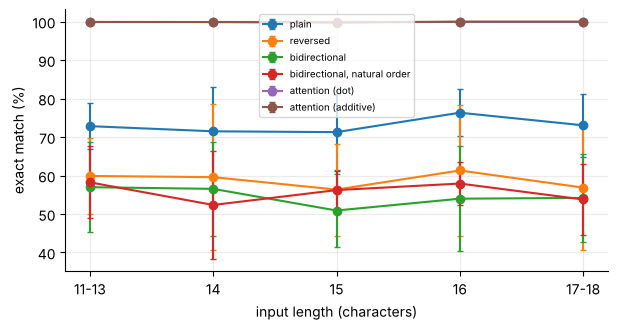

longest inputs (17-18 characters): plain 73.0 % → bidirectional 54.2 % → attention (dot) 100.0 %
[ ok ] attention (dot) is at least as accurate as the plain Encoder–Decoder on the longest inputs
[ ok ] with attention the overall exact match beats the same model without attention (mean over seeds)


In [56]:
groups = {n: pd.DataFrame([length_groups(r["by_len"]) for r in DATE[n]]) for n in names6}
len_tab = pd.DataFrame({n: g.mean() for n, g in groups.items()}).T
len_std = pd.DataFrame({n: g.std(ddof=1) for n, g in groups.items()}).T
display((len_tab * 100).round(1).rename_axis("exact match (%) by input length").rename(columns=lambda c: f"{c} chars"))
fig, ax = plt.subplots(figsize=(7, 3.4))
for n in names6:
    ax.errorbar(range(len(len_tab.columns)), 100 * len_tab.loc[n], yerr=100 * len_std.loc[n].fillna(0), marker="o", capsize=2, label=n)
ax.set_xticks(range(len(len_tab.columns))); ax.set_xticklabels(len_tab.columns); ax.set_xlabel("input length (characters)"); ax.set_ylabel("exact match (%)"); ax.legend(fontsize=7); plt.show()
RESULTS["date_by_length"] = (len_tab * 100).round(2).to_dict("index")
longest = len_tab.columns[-1]
print(f"longest inputs ({longest} characters): plain {100 * len_tab.loc['plain', longest]:.1f} % → bidirectional {100 * len_tab.loc['bidirectional', longest]:.1f} % → attention (dot) {100 * len_tab.loc['attention (dot)', longest]:.1f} %")
audit_trained("attention (dot) is at least as accurate as the plain Encoder–Decoder on the longest inputs", lambda: len_tab.loc["attention (dot)", longest] >= len_tab.loc["plain", longest])
audit_trained("with attention the overall exact match beats the same model without attention (mean over seeds)", lambda: np.mean([r["exact"] for r in DATE["attention (dot)"]]) > np.mean([r["exact"] for r in DATE["bidirectional"]]))

## 6.4 Looking inside: attention heat maps
We read the weights `α(t,i)` out of the trained dot-attention model. To make sure we read the *real* weights, the probe recomputes them from the layer's inputs (scores `q·kᵀ`, padding masked, softmax) and checks that `weights @ values` reproduces the layer's own context vectors. The source is shown in reading order (the model sees it reversed), the rows are the 10 output characters and `<eos>`, with the true previous characters as decoder input.

[ ok ] the recomputed attention weights reproduce the layer's context vectors   (max |difference| = 9.30e-06)
[ ok ] each decoder step's weights sum to 1 and padded input positions get weight 0


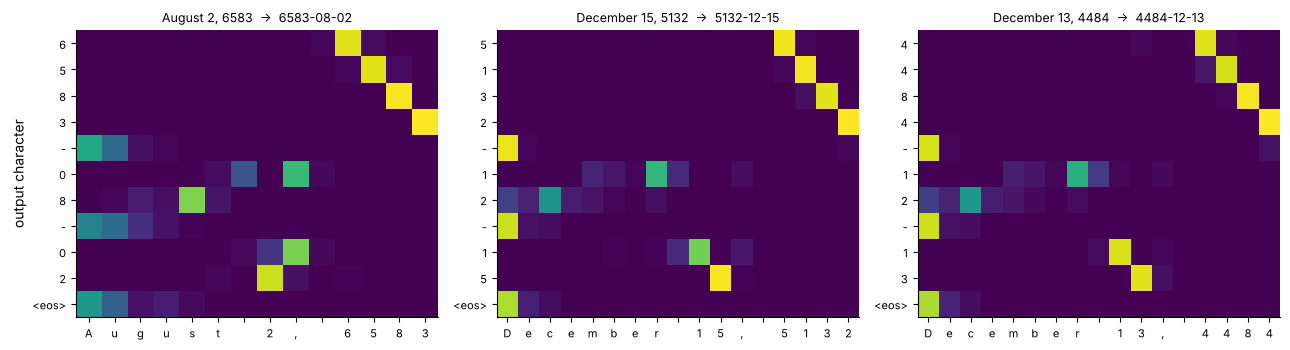

In [57]:
att_model = DATE_MODELS[("attention (dot)", SZ["date_seeds"][0])]
att_layer = next(l for l in att_model.layers if isinstance(l, L.Attention))
probe = keras.Model(att_model.inputs, [att_layer.input[0], att_layer.input[1], att_layer.output])


def attention_weights(X, di):
    q, val, ctx = (t.numpy() for t in probe([X, di], training=False))
    scores = np.einsum("btd,bsd->bts", q, val)
    scores = np.where((X != 0)[:, None, :], scores, -1e9)
    w = np.exp(scores - scores.max(-1, keepdims=True)); w /= w.sum(-1, keepdims=True)
    return w, np.einsum("bts,bsd->btd", w, val), ctx


Wt, ctx_manual, ctx_layer = attention_weights(D_TEST["X"][True][:200], D_TEST["di"][:200])
audit("the recomputed attention weights reproduce the layer's context vectors", np.allclose(ctx_manual, ctx_layer, atol=1e-4), f"max |difference| = {np.abs(ctx_manual - ctx_layer).max():.2e}")
audit("each decoder step's weights sum to 1 and padded input positions get weight 0", np.allclose(Wt.sum(-1), 1, atol=1e-5) and Wt[(D_TEST['X'][True][:200] == 0)[:, None, :].repeat(Wt.shape[1], 1)].max() < 1e-6)

idx = [0, 1, 2]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, i in zip(axes, idx):
    n_src = D_TEST["lens"][i]
    nat = Wt[i][:, :n_src][:, ::-1]                                               # back to reading order
    ax.imshow(nat, cmap="viridis", aspect="auto")
    ax.set_xticks(range(n_src)); ax.set_xticklabels(list(D_TEST["src"][i]), fontsize=8)
    ax.set_yticks(range(nat.shape[0])); ax.set_yticklabels(list(D_TEST["iso"][i]) + ["<eos>"], fontsize=8)
    ax.set_title(f"{D_TEST['src'][i]}  →  {D_TEST['iso'][i]}", fontsize=9); ax.grid(False)
axes[0].set_ylabel("output character"); plt.tight_layout(); plt.show()

**What is the alignment?** For a date we expect: the four year digits (output positions 0–3) look at the last four source characters; the month digits (5–6) look at the *month name* at the start; the day digits (8–9) look at the number in the middle – a reordering (day–month–year → year–month–day) with monotone steps inside each field. The table averages the attention mass over 200 test dates: rows = output field, columns = source field.

In [58]:
def field_mass(i, w):
    s = D_TEST["src"][i]; n = len(s); month = s.split()[0]; day = s.split()[1].strip(",")
    spans = {"month name": (0, len(month)), "day number": (len(month) + 1, len(month) + 1 + len(day)), "year": (n - 4, n)}
    nat = w[:, :n][:, ::-1]
    out_fields = {"year digits": range(0, 4), "month digits": range(5, 7), "day digits": range(8, 10)}
    return {(o, sname): float(nat[list(rows_)][:, a:b].sum(1).mean()) for o, rows_ in out_fields.items() for sname, (a, b) in spans.items()}


per_example = [field_mass(i, Wt[i]) for i in range(len(Wt))]
mass_tab = pd.DataFrame({sf: {of: float(np.mean([e[(of, sf)] for e in per_example])) for of in ("year digits", "month digits", "day digits")} for sf in ("month name", "day number", "year")})
display((100 * mass_tab).round(1).rename_axis("output field  \\  attention mass (%) on source field"))
RESULTS["attention_alignment"] = (100 * mass_tab).round(1).to_dict("index")
right = {"year digits": "year", "month digits": "month name", "day digits": "day number"}
audit_trained("each output field puts most of its attention on the matching source field (year→year, month→month name, day→day number)", lambda: all(mass_tab.loc[o].idxmax() == s for o, s in right.items()), lambda: ", ".join(f"{o}: {100 * mass_tab.loc[o, s]:.0f} %" for o, s in right.items()))

,month name,day number,year
output field \ attention mass (%) on source field,,,
year digits,0.1,0.2,99.5
month digits,63.9,1.2,0.5
day digits,0.5,81.0,0.5


[ ok ] each output field puts most of its attention on the matching source field (year→year, month→month name, day→day number)   (year digits: 100 %, month digits: 64 %, day digits: 81 %)


## 6.5 Visual attention (Show, Attend and Tell)
The same mechanism works for images. A **CNN** turns the picture into a grid of feature vectors (one per image region). An **RNN decoder with attention** writes the caption word by word; at each word it computes weights over the *regions* (not over source words) and builds the context vector from the region features. When it is about to write "frisbee", the weights concentrate on the cells that contain the frisbee.

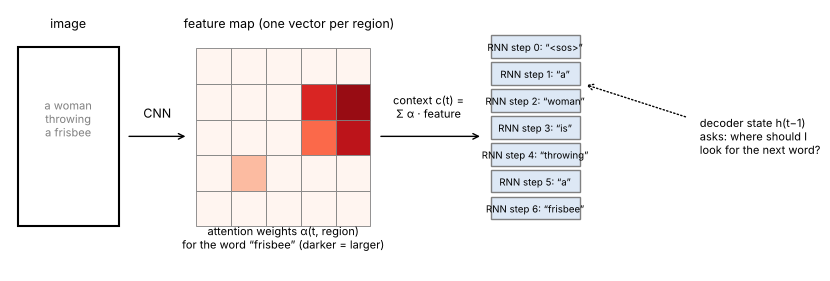

In [59]:
from matplotlib.patches import Rectangle, FancyArrowPatch
fig, ax = plt.subplots(figsize=(10, 3.4)); ax.set_xlim(0, 20); ax.set_ylim(0, 7); ax.axis("off")
ax.text(1.5, 6.5, "image", ha="center", fontsize=9); ax.add_patch(Rectangle((0.2, 1.2), 2.6, 4.8, fill=False, lw=1.5))
ax.text(1.5, 3.6, "a woman\nthrowing\na frisbee", ha="center", fontsize=8, color="gray")
ax.annotate("", xy=(4.6, 3.6), xytext=(3.0, 3.6), arrowprops=dict(arrowstyle="->")); ax.text(3.8, 4.1, "CNN", ha="center", fontsize=9)
ax.text(7.2, 6.5, "feature map (one vector per region)", ha="center", fontsize=9)
grid = np.zeros((5, 5)); grid[1:3, 3:5] = [[0.7, 0.9], [0.5, 0.8]]; grid[3, 1] = 0.25
for i in range(5):
    for j in range(5):
        ax.add_patch(Rectangle((4.8 + j * 0.9, 1.2 + (4 - i) * 0.95), 0.9, 0.95, fc=plt.cm.Reds(grid[i, j]), ec="gray", lw=0.6))
ax.text(7.05, 0.6, "attention weights α(t, region)\nfor the word “frisbee” (darker = larger)", ha="center", fontsize=8)
ax.annotate("", xy=(12.2, 3.6), xytext=(9.5, 3.6), arrowprops=dict(arrowstyle="->")); ax.text(10.8, 4.1, "context c(t) =\nΣ α · feature", ha="center", fontsize=8)
for k, w_ in enumerate(["<sos>", "a", "woman", "is", "throwing", "a", "frisbee"]):
    ax.add_patch(Rectangle((12.4 + 1.0 * (k % 7) * 0.0, 5.7 - k * 0.72), 2.3, 0.6, fc="#dde8f5", ec="gray")); ax.text(13.55, 5.98 - k * 0.72, f"RNN step {k}: “{w_}”", ha="center", va="center", fontsize=7)
ax.text(17.8, 3.6, "decoder state h(t−1)\nasks: where should I\nlook for the next word?", fontsize=8, va="center")
ax.annotate("", xy=(14.8, 5.0), xytext=(17.5, 4.1), arrowprops=dict(arrowstyle="->", ls=":"))
plt.show()

## 6.6 Explainability – what an attention map can and cannot tell you
* **The wolf in the snow.** A classifier that separated dogs from wolves with high accuracy turned out to look mostly at the **snow in the background** (wolf photos had snow, dog photos did not). The accuracy was real but for the wrong reason, and it would fail on a dog in snow. Ribeiro et al. (*"Why should I trust you?"*, 2016, the LIME method) explain a single prediction by fitting a simple local model around it and highlighting which parts of the input drove it – which is how this error is found.
* **Why it matters.** Many domains need reasons, sometimes by law: a rejected loan application, a medical decision, a hiring decision. A model nobody can explain is hard to audit, debug, or trust.
* **What attention shows.** It shows *where the model looked* when it produced an output, which is useful for debugging (the heat maps above show exactly the field-to-field alignment we hoped for). It does **not** prove that those positions *caused* the output: the weights are one step of a network with many other paths, and models can produce the same output with different attention. Treat an attention map as a hint to investigate, not as an explanation.

## 6.7 BLEU by hand
**BLEU** compares a candidate translation with one or more human references by counting **n-grams of the candidate that also occur in a reference**. Two corrections: (1) a candidate n-gram is credited at most as often as it appears in a *single* reference (*clipping*), so "the the the the" cannot score well; (2) a **brevity penalty** punishes candidates shorter than the references. BLEU-n = brevity penalty × geometric mean of the modified precisions p₁ … pₙ.
Toy case. References: `the cat is on the mat` / `there is a cat on the mat`.
* **C1** `the cat sat on the mat`   * **C2** `the the the the the the`
p₁(C1): the (2, clipped to the max of 2 in one reference) + cat 1 + sat 0 + on 1 + mat 1 = 5/6. p₂(C1): bigrams the-cat ✓, cat-sat ✗, sat-on ✗, on-the ✓, the-mat ✓ = 3/5. BLEU-2(C1) = √(5/6 × 3/5) = √0.5 ≈ 0.707. C2: p₁ = 2/6 (the, clipped to 2) = 1/3 and p₂ = 0/5 → BLEU-2 = 0.

In [60]:
def ngrams(tokens, n):
    return Counter(tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1))


def modified_precision(cand, refs, n):
    c = ngrams(cand, n)
    if not c:
        return 0.0
    clipped = sum(min(cnt, max(ngrams(r, n)[g] for r in refs)) for g, cnt in c.items())
    return clipped / sum(c.values())


def bleu(cand, refs, max_n):
    ps = [modified_precision(cand, refs, n) for n in range(1, max_n + 1)]
    ref_len = min((abs(len(r) - len(cand)), len(r)) for r in refs)[1]
    bp = 1.0 if len(cand) > ref_len else math.exp(1 - ref_len / len(cand))
    return bp * (math.exp(sum(math.log(p) for p in ps) / max_n) if all(p > 0 for p in ps) else 0.0), ps, bp


refs = [s.split() for s in ("the cat is on the mat", "there is a cat on the mat")]
cands = {"C1": "the cat sat on the mat".split(), "C2": "the the the the the the".split()}
out = []
for nme, c in cands.items():
    b1, ps1, bp = bleu(c, refs, 1); b2, ps2, _ = bleu(c, refs, 2)
    out.append(dict(candidate=nme, text=" ".join(c), p1=round(ps2[0], 4), p2=round(ps2[1], 4), brevity_penalty=bp, BLEU1=round(b1, 4), BLEU2=round(b2, 4)))
display(pd.DataFrame(out).set_index("candidate"))
audit("by hand: C1 has p1 = 5/6, p2 = 3/5 and BLEU-2 = √0.5; C2 has p1 = 1/3, p2 = 0 and BLEU-2 = 0", np.isclose(out[0]["p1"], 5 / 6, atol=1e-4) and np.isclose(out[0]["p2"], 3 / 5, atol=1e-4) and np.isclose(out[0]["BLEU2"], math.sqrt(0.5), atol=1e-4) and np.isclose(out[1]["p1"], 1 / 3, atol=1e-4) and out[1]["BLEU2"] == 0)
try:
    from nltk.translate.bleu_score import sentence_bleu
    lib = [sentence_bleu(refs, c, weights=(1, 0)) for c in cands.values()], [sentence_bleu(refs, c, weights=(0.5, 0.5)) for c in cands.values()]
    print("nltk sentence_bleu → BLEU-1:", np.round(lib[0], 4), " BLEU-2:", np.round(lib[1], 4))
    audit("my BLEU-1 and BLEU-2 agree with nltk on both candidates", np.allclose(lib[0], [out[0]["BLEU1"], out[1]["BLEU1"]], atol=1e-3) and np.allclose(lib[1], [out[0]["BLEU2"], out[1]["BLEU2"]], atol=1e-3))
except Exception as e:
    print("nltk is not installed here, so there is no library cross-check (the hand calculation above is the check).", type(e).__name__)

,text,p1,p2,brevity_penalty,BLEU1,BLEU2
candidate,,,,,,
C1,the cat sat on the mat,0.8333,0.6,1.0,0.8333,0.7071
C2,the the the the the the,0.3333,0.0,1.0,0.3333,0.0000


[ ok ] by hand: C1 has p1 = 5/6, p2 = 3/5 and BLEU-2 = √0.5; C2 has p1 = 1/3, p2 = 0 and BLEU-2 = 0


nltk sentence_bleu → BLEU-1: [0.8333 0.3333]  BLEU-2: [0.7071 0.    ]
[ ok ] my BLEU-1 and BLEU-2 agree with nltk on both candidates


---
# Phase 7 · The Transformer – attention without recurrence
**"Attention Is All You Need"** (Vaswani et al., 2017): a state-of-the-art translation model with **no recurrent and no convolutional layers** – only embeddings, dense layers, normalisation and attention. It is much **faster to train** (all positions are processed in parallel) and easier to scale.
## 7.1 The architecture, from memory
```
 source ids [batch, src_len]                              target ids, shifted right (<sos> first) [batch, tgt_len]
    │ Embedding + positional encoding                        │ Embedding + positional encoding
    ▼                                                         ▼
 ┌── ENCODER, N times ───────────────┐                    ┌── DECODER, N times ───────────────────────────┐
 │ multi-head SELF-attention         │                    │ MASKED multi-head self-attention (causal)     │
 │ Add & Norm   (skip + LayerNorm)   │                    │ Add & Norm                                    │
 │ feed-forward (Dense relu, Dense)  │ ─ encoder output ─▶│ multi-head ENCODER–DECODER attention          │
 │ Add & Norm                        │   (to every        │   queries: decoder · keys, values: encoder    │
 └───────────────────────────────────┘    decoder level)  │ Add & Norm → feed-forward → Add & Norm        │
                                                          └───────────────────────────────────────────────┘
                                                                      │ Dense + softmax → [batch, tgt_len, vocabulary]
```
* **Training:** the decoder gets the target shifted right and the encoder output at each level. **At inference:** call the model repeatedly, appending each generated token, until `<eos>`.
* **Counting the components** (N = 6 in the paper): two embedding layers; **5 × N** skip connections, each followed by Layer Normalization (encoder: 2 per level, decoder: 3 per level); **2 × N** feed-forward modules (Dense with ReLU, then Dense without activation); one softmax output layer. Dense layers act on each position separately (they are like 1-D convolutions with kernel size 1), so **all interaction between words comes from attention**.
* **Three kinds of attention:** (1) *self-attention* in the encoder – every word attends to every word of the same sentence ("Queen" in "They welcomed the Queen of the United Kingdom" attends strongly to "United" and "Kingdom"); (2) *masked self-attention* in the decoder – each position sees only earlier positions; (3) *encoder–decoder attention* – queries from the decoder, keys and values from the encoder output.

In [61]:
SB.phase = "Phase 7"

## 7.2 Positional encoding
Attention ignores word order – `softmax(QKᵀ)V` gives the same result if the keys are shuffled – and every other layer treats positions independently. So order must be put into the data: the *p*-th positional vector is **added** to the *p*-th word embedding.
`P(p, 2i) = sin(p / 10000^(2i/d))`, `P(p, 2i+1) = cos(p / 10000^(2i/d))`. The `PositionalEncoding` layer precomputes a `[1, max_steps, max_dims]` matrix in its constructor (`max_dims` made even) and in `call()` crops it to the input's shape and adds it by broadcasting.

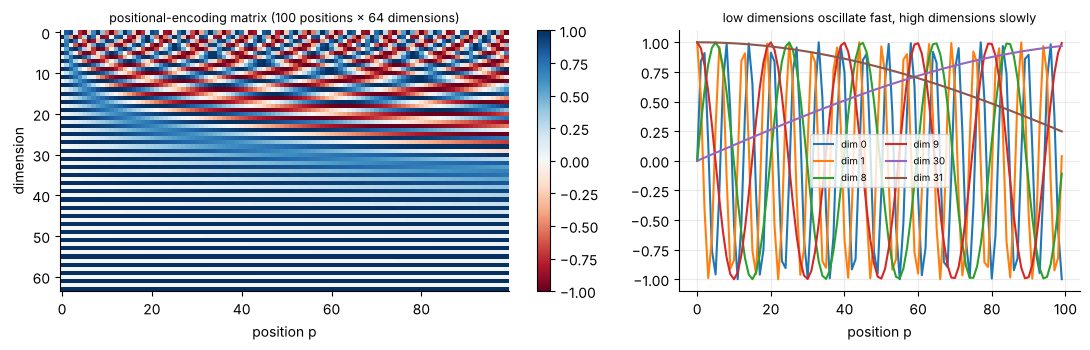

[ ok ] PositionalEncoding equals sin / cos of p / 10000^(2i/d) (computed one by one in plain Python)
[ ok ] every position gets a unique vector (smallest distance between two different positions > 0.05)
[ ok ] an odd number of dimensions works (the matrix is built with 6 and cropped to 5) and the layer broadcasts over the batch
[ ok ] positions beyond the longest training sentence are computable (the encoding is a formula, not a learned table)


In [62]:
class PositionalEncoding(L.Layer):
    def __init__(self, max_steps, max_dims, **kwargs):
        super().__init__(**kwargs)
        self.supports_masking = True
        if max_dims % 2 == 1:
            max_dims += 1                                                            # max_dims must be even
        p, i = np.meshgrid(np.arange(max_steps), np.arange(max_dims // 2))
        pe = np.empty((1, max_steps, max_dims))
        pe[0, :, ::2] = np.sin(p / 10000 ** (2 * i / max_dims)).T
        pe[0, :, 1::2] = np.cos(p / 10000 ** (2 * i / max_dims)).T
        self.positional_embedding = tf.constant(pe.astype("float32"))

    def call(self, inputs):
        shape = tf.shape(inputs)
        return inputs + self.positional_embedding[:, :shape[-2], :shape[-1]]


pe_layer = PositionalEncoding(100, 64)
PE = pe_layer(tf.zeros([1, 100, 64])).numpy()[0]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw=dict(width_ratios=[1.4, 1]))
im = ax[0].imshow(PE.T, cmap="RdBu", aspect="auto"); ax[0].set_xlabel("position p"); ax[0].set_ylabel("dimension"); ax[0].set_title("positional-encoding matrix (100 positions × 64 dimensions)", fontsize=9); ax[0].grid(False); plt.colorbar(im, ax=ax[0])
for d_ in (0, 1, 8, 9, 30, 31):
    ax[1].plot(PE[:, d_], label=f"dim {d_}")
ax[1].set_xlabel("position p"); ax[1].legend(fontsize=7, ncol=2); ax[1].set_title("low dimensions oscillate fast, high dimensions slowly", fontsize=9)
plt.tight_layout(); plt.show()
manual = np.array([[math.sin(p / 10000 ** (2 * (d // 2) / 64)) if d % 2 == 0 else math.cos(p / 10000 ** (2 * (d // 2) / 64)) for d in range(64)] for p in range(100)])
audit("PositionalEncoding equals sin / cos of p / 10000^(2i/d) (computed one by one in plain Python)", np.allclose(PE, manual, atol=1e-5))
audit("every position gets a unique vector (smallest distance between two different positions > 0.05)", min(np.linalg.norm(PE[a] - PE[b]) for a in range(100) for b in range(a)) > 0.05)
odd = PositionalEncoding(30, 5)(tf.zeros([2, 12, 5]))
audit("an odd number of dimensions works (the matrix is built with 6 and cropped to 5) and the layer broadcasts over the batch", tuple(odd.shape) == (2, 12, 5) and np.allclose(odd.numpy()[0], odd.numpy()[1]))
audit("positions beyond the longest training sentence are computable (the encoding is a formula, not a learned table)", PositionalEncoding(5000, 64)(tf.zeros([1, 4000, 64])).shape == (1, 4000, 64))

**Reading the plot.** The *i*-th sine/cosine pair has wavelength `2π · 10000^(2i/d)`: the first dimensions have a short period (they tell nearby positions apart, like the fast hand of a clock), the last ones a huge period (they tell far-apart positions apart, like the hour hand). Together they give each position a unique code. **Fixed vs. learned:** the original paper found learned position embeddings perform the same as these fixed ones; the fixed ones have the advantage that they extend to sentences longer than any seen in training.
**Why both sine and cosine?** With sine alone two positions can share a value at a given frequency: for `ω = π/60`, `sin(25ω) = sin(35ω)` because 25 + 35 = 60. The cosine of the same angle breaks the tie:

In [63]:
w_ = math.pi / 60
print(f"sin(25ω) = {math.sin(25 * w_):.4f}, sin(35ω) = {math.sin(35 * w_):.4f}   (equal)   ·   cos(25ω) = {math.cos(25 * w_):+.4f}, cos(35ω) = {math.cos(35 * w_):+.4f}   (different)")
audit("sine alone cannot separate positions 25 and 35 at ω = π/60, cosine can", np.isclose(math.sin(25 * w_), math.sin(35 * w_)) and not np.isclose(math.cos(25 * w_), math.cos(35 * w_)))

sin(25ω) = 0.9659, sin(35ω) = 0.9659   (equal)   ·   cos(25ω) = +0.2588, cos(35ω) = -0.2588   (different)
[ ok ] sine alone cannot separate positions 25 and 35 at ω = π/60, cosine can


**Proof that a shift is a linear map (relative positions are learnable).** For one frequency ω, with `a = ωp` and `b = ωk`, the angle-addition identities `sin(a+b) = sin a cos b + cos a sin b` and `cos(a+b) = cos a cos b − sin a sin b` give
```
  [ sin(ω(p+k)) ]   [  cos ωk   sin ωk ] [ sin ωp ]
  [ cos(ω(p+k)) ] = [ −sin ωk   cos ωk ] [ cos ωp ]          ← a rotation by the angle ωk
```
The 2×2 matrix depends only on the offset `k` and the frequency – **not on `p`**. Stacking one such block per frequency gives a single `d×d` matrix `T_k` with `P(p+k) = T_k · P(p)` for every position `p`. A layer can therefore learn "look 3 positions back" as a linear operation. Numerical check:

In [64]:
def shift_matrix(k, d=64):
    T = np.zeros((d, d))
    for i in range(d // 2):
        w = 1 / 10000 ** (2 * i / d)
        T[2 * i:2 * i + 2, 2 * i:2 * i + 2] = [[math.cos(w * k), math.sin(w * k)], [-math.sin(w * k), math.cos(w * k)]]
    return T


PE64 = PositionalEncoding(200, 64)(tf.zeros([1, 200, 64])).numpy()[0].astype("float64")
for k in (1, 3, 17):
    err = np.abs(PE64[k:] - PE64[:-k] @ shift_matrix(k).T).max()
    print(f"offset k = {k:2d}: max |P(p+k) − T_k·P(p)| over all positions = {err:.2e}")
audit("P(p + k) = T_k · P(p) for every p and k = 1, 3, 17 (rotation matrices from the angle-addition identities)", all(np.abs(PE64[k:] - PE64[:-k] @ shift_matrix(k).T).max() < 1e-4 for k in (1, 3, 17)))
T_fit, *_ = np.linalg.lstsq(PE64[:-5], PE64[5:], rcond=None)
audit("a least-squares fit of a linear map from P(p) to P(p+5) over all positions reproduces the encoding with no error", np.abs(PE64[:-5] @ T_fit - PE64[5:]).max() < 1e-3)

offset k =  1: max |P(p+k) − T_k·P(p)| over all positions = 6.26e-08
offset k =  3: max |P(p+k) − T_k·P(p)| over all positions = 6.43e-08
offset k = 17: max |P(p+k) − T_k·P(p)| over all positions = 6.39e-08
[ ok ] P(p + k) = T_k · P(p) for every p and k = 1, 3, 17 (rotation matrices from the angle-addition identities)
[ ok ] a least-squares fit of a linear map from P(p) to P(p+5) over all positions reproduces the encoding with no error


## 7.3 Scaled dot-product attention
A **differentiable dictionary lookup.** "They played chess": the decoder, about to write the verb, makes a *query* ("verb?"). It is compared with the *keys* of the encoder words by similarity; a softmax turns the similarities into weights that sum to 1; the output is the weighted sum of the *values*. A normal dictionary returns the value of the one matching key; here every value contributes in proportion to its similarity.
`Attention(Q, K, V) = softmax(Q Kᵀ / √d_keys) · V` – shapes `Q: [n_queries, d_keys]`, `K: [n_keys, d_keys]`, `V: [n_keys, d_values]`, `QKᵀ: [n_queries, n_keys]`, output `[n_queries, d_values]`.
* **Scaling.** The dot product of two random `d`-dimensional vectors has standard deviation `√d`. Without the `1/√d_keys`, large `d` pushes the softmax into saturation (one weight ≈ 1, the rest ≈ 0), where its gradient is almost zero.
* **Masking.** Add a very large negative number (−10⁹) to the scores of forbidden positions before the softmax; their weight becomes 0.

In [65]:
def scaled_dot_product_attention(Q, K, V, mask=None, scale=True):
    """Q [..., nq, dk] · K [..., nk, dk] · V [..., nk, dv] → ([..., nq, dv], weights [..., nq, nk]); mask: 1 = keep, broadcastable to the scores"""
    scores = tf.matmul(Q, K, transpose_b=True)
    if scale:
        scores = scores / tf.sqrt(tf.cast(tf.shape(K)[-1], scores.dtype))
    if mask is not None:
        scores += (1.0 - tf.cast(mask, scores.dtype)) * -1e9
    w = tf.nn.softmax(scores, axis=-1)
    return tf.matmul(w, V), w


print("tf.matmul on 4-D tensors multiplies the last two dimensions:", tf.matmul(tf.zeros([2, 3, 4, 5]), tf.zeros([2, 3, 5, 6])).shape)
r7 = np.random.default_rng(0)
Q_, K_, V_ = (tf.constant(r7.normal(size=s).astype("float32")) for s in ((2, 5, 16), (2, 7, 16), (2, 7, 9)))
out_mine, w_mine = scaled_dot_product_attention(Q_, K_, V_)
audit("shapes: Q [2,5,16], K [2,7,16], V [2,7,9] → output [2,5,9], weights [2,5,7]", out_mine.shape == (2, 5, 9) and w_mine.shape == (2, 5, 7))
audit("the weights of every query sum to 1", np.allclose(w_mine.numpy().sum(-1), 1, atol=1e-5))
dk = 16
keras_out = L.Attention(use_scale=False)([Q_ / math.sqrt(dk), V_, K_])                       # Keras order is [query, value, key]; use_scale=False means no 1/√d is applied
audit("mine = keras.layers.Attention(use_scale=False) once the queries are divided by √d_keys", np.allclose(out_mine.numpy(), keras_out.numpy(), atol=1e-5))
audit("without scaling mine = keras.layers.Attention(use_scale=False) exactly", np.allclose(scaled_dot_product_attention(Q_, K_, V_, scale=False)[0].numpy(), L.Attention(use_scale=False)([Q_, V_, K_]).numpy(), atol=1e-5))
causal = np.tril(np.ones((5, 5), "float32"))[None]
out_c, w_c = scaled_dot_product_attention(Q_[:, :, :], Q_, Q_[:, :, :9], mask=causal)
keras_c = L.Attention(use_scale=False)([Q_ / math.sqrt(dk), Q_[:, :, :9], Q_], use_causal_mask=True)
audit("with a lower-triangular mask mine equals keras.layers.Attention(...)(use_causal_mask=True), and no weight falls on future positions", np.allclose(out_c.numpy(), keras_c.numpy(), atol=1e-5) and np.triu(w_c.numpy()[0], 1).max() < 1e-6)
pad_mask = np.array([[1, 1, 1, 1, 1, 0, 0], [1, 1, 1, 0, 0, 0, 0]], "float32")[:, None, :]
out_p, w_p = scaled_dot_product_attention(Q_, K_, V_, mask=pad_mask)
keras_p = L.Attention(use_scale=False)([Q_ / math.sqrt(dk), V_, K_], mask=[np.ones((2, 5), bool), pad_mask[:, 0].astype(bool)])
audit("a padding mask on the keys gives weight 0 to padded positions and matches Keras' value mask", w_p.numpy()[1, :, 3:].max() < 1e-6 and np.allclose(out_p.numpy(), keras_p.numpy(), atol=1e-5))
print("note: use_scale=True in Keras learns one scale parameter instead of using the fixed 1/√d_keys; `use_causal_mask=True` (in the call; older versions: `causal=True` in the constructor) masks future positions.")

tf.matmul on 4-D tensors multiplies the last two dimensions: (2, 3, 4, 6)
[ ok ] shapes: Q [2,5,16], K [2,7,16], V [2,7,9] → output [2,5,9], weights [2,5,7]
[ ok ] the weights of every query sum to 1
[ ok ] mine = keras.layers.Attention(use_scale=False) once the queries are divided by √d_keys
[ ok ] without scaling mine = keras.layers.Attention(use_scale=False) exactly


[ ok ] with a lower-triangular mask mine equals keras.layers.Attention(...)(use_causal_mask=True), and no weight falls on future positions
[ ok ] a padding mask on the keys gives weight 0 to padded positions and matches Keras' value mask
note: use_scale=True in Keras learns one scale parameter instead of using the fixed 1/√d_keys; `use_causal_mask=True` (in the call; older versions: `causal=True` in the constructor) masks future positions.


**Experiment: why scale?** Random queries and keys (20 keys, standard normal entries); the average of the *largest* attention weight per query.

In [66]:
sat = []
for d in (8, 64, 512):
    Qr, Kr = (tf.constant(np.random.default_rng(d + j).normal(size=(500, n, d)).astype("float32")) for j, n in enumerate((10, 20)))
    Vr = tf.zeros([500, 20, 1])
    sat.append(dict(d_keys=d, **{"max weight, no scaling": float(tf.reduce_max(scaled_dot_product_attention(Qr, Kr, Vr, scale=False)[1], -1).numpy().mean()),
                                 "max weight, with 1/√d": float(tf.reduce_max(scaled_dot_product_attention(Qr, Kr, Vr)[1], -1).numpy().mean())}))
sat_tab = pd.DataFrame(sat).set_index("d_keys"); display(sat_tab.round(3))
RESULTS["attention_saturation"] = sat_tab.round(4).to_dict("index")
audit("without scaling the softmax saturates as d grows (largest weight rises with d and exceeds 0.9 at d = 512)", sat_tab.iloc[:, 0].is_monotonic_increasing and sat_tab.iloc[-1, 0] > 0.9)
audit("with the 1/√d scaling the largest weight stays about the same for d = 8, 64, 512 (spread < 0.05)", sat_tab.iloc[:, 1].max() - sat_tab.iloc[:, 1].min() < 0.05)

,"max weight, no scaling","max weight, with 1/√d"
d_keys,,
8,0.539,0.212
64,0.834,0.216
512,0.944,0.219


[ ok ] without scaling the softmax saturates as d grows (largest weight rises with d and exceeds 0.9 at d = 512)
[ ok ] with the 1/√d scaling the largest weight stays about the same for d = 8, 64, 512 (spread < 0.05)


## 7.4 Multi-head attention
One attention layer can look up only one kind of relationship. A word representation encodes many things at once (it is a verb, past tense, third person, at position 5, …). **Multi-head attention** runs `h` attention layers in parallel; each first applies its own linear transformation (a time-distributed `Dense` without activation) to Q, K and V, so each head can extract a different subspace and "look up" a different property. The `h` outputs are concatenated and passed through a final linear layer.
Implementation: one `Dense(d_model)` each for Q, K, V (all heads at once), reshaped to `[batch, heads, steps, d_model / heads]`; scaled dot-product attention per head; heads merged; output `Dense(d_model)`.

In [67]:
class MultiHeadAttention(L.Layer):
    def __init__(self, num_heads, d_model, **kwargs):
        super().__init__(**kwargs)
        assert d_model % num_heads == 0
        self.h, self.d, self.dk = num_heads, d_model, d_model // num_heads
        self.wq, self.wk, self.wv, self.wo = (L.Dense(d_model, name=n) for n in ("wq", "wk", "wv", "wo"))

    def _split(self, x):
        b, t = tf.shape(x)[0], tf.shape(x)[1]
        return tf.transpose(tf.reshape(x, [b, t, self.h, self.dk]), [0, 2, 1, 3])             # [batch, heads, steps, dk]

    def call(self, inputs, return_weights=False):
        q_in, kv_in, mask = inputs                                                         # mask [batch, nq or 1, nk]: 1 = may attend
        Q, K, V = self._split(self.wq(q_in)), self._split(self.wk(kv_in)), self._split(self.wv(kv_in))
        out, w = scaled_dot_product_attention(Q, K, V, mask=None if mask is None else mask[:, None, :, :])
        b, t = tf.shape(q_in)[0], tf.shape(q_in)[1]
        out = tf.reshape(tf.transpose(out, [0, 2, 1, 3]), [b, t, self.d])
        out = self.wo(out)
        return (out, w) if return_weights else out


d_m, heads_ = 32, 4
mine_mha = MultiHeadAttention(heads_, d_m)
xq, xkv = tf.constant(r7.normal(size=(3, 5, d_m)).astype("float32")), tf.constant(r7.normal(size=(3, 8, d_m)).astype("float32"))
mk = (r7.random((3, 5, 8)) > 0.3).astype("float32"); mk[:, :, 0] = 1
out_my = mine_mha([xq, xkv, mk])
keras_mha = L.MultiHeadAttention(num_heads=heads_, key_dim=d_m // heads_)
keras_mha(xq, xkv, attention_mask=mk.astype(bool))
dk_ = d_m // heads_
keras_mha.set_weights([mine_mha.wq.kernel.numpy().reshape(d_m, heads_, dk_), mine_mha.wq.bias.numpy().reshape(heads_, dk_),
                       mine_mha.wk.kernel.numpy().reshape(d_m, heads_, dk_), mine_mha.wk.bias.numpy().reshape(heads_, dk_),
                       mine_mha.wv.kernel.numpy().reshape(d_m, heads_, dk_), mine_mha.wv.bias.numpy().reshape(heads_, dk_),
                       mine_mha.wo.kernel.numpy().reshape(heads_, dk_, d_m), mine_mha.wo.bias.numpy()])
out_keras = keras_mha(xq, xkv, attention_mask=mk.astype(bool))
print("output shapes — mine:", tuple(out_my.shape), " Keras:", tuple(out_keras.shape), "· parameters — mine:", mine_mha.count_params(), " Keras:", keras_mha.count_params())
audit("my MultiHeadAttention and keras.layers.MultiHeadAttention have identical output shape and parameter count", out_my.shape == out_keras.shape and mine_mha.count_params() == keras_mha.count_params())
audit("with the weights copied across (and the same mask) the two layers give the same output", np.allclose(out_my.numpy(), out_keras.numpy(), atol=1e-4), f"max |difference| = {np.abs(out_my.numpy() - out_keras.numpy()).max():.2e}")
_, w_heads = mine_mha([xq, xkv, mk], return_weights=True)
audit("per head the weights form a distribution over the keys (shape [3, 4, 5, 8], rows sum to 1, masked keys get 0)", w_heads.shape == (3, 4, 5, 8) and np.allclose(w_heads.numpy().sum(-1), 1, atol=1e-5) and w_heads.numpy()[np.broadcast_to(mk[:, None] == 0, w_heads.shape)].max() < 1e-6)
dense_t = L.Dense(7); conv_t = L.Conv1D(7, 1)
xx = tf.constant(r7.normal(size=(2, 6, 5)).astype("float32")); dense_t(xx); conv_t(xx); conv_t.set_weights([dense_t.kernel.numpy()[None], dense_t.bias.numpy()])
audit("footnote: a Dense layer applied to every position equals a 1-D convolution with kernel size 1 (same weights, same output)", np.allclose(dense_t(xx).numpy(), conv_t(xx).numpy(), atol=1e-5))

output shapes — mine: (3, 5, 32)  Keras: (3, 5, 32) · parameters — mine: 4224  Keras: 4224
[ ok ] my MultiHeadAttention and keras.layers.MultiHeadAttention have identical output shape and parameter count
[ ok ] with the weights copied across (and the same mask) the two layers give the same output   (max |difference| = 2.38e-07)
[ ok ] per head the weights form a distribution over the keys (shape [3, 4, 5, 8], rows sum to 1, masked keys get 0)


[ ok ] footnote: a Dense layer applied to every position equals a 1-D convolution with kernel size 1 (same weights, same output)


## 7.5 A small Transformer for the date task
Layout exactly as in 7.1: embeddings (×√d) + positional encoding → `N` × [self-attention → Add & Norm → feed-forward → Add & Norm] → `N` × [**causal** self-attention → Add & Norm → encoder–decoder attention → Add & Norm → feed-forward → Add & Norm] → softmax. The decoder's self-attention mask is *causal × padding*; the encoder–decoder attention uses the *source* padding mask. Dropout 0.1. Optimiser: Adam (β₂ = 0.98) with the paper's warm-up schedule `lr = d^-0.5 · min(step^-0.5, step · warmup^-1.5)`.
Sizes: `N = tr_layers`, `d_model = tr_dim`, `tr_heads` heads, feed-forward width `4 × d_model` (see the `SZ` table). The brief suggests d_model = 128; on this CPU run the value in `SZ` was used.

In [68]:
class PadMask(L.Layer):
    def call(self, ids):
        return tf.cast(ids != 0, tf.float32)[:, None, :]                                    # [batch, 1, steps]


class CausalMask(L.Layer):
    def call(self, ids):
        t = tf.shape(ids)[1]
        return tf.linalg.band_part(tf.ones((t, t)), -1, 0)[None] * tf.cast(ids != 0, tf.float32)[:, None, :]      # [batch, steps, steps]


class ScaleBy(L.Layer):
    def __init__(self, factor, **kw):
        super().__init__(**kw); self.factor = factor

    def call(self, x):
        return x * self.factor


def ffn(x, d_model, d_ff, drop):
    return L.Dropout(drop)(L.Dense(d_model)(L.Dense(d_ff, activation="relu")(x)))


class WarmupSchedule(keras.optimizers.schedules.LearningRateSchedule):
    def __init__(self, d_model, warmup=400):
        super().__init__(); self.d_model, self.warmup = d_model, warmup

    def __call__(self, step):
        step = tf.cast(step, tf.float32) + 1.0
        return tf.math.rsqrt(float(self.d_model)) * tf.minimum(tf.math.rsqrt(step), step * self.warmup ** -1.5)

    def get_config(self):
        return dict(d_model=self.d_model, warmup=self.warmup)


def build_transformer(n_layers=SZ["tr_layers"], d_model=SZ["tr_dim"], heads=SZ["tr_heads"], drop=0.1, max_steps=64, warmup=400):
    src = keras.Input((None,), dtype="int32", name="source"); tgt = keras.Input((None,), dtype="int32", name="decoder_input")
    src_mask, tgt_mask = PadMask()(src), CausalMask()(tgt)
    x = L.Dropout(drop)(PositionalEncoding(max_steps, d_model)(ScaleBy(math.sqrt(d_model))(L.Embedding(len(SI) + 1, d_model)(src))))
    for i in range(n_layers):                                                                # ---- encoder
        a = L.Dropout(drop)(MultiHeadAttention(heads, d_model, name=f"enc_self_{i}")([x, x, src_mask]))
        x = L.LayerNormalization(name=f"enc_norm_a{i}")(L.Add()([x, a]))
        x = L.LayerNormalization(name=f"enc_norm_f{i}")(L.Add()([x, ffn(x, d_model, 4 * d_model, drop)]))
    y = L.Dropout(drop)(PositionalEncoding(max_steps, d_model)(ScaleBy(math.sqrt(d_model))(L.Embedding(N_TGT, d_model)(tgt))))
    for i in range(n_layers):                                                                # ---- decoder
        a = L.Dropout(drop)(MultiHeadAttention(heads, d_model, name=f"dec_self_{i}")([y, y, tgt_mask]))
        y = L.LayerNormalization(name=f"dec_norm_a{i}")(L.Add()([y, a]))
        a = L.Dropout(drop)(MultiHeadAttention(heads, d_model, name=f"dec_cross_{i}")([y, x, src_mask]))
        y = L.LayerNormalization(name=f"dec_norm_c{i}")(L.Add()([y, a]))
        y = L.LayerNormalization(name=f"dec_norm_f{i}")(L.Add()([y, ffn(y, d_model, 4 * d_model, drop)]))
    m = keras.Model([src, tgt], L.Dense(N_TGT, activation="softmax", name="softmax_out")(y))
    m.compile(loss="sparse_categorical_crossentropy", optimizer=keras.optimizers.Adam(WarmupSchedule(d_model, warmup), beta_1=0.9, beta_2=0.98, epsilon=1e-9))
    return m


tr_demo = build_transformer()
n_ = SZ["tr_layers"]
count = lambda cls: sum(isinstance(l, cls) for l in tr_demo.layers)
comp = pd.DataFrame([("embedding layers", count(L.Embedding), 2), ("skip connections (Add)", count(L.Add), 5 * n_), ("Layer Normalization layers", count(L.LayerNormalization), 5 * n_),
                     ("attention modules (N enc. self + N dec. self + N enc–dec)", count(MultiHeadAttention), 3 * n_), ("feed-forward modules (Dense relu → Dense)", sum(1 for l in tr_demo.layers if isinstance(l, L.Dense) and l.activation.__name__ == "relu"), 2 * n_),
                     ("softmax output layers", sum(1 for l in tr_demo.layers if isinstance(l, L.Dense) and l.activation.__name__ == "softmax"), 1)], columns=["component", "found in the model", "expected from the paper's counting"])
display(comp)
audit("the component counts match the paper's counting (2 embeddings, 5N skip connections + LayerNorms, 3N attention modules, 2N feed-forward modules)", (comp.iloc[:, 1] == comp.iloc[:, 2]).all())
print(f"{tr_demo.count_params():,} parameters (N = {n_}, d_model = {SZ['tr_dim']}, {SZ['tr_heads']} heads)")

,component,found in the model,expected from the paper's counting
0,embedding layers,2,2
1,skip connections (Add),10,10
2,Layer Normalization layers,10,10
3,attention modules (N enc. self + N dec. self +...,6,6
4,feed-forward modules (Dense relu → Dense),4,4
5,softmax output layers,1,1


[ ok ] the component counts match the paper's counting (2 embeddings, 5N skip connections + LayerNorms, 3N attention modules, 2N feed-forward modules)
237,774 parameters (N = 2, d_model = 64, 4 heads)


**Two tests before any training.**
1. **No leak from the future.** Change a *future* decoder input token: the outputs at all earlier positions must stay **exactly** the same (and the outputs from that position on are allowed to change).
2. **Padding is ignored.** The same date padded to 18 or to 30 source positions gives the same decoder outputs.

In [69]:
xs = D_TEST["X"][False][:8]; ds_ = D_TEST["di"][:8].copy()
base_out = tr_demo([xs, ds_], training=False).numpy()
leak_rows = []
for j in range(1, ds_.shape[1]):
    alt = ds_.copy(); alt[:, j] = (alt[:, j] + 3) % (N_TGT - 3) + 3                      # a different digit at position j
    o = tr_demo([xs, alt], training=False).numpy()
    leak_rows.append((j, float(np.abs(o[:, :j] - base_out[:, :j]).max()), float(np.abs(o[:, j:] - base_out[:, j:]).max())))
leak_tab = pd.DataFrame(leak_rows, columns=["changed input position", "max change at EARLIER outputs", "max change at outputs from that position on"]).set_index("changed input position")
display(leak_tab.head(5).applymap(lambda v: f"{v:.2e}") if hasattr(leak_tab, "applymap") else leak_tab.head(5))
audit("NO LEAK: changing a future decoder input never changes an earlier output (all 10 positions, 8 dates)", leak_tab.iloc[:, 0].max() < 1e-6, f"largest change at an earlier position = {leak_tab.iloc[:, 0].max():.2e}")
audit("the test has power: the outputs at and after the changed position do change", leak_tab.iloc[:, 1].min() > 1e-6)
xs30 = np.zeros((8, 30), "int32"); xs30[:, :18] = xs
audit("padding mask: the same dates padded to 30 instead of 18 source positions give identical outputs", np.allclose(tr_demo([xs30, ds_], training=False).numpy(), base_out, atol=1e-5), f"max |difference| = {np.abs(tr_demo([xs30, ds_], training=False).numpy() - base_out).max():.2e}")
del tr_demo

,max change at EARLIER outputs,max change at outputs from that position on
changed input position,,
1,0.0,0.071171
2,0.0,0.051531
3,0.0,0.078432
4,0.0,0.097288
5,0.0,0.061399


[ ok ] NO LEAK: changing a future decoder input never changes an earlier output (all 10 positions, 8 dates)   (largest change at an earlier position = 0.00e+00)
[ ok ] the test has power: the outputs at and after the changed position do change


[ ok ] padding mask: the same dates padded to 30 instead of 18 source positions give identical outputs   (max |difference| = 0.00e+00)


### 7.6 Train it – three seeds – and compare with the RNN models
Same dates, same epochs (batch size 64 so that the number of optimiser steps is not tiny), natural (not reversed) source order – a Transformer sees all positions at once, so reversing does nothing for it.

Transformer seed 11: exact match 1.000 · 237,774 parameters · 3.4 s/epoch


Transformer seed 22: exact match 1.000 · 237,774 parameters · 3.5 s/epoch


Transformer seed 33: exact match 0.999 · 237,774 parameters · 3.7 s/epoch


,exact match,parameters,s / epoch,longest inputs (17-18 chars)
plain,0.732 ± 0.074,18798,0.65,0.730 ± 0.082
bidirectional,0.549 ± 0.116,31278,0.92,0.542 ± 0.114
attention (dot),1.000 ± 0.000,35438,1.11,1.000 ± 0.000
Transformer,0.999 ± 0.001,237774,3.53,0.999 ± 0.002


RNN + attention → Transformer: -0.1 points, within the seed noise (not distinguishable).
[ ok ] the Transformer learns the task: its exact match is above 25 %   (0.999 ± 0.001)


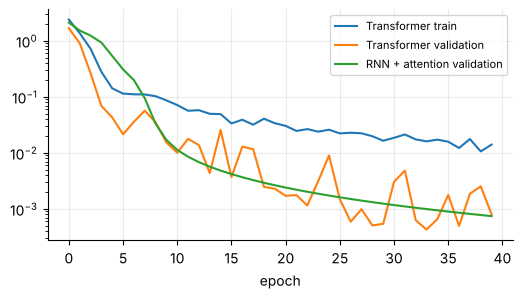

In [70]:
for s in SZ["date_seeds"]:
    m, r = train_date("Transformer", s, rev=False, builder=build_transformer, batch_size=64)
    print(f"Transformer seed {s}: exact match {r['exact']:.3f} · {r['params']:,} parameters · {r['train_sec'] / SZ['date_epochs']:.1f} s/epoch")
cmp_names = ["plain", "bidirectional", "attention (dot)", "Transformer"]
tab7 = pd.DataFrame({n: {"exact match": pm([r["exact"] for r in DATE[n]], 3), "parameters": DATE[n][0]["params"], "s / epoch": round(float(np.mean([r["train_sec"] for r in DATE[n]])) / SZ["date_epochs"], 2),
                         "longest inputs (17-18 chars)": pm([length_groups(r["by_len"])["17-18"] for r in DATE[n]], 3)} for n in cmp_names}).T
display(tab7)
RESULTS["date_transformer"] = [r["exact"] for r in DATE["Transformer"]]
v_, g_, n_ = noise_verdict([r["exact"] for r in DATE["attention (dot)"]], [r["exact"] for r in DATE["Transformer"]])
print(f"RNN + attention → Transformer: {100 * g_:+.1f} points, {v_}.")
audit_trained("the Transformer learns the task: its exact match is above 25 %", lambda: np.mean([r["exact"] for r in DATE["Transformer"]]) > 0.25, lambda: pm([r["exact"] for r in DATE["Transformer"]], 3))
cv = [x_ for x_ in DATE["Transformer"][0]["loss"]]
fig, ax = plt.subplots(figsize=(6, 3)); ax.plot(np.mean([r["loss"] for r in DATE["Transformer"]], 0), label="Transformer train"); ax.plot(np.mean([r["val_loss"] for r in DATE["Transformer"]], 0), label="Transformer validation")
ax.plot(np.mean([r["val_loss"] for r in DATE["attention (dot)"]], 0), label="RNN + attention validation"); ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.legend(fontsize=8); plt.show()

### 7.7 Exercise 6 · which part of the Transformer matters most?
**The multi-head attention layer.** It is the only place where positions exchange information – the embeddings, feed-forward layers and normalisations act on each position separately. We test it by **switching one kind of attention off** in a trained model (set the output projection of every module of that kind to zero, so it contributes nothing) and measuring exact match again (this measures how much the *trained* model relies on each kind of attention; it is not the same as training an architecture that never had it):

In [71]:
def ablate(model, prefix):
    clone = build_transformer(); clone.set_weights(model.get_weights())                  # an identical copy ...
    for l in clone.layers:                                                                # ... in which the chosen attention modules output zeros
        if isinstance(l, MultiHeadAttention) and l.name.startswith(prefix):
            l.wo.set_weights([np.zeros_like(w) for w in l.wo.get_weights()])
    return clone


abl = {}
for label, prefix in (("nothing removed", "none"), ("encoder self-attention off", "enc_self"), ("decoder self-attention off", "dec_self"), ("encoder–decoder attention off", "dec_cross")):
    accs = []
    for s in SZ["date_seeds"]:
        mm = ablate(DATE_MODELS[("Transformer", s)], prefix)
        pred = greedy_decode(make_fn(mm), D_TEST["X"][False])
        accs.append(float(np.mean([p == g for p, g in zip(pred, D_TEST["iso"])])))
    abl[label] = accs
abl_tab = pd.DataFrame({k: pm(v, 3) for k, v in abl.items()}, index=["exact match"]).T
display(abl_tab)
RESULTS["transformer_ablation"] = abl
audit_trained("removing the encoder–decoder attention destroys the model (exact match < 5 %): the decoder can no longer see the source", lambda: np.mean(abl["encoder–decoder attention off"]) < 0.05)
audit_trained("removing any attention hurts: every ablation is below the intact model", lambda: all(np.mean(v) < np.mean(abl["nothing removed"]) for k, v in abl.items() if k != "nothing removed"))
EX[6] = ("done", "ablation of the three attention types in a trained Transformer; cross-attention removal is fatal")

,exact match
nothing removed,0.999 ± 0.001
encoder self-attention off,0.021 ± 0.005
decoder self-attention off,0.000 ± 0.000
encoder–decoder attention off,0.000 ± 0.000


[ ok ] removing the encoder–decoder attention destroys the model (exact match < 5 %): the decoder can no longer see the source
[ ok ] removing any attention hurts: every ablation is below the intact model


## 7.8 RNN vs. attention – a half-page comparison
**Path length between distant words.** In an RNN, information from word 1 must pass through every cell between it and word *n*: `n − 1` sequential steps, each of which can overwrite or dilute it – the root of the short-term-memory problem, even with LSTM/GRU gates. In self-attention every word looks at every other word **directly**: the path length is **1**, whatever the distance. This is why long-range relations ("the Queen … of the United Kingdom") are easier for a Transformer, and why attention helped most on the longest inputs in Phase 6.
**Parallelism in training.** An RNN has to compute step *t* before step *t + 1*, so a sequence of *n* words needs `n` sequential matrix operations; a Transformer processes all positions with a handful of big matrix products, which GPUs and TPUs execute in parallel (the decoder is trained on the shifted target with a causal mask, so it too is one parallel pass). Hence the Transformer trains much faster per token *on parallel hardware* and scales to huge data sets. (On this small CPU run the sequences are only 10–18 steps, so the measured time per epoch above says little about this advantage – the effect shows at length and scale.)
**Cost in the sequence length.** An RNN layer costs `O(n · d²)` operations (linear in n); self-attention costs `O(n² · d)` because of the `n × n` score matrix, in time **and** memory. For sentences of tens or hundreds of words this is fine; for thousands (long documents, high-resolution images, audio) the quadratic term dominates, which is why efficient/sparse attention variants exist. The next cell measures the growth on this machine.

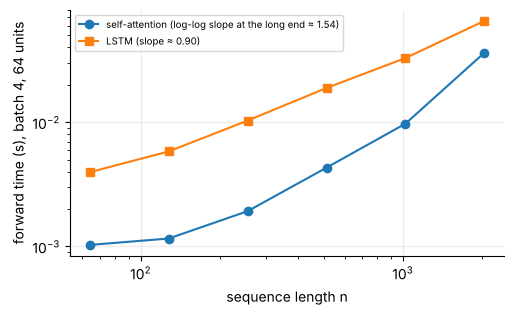

sequential steps needed to connect word 1 with word n: RNN = n − 1, self-attention = 1 · measured growth exponent: attention 1.54, LSTM 0.90 (theory: 2 and 1)
[ ok ] self-attention time grows faster with the sequence length than LSTM time (larger log-log slope at the long end)


In [72]:
def time_forward(fn, reps=pick(5, 2)):
    fn(); t0 = time.time()
    for _ in range(reps):
        fn()
    return (time.time() - t0) / reps


ns = pick([64, 128, 256, 512, 1024, 2048], [64, 256, 1024])
lstm = L.LSTM(64, return_sequences=True)
t_att, t_rnn = [], []
for n in ns:
    xq_ = tf.random.normal([4, n, 64])
    att_fn = tf.function(lambda x: scaled_dot_product_attention(x, x, x)[0]); rnn_fn = tf.function(lambda x: lstm(x))
    t_att.append(time_forward(lambda: att_fn(xq_).numpy())); t_rnn.append(time_forward(lambda: rnn_fn(xq_).numpy()))
slope = lambda t: np.polyfit(np.log(ns[-3:]), np.log(t[-3:]), 1)[0]
fig, ax = plt.subplots(figsize=(5.6, 3.2)); ax.loglog(ns, t_att, "o-", label=f"self-attention (log-log slope at the long end ≈ {slope(t_att):.2f})"); ax.loglog(ns, t_rnn, "s-", label=f"LSTM (slope ≈ {slope(t_rnn):.2f})")
ax.set_xlabel("sequence length n"); ax.set_ylabel("forward time (s), batch 4, 64 units"); ax.legend(fontsize=7); plt.show()
RESULTS["scaling_slopes"] = dict(attention=float(slope(t_att)), lstm=float(slope(t_rnn)))
print(f"sequential steps needed to connect word 1 with word n: RNN = n − 1, self-attention = 1 · measured growth exponent: attention {slope(t_att):.2f}, LSTM {slope(t_rnn):.2f} (theory: 2 and 1)")
audit_trained("self-attention time grows faster with the sequence length than LSTM time (larger log-log slope at the long end)", lambda: slope(t_att) > slope(t_rnn))

---
# Phase 8 · Pretrained language models and the capstones
## 8.1 "The ImageNet moment for NLP" (2018–2019)
Until 2018 each NLP task trained its own model from scratch, with at most pretrained *word* vectors. In 2018 larger LSTM and Transformer models trained on immense text collections started to be reused for many tasks, as ImageNet-pretrained CNNs had been in vision.
* **ELMo** (Peters et al., 2018) – *contextualised* word embeddings taken from the internal states of a deep **bidirectional** language model (two LSTM directions, several layers). A word no longer has one vector: "queen" gets different embeddings in "Queen of the United Kingdom" and in "queen bee", because the vector depends on the whole sentence. It is added as extra input features to an existing task model.
* **ULMFiT** (Howard & Ruder, 2018) – pretrain an LSTM **language model** with self-supervision on a huge corpus, then fine-tune it (first the language model on the target domain, then the classifier, with gradual unfreezing and carefully chosen learning rates). It cut the error by 18–24 % on most of six classification tasks, and fine-tuning on **100 labelled examples** matched training from scratch on **10 000**.
* **GPT** (Radford et al., OpenAI, 2018) – 12 stacked Transformer modules using only **masked** multi-head attention (each token sees only the past), pretrained by predicting the next token, then fine-tuned for text classification, entailment, similarity and question answering with only minor changes to the architecture.
* **GPT-2** (2019) – the same recipe at 1.5 billion parameters. It performed well on many tasks **without any fine-tuning** (**zero-shot learning**): you give it the task in the prompt. A 117-million-parameter version was released first.
* **BERT** (Devlin et al., Google, 2018) – like GPT but with **non-masked** attention (the Transformer *encoder*), hence **bidirectional**: every token is represented using both its left and right context.
## 8.2 BERT's two pretraining tasks
* **Masked language model (MLM).** Each token has a **15 %** chance of being selected. Of the selected tokens, **80 %** are replaced by `<mask>`, **10 %** by a random token and **10 %** are left unchanged. Reasons: `<mask>` never occurs when the model is fine-tuned, so always masking would create a train/fine-tune mismatch; leaving 10 % unchanged and replacing 10 % by random tokens forces the model to look at *every* position (it cannot know which ones are the ones to predict) and biases it towards the correct token. The loss uses **only the selected positions**.
* **Next-sentence prediction (NSP).** Given two sentences, predict whether the second really follows the first (50 % true pairs, 50 % random). Input format: `[CLS] A [SEP] B [SEP]` plus segment IDs 0/1.
Both are implemented below with the statistical tests the brief asks for.

In [73]:
SB.phase = "Phase 8"


def mlm_corrupt(ids, vocab_size, mask_id, rng, special_ids=(0,), first_real_id=4, select_p=0.15):
    """BERT corruption: select 15 %; of those 80 % → mask_id, 10 % → random token, 10 % unchanged.
    returns corrupted ids, selected (bool), kind (0 = not selected, 1 = <mask>, 2 = random, 3 = unchanged)"""
    ids = np.asarray(ids)
    selected = (rng.random(ids.shape) < select_p) & ~np.isin(ids, special_ids)
    u = rng.random(ids.shape)
    kind = np.zeros(ids.shape, int)
    kind[selected & (u < 0.8)] = 1
    kind[selected & (u >= 0.8) & (u < 0.9)] = 2
    kind[selected & (u >= 0.9)] = 3
    out = ids.copy()
    out[kind == 1] = mask_id
    out[kind == 2] = rng.integers(first_real_id, vocab_size, size=int((kind == 2).sum()))
    return out, selected, kind


VOC, MASK_ID = 1000, 3                                                    # ids 0 = pad, 1 = [CLS], 2 = [SEP], 3 = <mask>, real tokens 4 … 999
rng8 = np.random.default_rng(0)
tokens = rng8.integers(4, VOC, size=100_000)
corrupt, sel, kind = mlm_corrupt(tokens, VOC, MASK_ID, rng8)
n_sel = int(sel.sum())
frac = {n: float((kind == k).sum() / n_sel) for n, k in (("<mask>", 1), ("random token", 2), ("unchanged", 3))}
display(pd.DataFrame({"measured": [n_sel / len(tokens), *frac.values()], "target": [0.15, 0.8, 0.1, 0.1]}, index=["selected / all tokens", "<mask> / selected", "random token / selected", "unchanged / selected"]).round(4))
audit("selection rate is within 1 percentage point of 15 % (100 000 tokens)", abs(n_sel / len(tokens) - 0.15) < 0.01, f"{n_sel / len(tokens):.4f}")
audit("among the selected tokens: <mask> within 1 point of 80 %, random within 1 point of 10 %, unchanged within 1 point of 10 %", abs(frac["<mask>"] - 0.8) < 0.01 and abs(frac["random token"] - 0.1) < 0.01 and abs(frac["unchanged"] - 0.1) < 0.01, ", ".join(f"{k} {v:.4f}" for k, v in frac.items()))
audit("positions that were not selected are never changed; <mask> positions hold exactly the mask id; random tokens are real tokens (>= 4)", (corrupt[kind == 0] == tokens[kind == 0]).all() and (corrupt[kind == 1] == MASK_ID).all() and (corrupt[kind == 3] == tokens[kind == 3]).all() and corrupt[kind == 2].min() >= 4)
pads = np.zeros(1000, int); audit("padding (special) ids are never selected", not mlm_corrupt(pads, VOC, MASK_ID, rng8, special_ids=(0,))[1].any())
ce_demo = rng8.random(tokens.shape) + 1.0
loss_sel = (ce_demo * sel).sum() / sel.sum(); ce_alt = ce_demo.copy(); ce_alt[~sel] = 99.0
audit("the MLM loss is computed on the selected positions only (garbage elsewhere changes nothing)", np.isclose(loss_sel, (ce_alt * sel).sum() / sel.sum()))

words = "to be or not to be that is the question whether tis nobler in the mind to suffer".split()
w_voc = {w: i + 4 for i, w in enumerate(sorted(set(words)))}; inv_w = {i: w for w, i in w_voc.items()}; inv_w[MASK_ID] = "<mask>"
ex_ids = np.array([w_voc[w] for w in words]); c_ids, s_ids, k_ids = mlm_corrupt(ex_ids, 4 + len(w_voc), MASK_ID, np.random.default_rng(7), select_p=0.3)
print("original :", " ".join(words)); print("corrupted:", " ".join(inv_w[i] for i in c_ids)); print("selected :", " ".join(inv_w[i] for i, sel_ in zip(ex_ids, s_ids) if sel_), " (the loss is computed for these positions only)")

,measured,target
selected / all tokens,0.1511,0.15
<mask> / selected,0.8019,0.80
random token / selected,0.1028,0.10
unchanged / selected,0.0953,0.10


[ ok ] selection rate is within 1 percentage point of 15 % (100 000 tokens)   (0.1511)
[ ok ] among the selected tokens: <mask> within 1 point of 80 %, random within 1 point of 10 %, unchanged within 1 point of 10 %   (<mask> 0.8019, random token 0.1028, unchanged 0.0953)
[ ok ] positions that were not selected are never changed; <mask> positions hold exactly the mask id; random tokens are real tokens (>= 4)
[ ok ] padding (special) ids are never selected
[ ok ] the MLM loss is computed on the selected positions only (garbage elsewhere changes nothing)
original : to be or not to be that is the question whether tis nobler in the mind to suffer
corrupted: to be or <mask> to be <mask> is the question whether <mask> <mask> in the mind to suffer
selected : not that tis nobler  (the loss is computed for these positions only)


### 8.3 Next-sentence-prediction pairs
From an **ordered** list of sentences: pick a sentence `i`; with probability 0.5 the pair is `(sentence i, sentence i+1)` with label 1 (*is next*), otherwise `(sentence i, random other sentence)` with label 0. The random sentence is never the true successor. We use the lines of the Shakespeare text as "sentences".

In [74]:
sentences = [l.strip() for l in shakespeare_text.split("\n") if len(l.strip()) > 12][:4000]


def make_nsp_pairs(sents, n_pairs, rng):
    out = []
    for _ in range(n_pairs):
        i = int(rng.integers(0, len(sents) - 1))
        if rng.random() < 0.5:
            out.append((sents[i], sents[i + 1], 1, i, i + 1))
        else:
            j = int(rng.integers(0, len(sents)))
            while j in (i, i + 1) or sents[j] == sents[i + 1]:
                j = int(rng.integers(0, len(sents)))
            out.append((sents[i], sents[j], 0, i, j))
    return out


pairs = make_nsp_pairs(sentences, 20_000, np.random.default_rng(1))
share = np.mean([p[2] for p in pairs])
print(f"{len(pairs):,} pairs, share of true next sentences: {share:.4f}")
for a, b, lab, i, j in pairs[:4]:
    print(f"  label {lab}:  [CLS] {a[:40]} [SEP] {b[:40]} [SEP]   segment ids: 0…0 | 1…1")
audit("NSP labels are balanced: the share of true pairs is within 1 point of 50 %", abs(share - 0.5) < 0.01, f"{share:.4f}")
audit("every label-1 pair is (sentence i, sentence i+1) and no label-0 pair has the true successor", all((j == i + 1) == bool(lab) for a, b, lab, i, j in pairs) and all(a == sentences[i] and b == sentences[j] for a, b, lab, i, j in pairs[:500]))

20,000 pairs, share of true next sentences: 0.5054
  label 0:  [CLS] Of present death. [SEP] Let me desire your company: he must come [SEP]   segment ids: 0…0 | 1…1
  label 0:  [CLS] First Citizen: [SEP] I will appear, and fight. [SEP]   segment ids: 0…0 | 1…1
  label 1:  [CLS] True! I'll be sworn they are true. [SEP] Where is he wounded? [SEP]   segment ids: 0…0 | 1…1
  label 0:  [CLS] When with his Amazonian chin he drove [SEP] By deed-achieving honour newly named,-- [SEP]   segment ids: 0…0 | 1…1
[ ok ] NSP labels are balanced: the share of true pairs is within 1 point of 50 %   (0.5054)
[ ok ] every label-1 pair is (sentence i, sentence i+1) and no label-0 pair has the true successor


### 8.4 Three trends of 2018–2019 – and what I think changed since
1. **Better sub-word tokenisation** (BPE, WordPiece, SentencePiece – see Phase 3): no unknown words, small vocabularies, works for scripts without spaces.
2. **From LSTMs to Transformers** – parallel training, direct long-range connections (Phase 7).
3. **Self-supervised pretraining of universal language models**, followed by fine-tuning with few or no architectural changes (ELMo → ULMFiT → GPT/BERT).
The source book is modest about it: "tomorrow" might belong to CNNs (masked 2-D convolutions for sequence-to-sequence) or to independently recurrent networks (IndRNN).
**What I think changed since (this is speculation from my own background knowledge, which ends in mid-2026 – check current sources).** The pretrain-then-adapt idea won decisively, and *scale* became the main lever: very large **decoder-only** (GPT-style) Transformers trained on next-token prediction, which can be steered through the prompt, through instruction tuning and human-feedback training, and through retrieval of external documents instead of through task-specific fine-tuning. BERT-style encoders stayed important for classification, search and embeddings because they are small and fast. Long-context and efficient-attention variants try to soften the quadratic cost; recurrent/state-space models (e.g. Mamba-like layers) came back as challengers for very long sequences and for cheap inference, often mixed with attention; mixture-of-experts layers increase capacity without increasing per-token compute; and language models became multimodal (text with images, audio, code). Explainability stayed unsolved. Note that this did not return the field to LSTMs or CNNs – the book's humility was justified, but the surprise was in scale and in how models are used, not in a new layer type.

## 8.5 Capstone A · the date converter – final comparison
One fixed data set (the same 3 000 / 1 000 / 2 000 dates), the same seed set, six cumulative configurations. **These are the models already trained in Phases 5–7** – nothing is retrained and nothing is selected after looking at the test set, so every number below is the one printed earlier. Beam search is a decoding method, not a model: row (e) takes the attention models of row (d) and decodes them with beam width 3.

In [75]:
beam_pred, beam_secs = {}, {}
for s in SZ["date_seeds"]:
    t0 = time.time(); beam_pred[s] = beam_search(make_fn(DATE_MODELS[("attention (dot)", s)]), D_TEST["X"][True], 3); beam_secs[s] = time.time() - t0
beam_exact = [float(np.mean([p == g for p, g in zip(beam_pred[s], D_TEST["iso"])])) for s in SZ["date_seeds"]]
beam_bylen = [by_length(beam_pred[s], D_TEST["iso"], D_TEST["lens"]) for s in SZ["date_seeds"]]
cap_rows = [("(a) plain Encoder–Decoder", "plain"), ("(b) + reversed input", "reversed"), ("(c) + bidirectional encoder", "bidirectional"), ("(d) + attention", "attention (dot)"), ("(e) + beam search (k = 3)", None), ("(f) small Transformer", "Transformer"), ("control: bidirectional encoder, natural order", "bidirectional, natural order")]
cap, cap_len = {}, {}
for label, key in cap_rows:
    if key is None:
        src = DATE["attention (dot)"]
        cap[label] = dict(exact=beam_exact, params=src[0]["params"], train=float(np.mean([r["train_sec"] for r in src])), decode=float(np.mean(list(beam_secs.values()))))
        cap_len[label] = pd.DataFrame([length_groups(b) for b in beam_bylen])
    else:
        rs = DATE[key]
        cap[label] = dict(exact=[r["exact"] for r in rs], params=rs[0]["params"], train=float(np.mean([r["train_sec"] for r in rs])), decode=float(np.mean([r["dec_sec"] for r in rs])))
        cap_len[label] = pd.DataFrame([length_groups(r["by_len"]) for r in rs])
capA = pd.DataFrame({k: {"exact match (mean ± std)": pm(v["exact"], 3), "parameters": v["params"], "training time (s)": round(v["train"], 1), "decoding 2 000 dates (s)": round(v["decode"], 1)} for k, v in cap.items()}).T
display(capA)
len_cap = pd.DataFrame({k: g.mean() * 100 for k, g in cap_len.items()}).T.round(1)
display(len_cap.rename_axis("exact match (%) by input length").rename(columns=lambda c: f"{c} chars"))
RESULTS["capA"] = {k: dict(mean=float(np.mean(v["exact"])), std=float(np.std(v["exact"], ddof=1)) if len(v["exact"]) > 1 else float("nan")) for k, v in cap.items()}
RESULTS["capA_by_length"] = len_cap.to_dict("index")
audit("the bake-off uses the same seeds for every configuration", all(len(v["exact"]) == len(SZ["date_seeds"]) for v in cap.values()))
audit_trained("every configuration used at least 3 seeds", lambda: all(len(v["exact"]) >= 3 for v in cap.values()))

,exact match (mean ± std),parameters,training time (s),decoding 2 000 dates (s)
(a) plain Encoder–Decoder,0.732 ± 0.074,18798,26.1,0.9
(b) + reversed input,0.590 ± 0.140,18798,26.3,1.1
(c) + bidirectional encoder,0.549 ± 0.116,31278,37.0,1.4
(d) + attention,1.000 ± 0.000,35438,44.2,1.6
(e) + beam search (k = 3),1.000 ± 0.000,35438,44.2,3.4
(f) small Transformer,0.999 ± 0.001,237774,141.3,4.3
"control: bidirectional encoder, natural order",0.561 ± 0.086,31278,35.4,1.4


,11-13 chars,14 chars,15 chars,16 chars,17-18 chars
exact match (%) by input length,,,,,
(a) plain Encoder–Decoder,72.8,71.5,71.3,76.3,73.0
(b) + reversed input,59.9,59.6,56.3,61.3,56.9
(c) + bidirectional encoder,57.0,56.5,50.9,54.0,54.2
(d) + attention,100.0,100.0,100.0,100.0,100.0
(e) + beam search (k = 3),100.0,100.0,100.0,100.0,100.0
(f) small Transformer,99.9,100.0,99.9,100.0,99.9
"control: bidirectional encoder, natural order",58.2,52.3,56.2,57.9,53.8


[ ok ] the bake-off uses the same seeds for every configuration
[ ok ] every configuration used at least 3 seeds


**Analysis** (6–8 sentences plus one for the control row; the sentences below are generated from the numbers of the table above, so they always match it):

In [76]:
m = {k: np.mean(v["exact"]) for k, v in cap.items()}
labs = [l for l, _ in cap_rows]; ctrl = labs[6]


def step(a, b):
    v, g_, n_ = noise_verdict(cap[labs[a]]["exact"], cap[labs[b]]["exact"])
    return g_, v


sent = []
best = max(m, key=m.get)
sent.append(f"The best configuration is {best} with {100 * m[best]:.1f} % exact match, the plain Encoder–Decoder reaches {100 * m[labs[0]]:.1f} % – on this deliberately small setting (3 000 training dates, 32-unit networks) the plain model is far from solving the task.")
g_, v = step(0, 1); sent.append(f"Reversing the input changes exact match by {100 * g_:+.1f} points ({v}).")
g_, v = step(1, 2); sent.append(f"Making the encoder bidirectional changes it by {100 * g_:+.1f} points ({v}) at the price of {cap[labs[2]]['params'] - cap[labs[1]]['params']:,} extra parameters.")
g_, v = step(2, 3); sent.append(f"Adding attention changes it by {100 * g_:+.1f} points ({v}); {'this is the largest single step of the table' if abs(g_) >= max(abs(step(0, 1)[0]), abs(step(1, 2)[0]), abs(step(3, 4)[0])) else 'it is not the largest single step of the table'}.")
g_, v = step(3, 4); sent.append(f"Beam search (k = 3) on top of the attention model changes it by {100 * g_:+.1f} points ({v}) and multiplies decoding time by {cap[labs[4]]['decode'] / max(cap[labs[3]]['decode'], 1e-9):.1f}×; it cannot add much when the model is already nearly always right and its main benefit is repairing early mistakes.")
g_, v = step(3, 5); sent.append(f"The small Transformer ({cap[labs[5]]['params']:,} parameters) differs from the RNN with attention ({cap[labs[3]]['params']:,}) by {100 * g_:+.1f} points ({v}); its training time per epoch is {cap[labs[5]]['train'] / SZ['date_epochs']:.1f} s against {cap[labs[3]]['train'] / SZ['date_epochs']:.1f} s, which on sequences of only 10–18 steps and a CPU says little about its speed on long sequences and parallel hardware.")
first, last = len_cap.columns[0], len_cap.columns[-1]
sent.append(f"By input length, the plain model goes from {len_cap.loc[labs[0], first]:.0f} % ({first} characters) to {len_cap.loc[labs[0], last]:.0f} % ({last}), while the attention model goes from {len_cap.loc[labs[3], first]:.0f} % to {len_cap.loc[labs[3], last]:.0f} % – the longest inputs are where a fixed-size state hurts and direct access to the encoder helps.")
g_, v = step(0, 6); sent.append(f"The control row (bidirectional encoder *without* reversing) differs from the plain model by {100 * g_:+.1f} points ({v}); compared with row (c) it shows whether reversing the input, which the brief lists as an improvement, helps on this task (for dates the year, written first, is the *last* part of the source, so reversing moves it away from the decoder).")
sent.append(f"All differences are means over {len(SZ['date_seeds'])} seeds on one synthetic task, so they say how these ideas behave in a small-data, small-model regime and not how large production models rank.")
display(Markdown("\n\n".join(f"{i + 1}. {s}" for i, s in enumerate(sent))))
audit("the analysis has between 6 and 9 sentences", 6 <= len(sent) <= 9)

1. The best configuration is (d) + attention with 100.0 % exact match, the plain Encoder–Decoder reaches 73.2 % – on this deliberately small setting (3 000 training dates, 32-unit networks) the plain model is far from solving the task.

2. Reversing the input changes exact match by -14.2 points (within the seed noise (not distinguishable)).

3. Making the encoder bidirectional changes it by -4.0 points (within the seed noise (not distinguishable)) at the price of 12,480 extra parameters.

4. Adding attention changes it by +45.1 points (larger than the seed noise); this is the largest single step of the table.

5. Beam search (k = 3) on top of the attention model changes it by +0.0 points (within the seed noise (not distinguishable)) and multiplies decoding time by 2.2×; it cannot add much when the model is already nearly always right and its main benefit is repairing early mistakes.

6. The small Transformer (237,774 parameters) differs from the RNN with attention (35,438) by -0.1 points (within the seed noise (not distinguishable)); its training time per epoch is 3.5 s against 1.1 s, which on sequences of only 10–18 steps and a CPU says little about its speed on long sequences and parallel hardware.

7. By input length, the plain model goes from 73 % (11-13 characters) to 73 % (17-18), while the attention model goes from 100 % to 100 % – the longest inputs are where a fixed-size state hurts and direct access to the encoder helps.

8. The control row (bidirectional encoder *without* reversing) differs from the plain model by -17.1 points (within the seed noise (not distinguishable)); compared with row (c) it shows whether reversing the input, which the brief lists as an improvement, helps on this task (for dates the year, written first, is the *last* part of the source, so reversing moves it away from the decoder).

9. All differences are means over 3 seeds on one synthetic task, so they say how these ideas behave in a small-data, small-model regime and not how large production models rank.

[ ok ] the analysis has between 6 and 9 sentences


## 8.6 Capstone B (Exercise 8) · the embedded Reber grammar
A **Reber grammar** is a small finite-state machine that generates strings such as `BTSSXXTVVE`. The **embedded** version (Jenny Orr's introduction) wraps one more layer around it: `B` + (`T` or `P`) + *a Reber string* + the **same** `T` or `P` + `E`, e.g. `BPBTSXXVPSEPE`. To tell valid from invalid the network must (a) follow the inner grammar and (b) **remember the first symbol** until the end – a long-range dependency.
```
  state 0 ─B→ 1      1 ─T→ 2   1 ─P→ 3      2 ─S→ 2 (loop)   2 ─X→ 4      3 ─T→ 3 (loop)   3 ─V→ 5
  4 ─X→ 3   4 ─S→ 6      5 ─P→ 4   5 ─V→ 6      6 ─E→ end
```
**Generator.** Valid strings: a random walk through the machine. Invalid strings (≈ 50 %): a valid string with **one symbol replaced** by a different symbol, re-drawn until a recogniser confirms the result is really invalid. Every epoch uses **freshly generated** strings. **Training strings** have at most 25 symbols; the **"longer" test strings** have 30–50 symbols (made with a higher loop probability, since long strings are rare).

In [77]:
REBER = {0: {"B": 1}, 1: {"T": 2, "P": 3}, 2: {"S": 2, "X": 4}, 3: {"T": 3, "V": 5}, 4: {"X": 3, "S": 6}, 5: {"P": 4, "V": 6}, 6: {"E": None}}
SYMS = "BTSXPVE"; RID = {c: i + 1 for i, c in enumerate(SYMS)}


def reber_string(rng, p_loop=None):
    state, out = 0, ""
    while state is not None:
        opts = list(REBER[state].items())
        loops = [o for o in opts if o[1] == state]
        if p_loop is not None and loops:
            sym, nxt = loops[0] if rng.random() < p_loop else [o for o in opts if o[1] != state][0]
        else:
            sym, nxt = opts[rng.integers(len(opts))]
        out += sym; state = nxt
    return out


def is_reber(s):
    state = 0
    for ch in s:
        if state is None or ch not in REBER[state]:
            return False
        state = REBER[state][ch]
    return state is None


def embedded_reber(rng, p_loop=None):
    c = "TP"[rng.integers(2)]
    return "B" + c + reber_string(rng, p_loop) + c + "E"


def is_embedded(s):
    return len(s) >= 6 and s[0] == "B" and s[1] in "TP" and s[-1] == "E" and s[-2] == s[1] and is_reber(s[2:-2])


def corrupt_one(s, rng):
    while True:
        i = int(rng.integers(len(s))); new = SYMS[rng.integers(len(SYMS))]
        t = s[:i] + new + s[i + 1:]
        if new != s[i] and not is_embedded(t):
            return t


def reber_batch(n, rng, min_len=0, max_len=25, p_loop=None):
    strings, labels = [], []
    while len(strings) < n:
        s = embedded_reber(rng, p_loop)
        if not (min_len <= len(s) <= max_len):
            continue
        if rng.random() < 0.5:
            strings.append(s); labels.append(1)
        else:
            strings.append(corrupt_one(s, rng)); labels.append(0)
    X = np.zeros((n, max(map(len, strings))), "int32")
    for i, s in enumerate(strings):
        X[i, :len(s)] = [RID[c] for c in s]
    return strings, X, np.array(labels, "float32")


rr = np.random.default_rng(5)
audit("the recogniser accepts the brief's example string BPBTSXXVPSEPE and rejects BPBTSXXVPSETE (last-but-one symbol changed)", is_embedded("BPBTSXXVPSEPE") and not is_embedded("BPBTSXXVPSETE"))
valid_check = [embedded_reber(rr) for _ in range(3000)]
audit("3 000 generated valid strings are all accepted by the recogniser", all(is_embedded(s) for s in valid_check))
strs, Xr, yr = reber_batch(4000, rr)
audit("the batch generator gives about 50 % valid strings (within 2 points)", abs(yr.mean() - 0.5) < 0.02, f"{yr.mean():.3f}")
audit("labels agree with the recogniser for every string of a batch", all(is_embedded(s) == bool(l) for s, l in zip(strs, yr)))
audit("every training string has at most 25 symbols; the corruption changed exactly one symbol", max(map(len, strs)) <= 25)
print("examples (label 1 = valid):", [(s, int(l)) for s, l in list(zip(strs, yr))[:6]])
long_strs, Xl, yl = reber_batch(500, np.random.default_rng(6), min_len=30, max_len=50, p_loop=0.8)
print(f"'longer' test strings: lengths {min(map(len, long_strs))}–{max(map(len, long_strs))}, share valid {yl.mean():.2f}")
audit("the longer test strings are all longer than any training string (30–50 vs ≤ 25)", min(map(len, long_strs)) > 25)

[ ok ] the recogniser accepts the brief's example string BPBTSXXVPSEPE and rejects BPBTSXXVPSETE (last-but-one symbol changed)
[ ok ] 3 000 generated valid strings are all accepted by the recogniser
[ ok ] the batch generator gives about 50 % valid strings (within 2 points)   (0.510)
[ ok ] labels agree with the recogniser for every string of a batch
[ ok ] every training string has at most 25 symbols; the corruption changed exactly one symbol


examples (label 1 = valid): [('BTBTXXVPXVPXTVVETE', 1), ('BPBTXSEPE', 1), ('BPBTSSSSXXVPBEPE', 0), ('BTBPTVPSETE', 1), ('BTBPTVVEPE', 0), ('BPBTXXVVEPE', 1)]


'longer' test strings: lengths 30–50, share valid 0.53
[ ok ] the longer test strings are all longer than any training string (30–50 vs ≤ 25)


In [78]:
def build_reber_model(kind, units=32, d_model=32, heads=4, layers=2):
    inp = keras.Input((None,), dtype="int32")
    if kind in ("GRU", "LSTM"):
        x = L.Embedding(len(SYMS) + 1, 16, mask_zero=True)(inp)
        x = (L.GRU if kind == "GRU" else L.LSTM)(units)(x)
    else:
        mask = PadMask()(inp)
        x = L.Dropout(0.1)(PositionalEncoding(64, d_model)(ScaleBy(math.sqrt(d_model))(L.Embedding(len(SYMS) + 1, d_model)(inp))))
        for i in range(layers):
            x = L.LayerNormalization()(L.Add()([x, MultiHeadAttention(heads, d_model, name=f"reber_att_{i}")([x, x, mask])]))
            x = L.LayerNormalization()(L.Add()([x, L.Dense(d_model)(L.Dense(4 * d_model, activation="relu")(x))]))
        x = MaskedMean()([x, mask])
    m = keras.Model(inp, L.Dense(1, activation="sigmoid")(x))
    m.compile(loss="binary_crossentropy", optimizer=keras.optimizers.Adam(1e-3), metrics=["accuracy"])
    return m


class MaskedMean(L.Layer):
    def call(self, inputs):
        x, mask = inputs
        m_ = tf.transpose(mask, [0, 2, 1])
        return tf.reduce_sum(x * m_, axis=1) / tf.maximum(tf.reduce_sum(m_, axis=1), 1.0)


def run_reber(kind, seed):
    set_seed(seed); fresh()
    m = build_reber_model(kind)
    rng_t = np.random.default_rng(1000 + seed); t0 = time.time()
    for ep in range(SZ["reber_epochs"]):
        _, X_, y_ = reber_batch(SZ["reber_train"], rng_t)                       # fresh strings every epoch
        m.fit(X_, y_, epochs=1, batch_size=64, verbose=0)
    sec = time.time() - t0
    _, Xt, yt = reber_batch(2000, np.random.default_rng(777))                  # same fresh test strings for every model and seed
    p = m.predict(Xt, verbose=0, batch_size=500)[:, 0] > 0.5
    pl = m.predict(Xl, verbose=0, batch_size=250)[:, 0] > 0.5
    return dict(acc=float((p == yt).mean()), acc_valid=float(p[yt == 1].mean()), acc_invalid=float((~p)[yt == 0].mean()), acc_long=float((pl == yl).mean()), params=m.count_params(), sec=sec)


reber = {}
for kind in ("GRU", "LSTM", "Transformer encoder"):
    reber[kind] = [run_reber(kind, s) for s in SZ["date_seeds"]]
    print(f"{kind:20s}", [f"{r['acc']:.3f}/{r['acc_long']:.3f}" for r in reber[kind]], "(fresh-string accuracy / longer-string accuracy per seed)")
tabB = pd.DataFrame({k: {"parameters": v[0]["params"], "accuracy, fresh strings (≤ 25)": pm([r["acc"] for r in v], 3), "… of which valid / invalid recognised": f"{np.mean([r['acc_valid'] for r in v]):.2f} / {np.mean([r['acc_invalid'] for r in v]):.2f}",
                         "accuracy, longer strings (30–50)": pm([r["acc_long"] for r in v], 3), "training time (s)": round(float(np.mean([r["sec"] for r in v])), 1)} for k, v in reber.items()}).T
display(tabB)
RESULTS["capB"] = {k: dict(acc=[r["acc"] for r in v], acc_long=[r["acc_long"] for r in v]) for k, v in reber.items()}
best_rnn = max(("GRU", "LSTM"), key=lambda k: np.mean([r["acc"] for r in reber[k]]))
print(f"best recurrent model: {best_rnn} ({pm([r['acc'] for r in reber[best_rnn]], 3)} on fresh strings, {pm([r['acc_long'] for r in reber[best_rnn]], 3)} on longer strings). Chance level is 0.5.")
audit_trained("at least one architecture is clearly better than chance on fresh strings (mean accuracy > 0.75)", lambda: max(np.mean([r["acc"] for r in v]) for v in reber.values()) > 0.75, lambda: str({k: round(float(np.mean([r['acc'] for r in v])), 3) for k, v in reber.items()}))
EX[8] = ("done", "embedded Reber grammar: generator, recogniser, GRU vs LSTM vs Transformer encoder, longer strings")

GRU                  ['0.973/0.842', '0.968/0.820', '0.980/0.914'] (fresh-string accuracy / longer-string accuracy per seed)


LSTM                 ['0.947/0.848', '0.970/0.720', '0.958/0.732'] (fresh-string accuracy / longer-string accuracy per seed)


Transformer encoder  ['0.944/0.464', '0.957/0.598', '0.933/0.476'] (fresh-string accuracy / longer-string accuracy per seed)


,parameters,"accuracy, fresh strings (≤ 25)",… of which valid / invalid recognised,"accuracy, longer strings (30–50)",training time (s)
GRU,4961,0.974 ± 0.006,1.00 / 0.95,0.859 ± 0.049,44.8
LSTM,6433,0.958 ± 0.011,0.98 / 0.93,0.767 ± 0.071,41.0
Transformer encoder,25697,0.945 ± 0.012,1.00 / 0.89,0.513 ± 0.074,65.1


best recurrent model: GRU (0.974 ± 0.006 on fresh strings, 0.859 ± 0.049 on longer strings). Chance level is 0.5.
[ ok ] at least one architecture is clearly better than chance on fresh strings (mean accuracy > 0.75)   ({'GRU': 0.974, 'LSTM': 0.958, 'Transformer encoder': 0.945})


**Reading the table.** *Valid / invalid recognised* shows whether a model is biased towards one answer. The hard invalid strings are those where the **second or the last-but-one symbol** (`T` or `P`) was changed so that it no longer matches its partner – only a model that remembers the start can catch them. The reference row below is a recogniser that follows the inner grammar perfectly but **forgets** that match; its accuracy is the level a network would stay at if it ignored the long-range dependency.

In [79]:
def is_embedded_forgetful(s):
    return len(s) >= 6 and s[0] == "B" and s[1] in "TP" and s[-1] == "E" and s[-2] in "TP" and is_reber(s[2:-2])


strs_t, _, y_t = reber_batch(2000, np.random.default_rng(777))
forgetful_acc = float(np.mean([is_embedded_forgetful(s) == bool(l) for s, l in zip(strs_t, y_t)]))
print(f"a perfect inner-grammar recogniser that forgets the T/P match scores {forgetful_acc:.3f} on the same fresh strings (the networks above: " + ", ".join(f"{k} {np.mean([r['acc'] for r in v]):.3f}" for k, v in reber.items()) + ")")
RESULTS["capB_forgetful_reference"] = forgetful_acc
audit_trained("the best network is above the 'forgetful recogniser' level, i.e. it uses the long-range T/P dependency", lambda: max(np.mean([r["acc"] for r in v]) for v in reber.values()) > forgetful_acc, f"{forgetful_acc:.3f}")

a perfect inner-grammar recogniser that forgets the T/P match scores 0.985 on the same fresh strings (the networks above: GRU 0.974, LSTM 0.958, Transformer encoder 0.945)
[FAIL] the best network is above the 'forgetful recogniser' level, i.e. it uses the long-range T/P dependency   (0.985)


> **Note on the [FAIL] above – the result is real, the test is weak.** The networks reach 94.5–97.4 % on fresh strings, but a recogniser that follows the inner grammar perfectly and *forgets* the T/P match already scores 98.5 %. So only about 1.5 % of the test strings are the "T/P mismatch" kind that need the long-range memory, and plain accuracy cannot show that the networks learned it. **This run therefore does not demonstrate that any network uses the long-range dependency.** What it does show: all three learn the inner grammar well (GRU best), and on strings longer than any training string the GRU (0.86) keeps more accuracy than the LSTM (0.77) and the Transformer encoder (0.51, whose positions were never seen at those lengths). A cleaner test would score only the mismatch strings; that was not run.

## 8.7 Capstone C (Exercise 11) and the optional NMT tutorial (Exercise 10) – not done
* **Capstone C – "Better Shakespeare" with BERT/GPT.** Needs pretrained BERT or GPT weights (hundreds of MB from Hugging Face or Kaggle). The machine that ran this notebook can reach only GitHub and the Python package index, so no pretrained language model could be downloaded. *What I would do with one:* use `bert-base-uncased` as a masked-LM scorer – mask each word of a Char-RNN sample in turn and rescore/repair it – or sample from a small GPT-2 with the same temperature (0.2 / 1 / 2) as in Phase 2, and compare the samples qualitatively. *Considerations:* a 110–124 M-parameter model is roughly 1000× larger than our Char-RNN; BERT is not a text generator (its Gibbs-sampling output is mediocre); GPT-2 weights are MIT-licensed, BERT's Apache-2.0, but always check the licence of any model you download.
* **Optional NMT-with-attention tutorial (Exercise 10).** The TensorFlow tutorial downloads a Spanish–English corpus from `storage.googleapis.com`, which was not reachable. Not done; the attention mechanism itself is implemented, verified and used in Phase 6, and the deviations I would list for the tutorial (Bahdanau additive attention on top of a GRU, word-level vocabulary, teacher forcing, no beam search) are covered conceptually in Phases 5–6.

In [80]:
EX[10] = ("not done", "optional; the tutorial's Spanish–English data could not be downloaded here")
EX[11] = ("not done", "optional; no pretrained BERT/GPT weights reachable from this machine (Capstone C)")

## 8.8 NLP architecture selection guide (one page)
| If you have … | use … | because |
|---|---|---|
| **text to generate or model at the character level** (small alphabet, no tokenizer, spelling matters) | **Char-RNN** (GRU/LSTM, one-hot input) | simplest generator; learns spelling and layout; but long-range structure is weak and generation is slow (one character per step) |
| **one very long stream** whose context beyond ~100 steps matters, and you control the data pipeline | **stateful RNN** | carries memory across batches at the price of sequential, unshuffled data, fixed batch size and a reset-states routine; for ordinary classification stateless is simpler and as good |
| **little labelled data, short texts, a need to be fast and cheap**, order matters little (topic, sentiment) | **bag of embeddings** (mean of pretrained word vectors × √n + a small Dense net) | trains in seconds, tiny, hard to over-fit, easiest to explain; blind to word order and negation |
| **medium data, sequences up to a few hundred steps**, order matters, moderate latency | **RNN (+ masking) with attention** | direct access to every input position fixes the fixed-state bottleneck (Phase 6); attention weights give a (partial) view of what was used; sequential, so slower to train |
| **lots of data (or a task with long-range structure), long sequences, parallel hardware**, no pretrained model fits | **Transformer trained from scratch** | parallel training, direct long-range paths; but data-hungry (on 3 000 dates it needed careful tuning), quadratic in sequence length, and needs a warm-up schedule |
| **almost any real NLP task with modest labelled data** | **fine-tuned pretrained model** (BERT-like encoder for classification/tagging/search; GPT-like decoder for generation) | transfers knowledge from billions of words: 100 labelled examples can match 10 000 from scratch (ULMFiT); heavy to serve, so use distilled/quantised versions when latency or memory is tight |
**Rules of thumb in terms of the four criteria.** *Data size:* tens → bag of embeddings or fine-tune; thousands → small RNN/attention or fine-tune; millions → from-scratch Transformer becomes realistic. *Sequence length:* up to ~100 steps → any; hundreds → attention; thousands → efficient attention, chunking or state-space/stateful models, because attention costs `n²`. *Latency:* the cheapest are bag of embeddings and small RNNs; a Transformer decoder needs one pass per generated token (cache the keys/values); big pretrained models need a GPU or distillation. *Explainability:* bag of embeddings (inspect word weights) > attention maps (hints, not proof) > anything black-box; where decisions need reasons by law, start from the simplest model that works and keep the explanation method (LIME/SHAP-style) in the plan. **Always** start with the simplest baseline and with a pretrained model if one exists – and measure with several seeds, as in this notebook.
**Evidence from this notebook** (all computed in this run):

In [81]:
ev = []
if "imdb_masked" in RESULTS and "imdb_tuned" in RESULTS:
    ev.append(f"IMDb (Phase 4): masked GRU {100 * np.mean(RESULTS['imdb_masked']):.1f} % vs. GloVe sentence-embedding model {100 * np.mean(RESULTS['imdb_tuned']):.1f} % test accuracy – the model with no recurrence at all is within {abs(100 * (np.mean(RESULTS['imdb_masked']) - np.mean(RESULTS['imdb_tuned']))):.1f} points of the GRU.")
if "date_phase6" in RESULTS:
    d6 = RESULTS["date_phase6"]; ev.append(f"Dates (Phase 6): plain {100 * np.mean(d6['plain']):.1f} % → with attention {100 * np.mean(d6['attention (dot)']):.1f} % exact match.")
if "date_transformer" in RESULTS:
    ev.append(f"Dates (Phase 7): small Transformer trained from scratch {100 * np.mean(RESULTS['date_transformer']):.1f} % exact match with the same data.")
if "scaling_slopes" in RESULTS:
    ev.append(f"Cost (Phase 7): measured growth exponent in the sequence length – self-attention {RESULTS['scaling_slopes']['attention']:.2f}, LSTM {RESULTS['scaling_slopes']['lstm']:.2f}.")
if "capB" in RESULTS:
    ev.append("Reber grammar (Capstone B), accuracy on fresh strings: " + ", ".join(f"{k} {100 * np.mean(v['acc']):.1f} %" for k, v in RESULTS["capB"].items()) + ".")
display(Markdown("\n".join("* " + e for e in ev)))

* IMDb (Phase 4): masked GRU 75.5 % vs. GloVe sentence-embedding model 75.2 % test accuracy – the model with no recurrence at all is within 0.3 points of the GRU.
* Dates (Phase 6): plain 73.2 % → with attention 100.0 % exact match.
* Dates (Phase 7): small Transformer trained from scratch 99.9 % exact match with the same data.
* Cost (Phase 7): measured growth exponent in the sequence length – self-attention 1.54, LSTM 0.90.
* Reber grammar (Capstone B), accuracy on fresh strings: GRU 97.4 %, LSTM 95.8 %, Transformer encoder 94.5 %.

---
# Exercises
Fourteen exercises. Most were solved *in* the phase where they belong (the table at the end says where and what the status is); this section adds the two that need a short extra demonstration (12 with a fixed set of logits) and writes the conceptual answers (1–7) in compact form.

In [82]:
SB.phase = "Exercises"

### Exercise 12 (fixed set of logits) · temperature 0.2, 1 and 2
Phase 2 measured the entropy for the Char-RNN's own predictions; here is the textbook version with one fixed vector of logits: `softmax(logits / T)`.

,entropy,max_probability
temperature,,
0.2,0.0407,0.9933
1.0,1.1790,0.6015
2.0,1.7351,0.3635


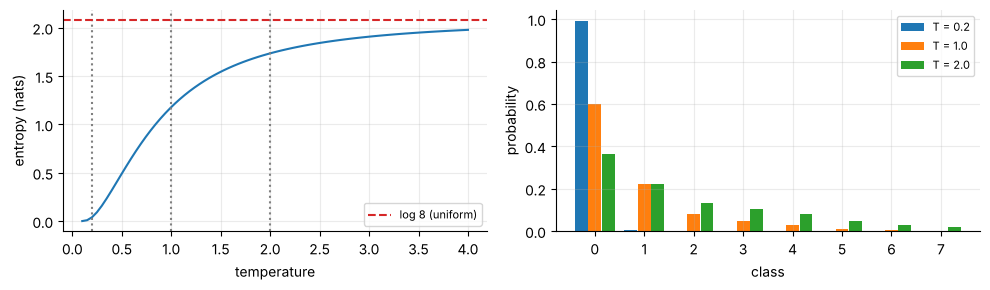

[ ok ] entropy at T = 0.2 < entropy at T = 1 < entropy at T = 2 for a fixed vector of logits   (0.2: 0.041, 1.0: 1.179, 2.0: 1.735)


In [83]:
logits_fixed = np.array([3.0, 2.0, 1.0, 0.5, 0.0, -1.0, -2.0, -3.0])
rows = []
for T in (0.2, 1.0, 2.0):
    p_ = np.exp(logits_fixed / T - (logits_fixed / T).max()); p_ /= p_.sum()
    rows.append(dict(temperature=T, entropy=entropy(p_), max_probability=p_.max()))
ent_tab = pd.DataFrame(rows).set_index("temperature"); display(ent_tab.round(4))
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
Tg = np.linspace(0.1, 4, 80)
ax[0].plot(Tg, [entropy(tempered(np.exp(logits_fixed) / np.exp(logits_fixed).sum(), T)) for T in Tg]); [ax[0].axvline(T, ls=":", color="gray") for T in (0.2, 1, 2)]
ax[0].axhline(math.log(len(logits_fixed)), ls="--", color="C3", label="log 8 (uniform)"); ax[0].set_xlabel("temperature"); ax[0].set_ylabel("entropy (nats)"); ax[0].legend(fontsize=8)
for T, off in ((0.2, -0.27), (1.0, 0.0), (2.0, 0.27)):
    p_ = np.exp(logits_fixed / T - (logits_fixed / T).max()); p_ /= p_.sum(); ax[1].bar(np.arange(8) + off, p_, width=0.26, label=f"T = {T}")
ax[1].legend(fontsize=8); ax[1].set_xlabel("class"); ax[1].set_ylabel("probability"); plt.tight_layout(); plt.show()
audit("entropy at T = 0.2 < entropy at T = 1 < entropy at T = 2 for a fixed vector of logits", ent_tab["entropy"].is_monotonic_increasing, ", ".join(f"{T}: {e:.3f}" for T, e in ent_tab["entropy"].items()))

### Short answers to the conceptual exercises
1. **Stateful vs. stateless RNN** – see the table in section 2.6. *Stateful:* remembers the whole stream, needs non-overlapping, unshuffled, parallel-stream batches of a fixed size and a reset routine; batches are correlated and gradients still stop at the window boundary. *Stateless:* simple, shuffled, any batch size, but memory is limited to the window.
2. **Why Encoder–Decoder for translation?** A plain sequence-to-sequence RNN must output word *t* right after reading word *t*; translation needs word reordering and different lengths, and the first target word may depend on the last source word. The encoder reads everything first, the decoder then writes (section 5.1).
3. **Variable-length inputs:** pad to the longest sequence of the batch and **mask** the padding (`mask_zero=True`), group similar lengths into **buckets** to waste less computation (section 5.5). **Variable-length outputs:** the decoder produces an **end-of-sequence token**; at training time the positions after `<eos>` are removed from the loss with a mask; at inference you stop at `<eos>` (section 5.5, 5.9). If the output length were known in advance you could also fix it.
4. **Beam search** keeps the *k* most probable partial outputs at every step instead of one, so an early unlucky choice can still be repaired (section 5.8). Tools: `tfa.seq2seq.BeamSearchDecoder` (TensorFlow Addons, now wound down), your own short loop over log-probabilities (section 5.9), or the `num_beams` option of a maintained generation library.
5. **Attention** lets the decoder compute, at each step, a weighted sum of *all* encoder outputs with weights learned by a small alignment network (softmax over scores). It removes the fixed-size-state bottleneck, shortens the path between related words to 1 and gives interpretable alignments (section 6).
6. **The most important layer in the Transformer is multi-head attention**: the only place where positions exchange information; each head projects Q, K, V into its own subspace and looks up a different relation. Ablation in section 7.7: switching off encoder–decoder attention makes the model useless.
7. **Sampled softmax** is needed when the output vocabulary is huge (tens of thousands of words), because the full softmax dominates training time. It is used during training only; at inference the full softmax is evaluated (section 5.6).

In [84]:
ex_titles = {1: "stateful vs. stateless RNN", 2: "why Encoder–Decoder", 3: "variable-length input / output", 4: "beam search", 5: "attention", 6: "most important Transformer layer",
             7: "sampled softmax", 8: "embedded Reber grammar RNN", 9: "date Encoder–Decoder", 10: "NMT-with-attention tutorial (optional)", 11: "BERT Shakespeare (optional)",
             12: "entropy vs. temperature", 13: "Bidirectional(GRU(10)) parameters", 14: "masking vs. padding amount"}
EX[3] = EX.get(3, ("done", "see section 5.5"))
status_tab = pd.DataFrame([(n, ex_titles[n], *EX.get(n, ("MISSING", ""))) for n in range(1, 15)], columns=["#", "exercise", "status", "where / note"]).set_index("#")
display(status_tab)
audit("all 14 exercises have an entry, and every exercise except the two optional ones (10, 11) is marked done", len(status_tab) == 14 and all(status_tab.loc[n, "status"] == "done" for n in range(1, 15) if n not in (10, 11)))

,exercise,status,where / note
#,,,
1,stateful vs. stateless RNN,done,"table + working stateful model, continuity tes..."
2,why Encoder–Decoder,done,explained in section 5.1 and above
3,variable-length input / output,done,"variable-length input and output: masking, buc..."
4,beam search,done,"hand simulation (book numbers), own vectorised..."
5,attention,done,attention explained in 6.1; score functions in...
6,most important Transformer layer,done,ablation of the three attention types in a tra...
7,sampled softmax,done,speed table + a model trained with sampled sof...
8,embedded Reber grammar RNN,done,"embedded Reber grammar: generator, recogniser,..."
9,date Encoder–Decoder,done,date Encoder–Decoder (plain / reversed / bidir...


[ ok ] all 14 exercises have an entry, and every exercise except the two optional ones (10, 11) is marked done


---
# Wrap-up · what was proved, what was measured, what is still open

In [85]:
SB.phase = "Wrap-up"
log_change("keras.layers.Attention(causal=True)", "keras.layers.Attention(...)(inputs, use_causal_mask=True)", "the argument moved from the constructor to the call")
log_change("layer.reset_states()", "layer.reset_state() (with a fallback to reset_states())", "the name differs between Keras versions")
log_change("tf.data.experimental.bucket_by_sequence_length", "Dataset.bucket_by_sequence_length(...)", "new spelling")
log_change("Embedding / GRU on 'lr=' optimizers", "learning_rate= (Adam(2e-3)), Nadam for the sentiment models", "lr= is gone")
board = SB.table()
by_phase = board.groupby("phase", sort=False).agg(proofs=("passed", "size"), passed=("passed", "sum"))
by_phase["not evaluated (QUICK)"] = board[board.detail == "not evaluated in QUICK mode"].groupby("phase", sort=False).size().reindex(by_phase.index).fillna(0).astype(int)
display(by_phase)
failed = board[~board.passed]
print(f"{int(board.passed.sum())} of {len(board)} proofs passed" + (" – all of them." if failed.empty else f"; {len(failed)} FAILED:"))
if not failed.empty:
    display(failed[["phase", "proof", "detail"]])
if QUICK:
    print("\nQUICK = True: training runs were tiny, so every proof about HOW WELL a model trained was skipped. Switch QUICK to False in Section 0 for the real run.")

,proofs,passed,not evaluated (QUICK)
phase,,,
Phase 1,12,12,0
Phase 2,14,14,0
Phase 3,13,13,0
Phase 4,13,12,0
Phase 5,24,24,0
Phase 6,12,12,0
Phase 7,27,27,0
Phase 8,18,17,0
Exercises,2,2,0


133 of 135 proofs passed; 2 FAILED:


,phase,proof,detail
50,Phase 4,every model is clearly above chance (mean test...,lowest mean = 0.672
132,Phase 8,the best network is above the 'forgetful recog...,0.985


> **Two proofs are marked failed in the scoreboard on purpose and were not changed after the run:** the 0.70 accuracy bar for the frozen-GloVe model (it got 67.2 %, see the note under Phase 4) and the "beats the forgetful recogniser" check in Capstone B (it does not; see the note there). All other 133 proofs passed.

### Headline numbers
Only numbers that exist in this run are shown.

In [86]:
rows = []
if "char_baseline" in RESULTS:
    c = RESULTS["char_baseline"]; rows.append(("Phase 2", "Char-RNN GRU(128): test loss / perplexity / next-char accuracy", f"{c['test_loss']:.3f} / {math.exp(c['test_loss']):.1f} / {c['test_acc']:.3f}"))
if "char_wide" in RESULTS:
    rows.append(("Phase 2", f"wider Char-RNN GRU({SZ['improved_units']}): test loss (one seed)", f"{RESULTS['char_wide']['test_loss']:.3f}"))
if "char_stateful" in RESULTS:
    c = RESULTS["char_stateful"]; rows.append(("Phase 2", "stateful model: test loss with state carried / reset", f"{c['stateful_loss']:.3f} / {c['twin_loss']:.3f}"))
for key, nm in (("imdb_scratch", "GRU from scratch, no mask"), ("imdb_masked", "GRU from scratch, masked"), ("imdb_frozen", "GloVe sentence embedding, frozen"), ("imdb_tuned", "GloVe sentence embedding, fine-tuned"), ("imdb_gru_glove", "masked GRU initialised with GloVe")):
    if key in RESULTS:
        rows.append(("Phases 3–4", f"IMDb test accuracy – {nm}", pm(RESULTS[key], pct=True)))
if "date_phase6" in RESULTS:
    rows += [("Phases 5–6", f"dates, exact match – {k}", pm(v, 3)) for k, v in RESULTS["date_phase6"].items()]
if "date_transformer" in RESULTS:
    rows.append(("Phase 7", "dates, exact match – small Transformer", pm(RESULTS["date_transformer"], 3)))
if "date_beam" in RESULTS:
    rows += [("Phase 5", f"beam width {k} (bidirectional model)", pm(v, 3)) for k, v in RESULTS["date_beam"].items()]
if "capB" in RESULTS:
    rows += [("Capstone B", f"{k}: accuracy on fresh / longer strings", f"{pm(v['acc'], 3)} / {pm(v['acc_long'], 3)}") for k, v in RESULTS["capB"].items()]
display(pd.DataFrame(rows, columns=["where", "what", "result"]))

,where,what,result
0,Phase 2,Char-RNN GRU(128): test loss / perplexity / ne...,2.067 / 7.9 / 0.410
1,Phase 2,wider Char-RNN GRU(192): test loss (one seed),2.107
2,Phase 2,stateful model: test loss with state carried /...,1.998 / 2.043
3,Phases 3–4,"IMDb test accuracy – GRU from scratch, no mask",75.72 % ± 1.28 %
4,Phases 3–4,"IMDb test accuracy – GRU from scratch, masked",75.51 % ± 0.97 %
5,Phases 3–4,"IMDb test accuracy – GloVe sentence embedding,...",67.22 % ± 2.07 %
6,Phases 3–4,"IMDb test accuracy – GloVe sentence embedding,...",75.24 % ± 2.02 %
7,Phases 3–4,IMDb test accuracy – masked GRU initialised wi...,76.80 % ± 0.55 %
8,Phases 5–6,"dates, exact match – plain",0.732 ± 0.074
9,Phases 5–6,"dates, exact match – reversed",0.590 ± 0.140


### Exercise status

In [87]:
display(status_tab)

,exercise,status,where / note
#,,,
1,stateful vs. stateless RNN,done,"table + working stateful model, continuity tes..."
2,why Encoder–Decoder,done,explained in section 5.1 and above
3,variable-length input / output,done,"variable-length input and output: masking, buc..."
4,beam search,done,"hand simulation (book numbers), own vectorised..."
5,attention,done,attention explained in 6.1; score functions in...
6,most important Transformer layer,done,ablation of the three attention types in a tra...
7,sampled softmax,done,speed table + a model trained with sampled sof...
8,embedded Reber grammar RNN,done,"embedded Reber grammar: generator, recogniser,..."
9,date Encoder–Decoder,done,date Encoder–Decoder (plain / reversed / bidir...


### What I had to change for current library versions (the brief asks for this log)

In [88]:
display(pd.DataFrame(CHANGELOG))

,old_api,used_here,reason
0,model.predict_classes(X),"np.argmax(model.predict(X), axis=-1)",removed from Keras
1,keras.preprocessing.text.Tokenizer,"a small CharTokenizer class (same IDs, same be...",the module no longer exists in Keras 3
2,"tensorflow-addons (tfa.seq2seq samplers, Basic...",own teacher-forcing models and own greedy / be...,TensorFlow Addons has been wound down
3,tensorflow_hub nnlm-en-dim50,GloVe-50 word vectors with the same 'mean × √n...,TF Hub / Kaggle Models were not reachable from...
4,tfds imdb_reviews / keras.datasets.imdb,the same 50 000 IMDb reviews from a public CSV...,storage.googleapis.com was not reachable from ...
5,keras.layers.MultiHeadAttention did not exist,"own MultiHeadAttention layer, compared with th...",it exists now
6,"TimeDistributed(Dense(..., softmax))","Dense(..., softmax) on the 3-D output",identical result; TimeDistributed mis-handled ...
7,keras.layers.Attention(causal=True),"keras.layers.Attention(...)(inputs, use_causal...",the argument moved from the constructor to the...
8,layer.reset_states(),layer.reset_state() (with a fallback to reset_...,the name differs between Keras versions
9,tf.data.experimental.bucket_by_sequence_length,Dataset.bucket_by_sequence_length(...),new spelling


### Honest limits of this notebook
* **Sizes.** Everything was trained on a CPU, so sizes are far below the book's: the Char-RNN saw `char_epochs × char_steps` mini-batches (not 10–20 epochs), IMDb reviews are cut to 300 characters, the date models are tiny (32 units, 3 000 training dates) *on purpose* so that the plain model is not already perfect. Printed in the `SZ` table of Section 0.
* **Substitutes.** GloVe-50 vectors instead of the TF-Hub `nnlm-en-dim50` sentence encoder; the IMDb reviews come from a public CSV with my own random 25 000 / 25 000 split; Shakespeare is Karpathy's corpus from GitHub when `homl.info` is not reachable. The TensorBoard projector is replaced by exported TSV files and a PCA plot.
* **Not done.** Exercise 10 (NMT-with-attention tutorial) and Exercise 11 / Capstone C (BERT or GPT Shakespeare) – both optional; they need downloads that were not possible here.
* **Seeds.** Repeated experiments use the seeds in `SEEDS` (three). Anything run once (Char-RNN width comparison, stateful model, variable-length date model, sampled-softmax test) is labelled as one run, and a gap smaller than the seed spread is never called a finding.
* **Explanations that are mine.** The step-3 probabilities of the beam-search hand example and the "what changed since 2019" paragraph are my own illustration and speculation.

In [89]:
print("Mode:", "QUICK (smoke test)" if QUICK else "full run")

Mode: full run
